# DataVinci: Sentiment in stock market crash tweets

DSAI4205 Big Data Analytics · Dataset 3

We classify the supplied tweets as neutral, positive or negative.

**What Run All does.** With the switches at the end left off, the notebook checks the data and folds, fits both TF-IDF baselines, checks the saved scores and predictions, and recalculates the fusion. Retraining the six classifiers is optional. The saved model rows therefore describe the runs used in our comparison rather than models trained during this session.

The setup cells package the source and data so this file can run on its own. Start at [Data and EDA](#Data-and-EDA) to read the analysis, or go straight to [Development results](#Development-results) for the comparison.

## Setup

Use Python 3.11 with the packages below. The setup cells write the bundled source and data into a temporary directory. They can be collapsed when reading the notebook. The [retraining section](#Retraining) explains the switches and the SBERT cache.

```text
numpy==1.26.4 scipy==1.13.1 pandas==2.2.3 scikit-learn==1.5.2
matplotlib==3.9.2 nltk==3.9.1 ftfy==6.3.1 langdetect==1.0.9
vaderSentiment==3.3.2 textblob==0.18.0 gensim==4.3.3
xgboost==2.1.3 imbalanced-learn==0.12.4 torch==2.5.1
transformers==4.46.3 sentence-transformers==3.3.1
```

In [1]:
from pathlib import Path
import os
import sys
import tempfile

ROOT = Path(tempfile.mkdtemp(prefix="datavinci-"))
os.environ["DATA_ROOT"] = str(ROOT / "data")
sys.path.insert(0, str(ROOT))

def write_source(relative_path, source):
    path = ROOT / relative_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(source, encoding="utf-8")


### Project configuration and shared APIs

In [2]:
write_source('src/__init__.py', '')

In [3]:
write_source('src/cache.py', r''''Save embeddings and align arrays by tweet ID.'


















from __future__ import annotations

import numpy as np

from .config import EMB_DIR, LABELS, PRED_DIR, VERSION_TAGS

LABEL_IDS = list(LABELS)
N_CLASSES = len(LABEL_IDS)


def save_embedding(name: str, ids, matrix) -> None:
    ''
    ids, matrix = np.asarray(ids), np.asarray(matrix)
    if len(ids) != len(matrix):
        raise ValueError(f"ids 有 {len(ids)} 行，matrix 有 {len(matrix)} 行，行数必须一致")
    EMB_DIR.mkdir(parents=True, exist_ok=True)
    np.save(EMB_DIR / f"{name}.npy", matrix)
    np.save(EMB_DIR / f"{name}_ids.npy", ids)


def load_embedding(name: str, ids=None):
    ''
    matrix = np.load(EMB_DIR / f"{name}.npy")
    cached_ids = np.load(EMB_DIR / f"{name}_ids.npy")
    if ids is None:
        return cached_ids, matrix
    position = {int(i): k for k, i in enumerate(cached_ids)}
    missing = [int(i) for i in ids if int(i) not in position]
    if missing:
        raise KeyError(f"{name} 里缺少 {len(missing)} 个 id，例如 {missing[:5]}")
    return matrix[[position[int(i)] for i in ids]]


def save_preds(run_id: str, *, oof_ids, oof_proba, test_ids, test_proba, classes) -> None:
    ''




    classes = [int(c) for c in classes]
    if sorted(classes) != LABEL_IDS:
        raise ValueError(f"classes 应该恰好包含 {LABEL_IDS}，收到的是 {classes}")
    order = [classes.index(label) for label in LABEL_IDS]

    arrays = {}
    for part, ids, proba in (("oof", oof_ids, oof_proba), ("test", test_ids, test_proba)):
        proba = np.asarray(proba, dtype=float)
        if proba.shape != (len(ids), N_CLASSES):
            raise ValueError(f"{part} 概率的形状应为 ({len(ids)}, {N_CLASSES})，实际是 {proba.shape}")
        arrays[f"{part}_ids"] = np.asarray(ids)
        arrays[f"{part}_proba"] = proba[:, order]

    path = PRED_DIR / f"{run_id}.npz"
    if path.exists():
        raise FileExistsError(f"{path.name} 已存在：每次实验请用 new_run_id() 生成新的 run_id")
    PRED_DIR.mkdir(parents=True, exist_ok=True)
    np.savez(path, **arrays, classes=np.asarray(LABEL_IDS), run_id=run_id, **VERSION_TAGS)


def load_preds(run_id: str) -> dict:
    ''
    with np.load(PRED_DIR / f"{run_id}.npz") as f:
        return {key: f[key].item() if f[key].ndim == 0 else f[key] for key in f.files}


def list_preds() -> list[str]:
    ''
    return sorted(p.stem for p in PRED_DIR.glob("*.npz"))
''')

In [4]:
write_source('src/cleaning.py', r'''''
























from __future__ import annotations

import html
import re
import warnings
from collections import Counter

import pandas as pd

from .config import PROJECT_ROOT

UNK = "[UNK]"  
V1_COLUMNS = ["id", "group_id", "text_raw", "text_full", "text_light", "label"]  
NLTK_DIR = PROJECT_ROOT / "data" / "nltk_data"  
NLTK_PACKAGES = ("stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng")

# ---------------------------------------------------------------------------

# ---------------------------------------------------------------------------


def fix_encoding(text: str) -> str:
    ''
    import ftfy

    return html.unescape(ftfy.fix_text(text))


def replace_mentions(text: str) -> str:
    ''
    return re.sub(r"@\w+", "@user", text)


# ---------------------------------------------------------------------------


# ---------------------------------------------------------------------------

NEGATION_STEMS = ("don", "doesn", "didn", "isn", "aren", "wasn", "weren", "hasn", "haven", "hadn",
                  "couldn", "shouldn", "wouldn", "won", "can", "ain", "mustn", "needn")
S_STEMS = ("it", "that", "what", "there", "let", "he", "she", "who", "how", "here", "where")
LL_STEMS = ("i", "you", "we", "they", "he", "she", "it", "that", "there")

PARTICIPLES = {"been", "got", "gotten", "lost", "seen", "done", "had", "made", "broken", "taken", "given",
               "known", "become", "gone", "bought", "held", "paid", "felt", "heard", "left", "told",
               "thought", "kept", "begun", "fallen", "grown", "shown", "written", "chosen", "missed"}
SKIPPABLE_ADVERBS = {"already", "just", "never", "ever", "finally", "all", "really", "also", "probably", "definitely"}

_W = r"(?=[^A-Za-z0-9_]|$)"  
CONTRACTION_RULES = [
    ("n't", re.compile(rf"\b({'|'.join(NEGATION_STEMS)})__{_W}", re.I), lambda m: m.group(1) + "'t"),
    ("I'm", re.compile(rf"\b(i)__{_W}", re.I), lambda m: m.group(1) + "'m"),
    ("'s", re.compile(rf"\b({'|'.join(S_STEMS)})__{_W}", re.I), lambda m: m.group(1) + "'s"),
    ("'ll", re.compile(rf"\b({'|'.join(LL_STEMS)})__l{_W}", re.I), lambda m: m.group(1) + "'ll"),
    ("I've", re.compile(rf"\b(i)__e{_W}", re.I), lambda m: m.group(1) + "'ve"),
    ("y'all", re.compile(rf"\b(y)__ll{_W}", re.I), lambda m: m.group(1) + "'all"),
]
RE_VE_RULE = re.compile(r"\b(you|we|they)__e\b", re.I)


def _re_or_ve(match: re.Match) -> str:
    ''
    following = re.findall(r"[A-Za-z]+", match.string[match.end():match.end() + 60])
    words = [w.lower() for w in following]
    while words and words[0] in SKIPPABLE_ADVERBS:
        words.pop(0)
    nxt = words[0] if words else ""
    is_participle = nxt in PARTICIPLES or (len(nxt) > 3 and nxt.endswith("ed"))
    return match.group(1) + ("'ve" if is_participle else "'re")


def restore_contractions(text: str) -> tuple[str, Counter]:
    ''
    hits = Counter()
    for name, pattern, repl in CONTRACTION_RULES:
        text, n = pattern.subn(repl, text)
        hits[name] += n
    text, n = RE_VE_RULE.subn(_re_or_ve, text)
    hits["'re/'ve"] += n
    return text, hits




_LATIN1_RUN = re.compile("[\u0080-ÿ]+")


def _is_residue(run: str) -> bool:
    has_c1 = any("\u0080" <= ch <= "\u009f" for ch in run)
    has_symbol = any(" " <= ch <= "¿" for ch in run)
    return has_c1 or (len(run) >= 2 and has_symbol)


def count_residue(text: str) -> int:
    ''
    return sum(_is_residue(m.group()) for m in _LATIN1_RUN.finditer(text))


def mark_unknown(text: str) -> tuple[str, int]:
    ''



    text = re.sub(r"(?<=[A-Za-z0-9])_(?=[A-Za-z0-9])", " ", text)
    text, n_underscore = re.subn(r"_+", f" {UNK} ", text)
    n_residue = count_residue(text)
    text = _LATIN1_RUN.sub(lambda m: f" {UNK} " if _is_residue(m.group()) else m.group(), text)
    text = re.sub(rf"(?:\s*{re.escape(UNK)})+", f" {UNK}", text)
    return text, n_underscore + n_residue


def is_unreadable(text: str, min_residue: int = 2, min_words: int = 4) -> bool:
    ''




    residue = count_residue(text)
    body = re.sub(r"[#@]\w+", " ", text)
    words = re.findall(r"\b[A-Za-z]{2,}\b", body)
    return residue >= min_residue and len(words) < min_words


# ---------------------------------------------------------------------------

# ---------------------------------------------------------------------------


def normalize_hashtags(text: str) -> str:
    ''



    def split(match: re.Match) -> str:
        return " " + re.sub(r"(?<=[a-z])(?=[A-Z])", " ", match.group(1))

    return re.sub(r"#(\w+)", split, text)


def normalize_whitespace(text: str) -> str:
    ''
    return " ".join(text.split())


def content_key(text: str) -> str:
    ''
    text = text.lower().replace("@user", " ").replace(UNK.lower(), " ")
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text).split())


# ---------------------------------------------------------------------------

# ---------------------------------------------------------------------------


def detect_language(text: str, min_letters: int = 15) -> str:
    ''
    from langdetect import DetectorFactory, LangDetectException, detect

    DetectorFactory.seed = 0  
    body = re.sub(r"#\w+|@user|\[UNK\]", " ", text)
    if sum(ch.isalpha() for ch in body) < min_letters:
        return "und"
    try:
        return detect(body)
    except LangDetectException:
        return "und"
    except TypeError as err:  
        warnings.warn(f"langdetect 内部错误，按 und 处理：{err!r}，文本：{body[:60]!r}")
        return "und"


# ---------------------------------------------------------------------------

# ---------------------------------------------------------------------------

NEGATIONS = {"no", "not", "nor", "never", "none", "nothing", "nobody", "neither", "nowhere", "cannot"}
_CONTRACTION_EXPANSIONS = [
    (r"\bcan't\b", "can not"), (r"\bwon't\b", "will not"), (r"\bain't\b", "is not"),
    (r"n't\b", " not"), (r"'re\b", " are"), (r"'m\b", " am"), (r"'ll\b", " will"),
    (r"'ve\b", " have"), (r"'d\b", " would"), (r"'s\b", ""),
]


def setup_nltk() -> None:
    ''
    import nltk

    NLTK_DIR.mkdir(parents=True, exist_ok=True)
    if str(NLTK_DIR) not in nltk.data.path:
        nltk.data.path.insert(0, str(NLTK_DIR))
    for package in NLTK_PACKAGES:
        nltk.download(package, download_dir=str(NLTK_DIR), quiet=True)


def _wordnet_pos(tag: str) -> str:
    return {"J": "a", "V": "v", "R": "r"}.get(tag[:1], "n")


class FullTextBuilder:
    ''

    def __init__(self):
        from nltk import pos_tag
        from nltk.corpus import stopwords
        from nltk.stem import WordNetLemmatizer

        setup_nltk()
        self._pos_tag = pos_tag
        self._lemmatizer = WordNetLemmatizer()
        self.stopwords = set(stopwords.words("english")) - NEGATIONS

    def __call__(self, text_light: str) -> str:
        text = text_light.replace("’", "'").lower()
        text = text.replace("@user", " ").replace(UNK.lower(), " unk ")
        for pattern, repl in _CONTRACTION_EXPANSIONS:
            text = re.sub(pattern, repl, text)
        tokens = re.findall(r"[a-z]+", text)  
        if not tokens:
            return ""
        lemmas = [self._lemmatizer.lemmatize(tok, _wordnet_pos(tag)) for tok, tag in self._pos_tag(tokens)]
        return " ".join(w for w in lemmas if len(w) > 1 and w not in self.stopwords)


# ---------------------------------------------------------------------------

# ---------------------------------------------------------------------------


def near_duplicate_groups(ids, keys, threshold: float = 0.7, min_tokens: int = 5) -> dict:
    ''




    ids = list(ids)
    parent = {i: i for i in ids}

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    token_sets = [set(k.split()) for k in keys]
    candidates = [(i, s) for i, s in zip(ids, token_sets) if len(s) >= min_tokens]
    for a in range(len(candidates)):
        id_a, set_a = candidates[a]
        for b in range(a + 1, len(candidates)):
            id_b, set_b = candidates[b]
            inter = len(set_a & set_b)
            if inter and inter / len(set_a | set_b) >= threshold:
                parent[find(id_b)] = find(id_a)

    groups = {}
    for i in ids:
        groups.setdefault(find(i), []).append(i)
    return {i: min(members) for members in groups.values() for i in members}


# ---------------------------------------------------------------------------

# ---------------------------------------------------------------------------


def _short(text: str, n: int = 70) -> str:
    text = str(text).replace("\n", " ⏎ ")
    return text if len(text) <= n else text[:n] + "…"


def run_cleaning(raw: pd.DataFrame) -> tuple[pd.DataFrame, list[dict], pd.DataFrame]:
    ''






    log, dropped = [], []
    df = raw[["id", "text", "label"]].rename(columns={"text": "text_raw"}).copy()

    def record(operation, rationale, affected=0, example="", details=""):
        log.append({"step": len(log), "operation": operation, "rationale": rationale,
                    "rows_affected": int(affected), "rows_remaining": len(df),
                    "example": example, "details": details})

    def change_example(before: pd.Series, after: pd.Series) -> tuple[int, str]:
        ''
        changed = before != after
        if not changed.any():
            return 0, ""
        i = changed[changed].index[0]
        a, b = before[i], after[i]
        start = next((k for k in range(min(len(a), len(b))) if a[k] != b[k]), min(len(a), len(b)))
        start = max(0, start - 20)
        prefix = "…" if start else ""
        return int(changed.sum()), f"{prefix}{_short(a[start:], 55)} → {prefix}{_short(b[start:], 55)}"

    def drop(mask: pd.Series, reason: str) -> pd.DataFrame:
        nonlocal df
        removed = df[mask]
        dropped.append(removed[["id", "text_raw", "label"]].assign(reason=reason))
        df = df[~mask].copy()
        return removed

    record("Load raw data", "Original CSV; one row is one tweet; id = row number in the raw file")

    removed = drop(df.duplicated("text_raw", keep="first"), "exact duplicate")
    record("Remove exact duplicates", "The same tweet text appears more than once (labels agree); first copy kept",
           len(removed), _short(removed["text_raw"].iloc[0]) if len(removed) else "")

    df["fixed"] = df["text_raw"].map(fix_encoding)
    n, ex = change_example(df["text_raw"], df["fixed"])
    record("Repair encoding and HTML entities",
           "Double-encoded UTF-8 repaired with ftfy (estÃ©s → estés); HTML entities unescaped (&amp; → &)", n, ex)

    df["text"] = df["fixed"].map(replace_mentions)
    n, ex = change_example(df["fixed"], df["text"])
    record("Replace user mentions", "@username → @user: names carry no sentiment and often contain underscores", n, ex)

    before = df["text"]
    restored = before.map(restore_contractions)
    df["text"] = restored.map(lambda r: r[0])
    df["n_restored"] = restored.map(lambda r: sum(r[1].values()))
    hits = sum((r[1] for r in restored), Counter())
    n, ex = change_example(before, df["text"])
    record("Restore verified contractions",
           "In the source file the apostrophe ’ and the next character became '__' (it’s → it__, you’re → you__e). "
           "Only patterns checked by hand against every occurrence are restored",
           n, ex, ", ".join(f"{k}: {v}" for k, v in hits.most_common()))

    removed = drop(df["fixed"].map(is_unreadable), "unreadable mojibake")
    record("Remove unreadable tweets",
           "Non-Latin scripts whose original bytes were lost in the source file (ftfy cannot repair them): "
           "≥ 2 mojibake residues and < 4 readable words",
           len(removed), _short(removed["text_raw"].iloc[0]) if len(removed) else "")

    before = df["text"]
    marked = before.map(mark_unknown)
    df["text"] = marked.map(lambda r: r[0])
    df["n_unk"] = marked.map(lambda r: r[1])
    n, ex = change_example(before, df["text"])
    record(f"Replace unrecoverable characters with {UNK}",
           "Remaining '__' runs (emoji, symbols or possessive 's, which cannot be told apart) and leftover mojibake",
           n, ex, f"{int(df['n_unk'].sum())} replacements")

    df["lang"] = df["text"].map(detect_language)
    counts = df["lang"].value_counts()
    record("Detect language (flag only)",
           "langdetect on the tweet body without hashtags and mentions; < 15 letters → 'und'. "
           "Readable non-English tweets are kept and flagged in the lang column",
           int((df["lang"] != "en").sum()), "",
           ", ".join(f"{k}: {v}" for k, v in counts.head(8).items()))

    before = df["text"]
    df["text_light"] = before.map(normalize_hashtags).map(normalize_whitespace)
    n, ex = change_example(before, df["text_light"])
    record("Normalise hashtags and whitespace",
           "Remove '#', split CamelCase hashtags (#StockMarketCrash → Stock Market Crash); merge newlines and spaces",
           n, ex)

    key = df["text_light"].map(content_key)
    conflicting = key.map(df.groupby(key)["label"].nunique()) > 1
    removed_conflict = drop(conflicting, "content duplicate with conflicting labels")
    key = key[~conflicting]
    removed = drop(key.duplicated(keep="first"), "content duplicate")
    record("Remove content duplicates",
           "Tweets identical after lowercasing and removing mentions, placeholders and punctuation "
           "(e.g. '@user #bearmarket' vs '#bearmarket'); first copy kept",
           len(removed) + len(removed_conflict), _short(removed["text_raw"].iloc[0]) if len(removed) else "",
           f"{len(removed_conflict)} rows with conflicting labels removed" if len(removed_conflict) else "")

    builder = FullTextBuilder()
    df["text_full"] = df["text_light"].map(builder)
    i = df.index[0]
    record("Build text_full",
           "Expand contractions (don't → do not), lowercase, keep letters only (drops punctuation and digits), "
           "POS-aware WordNet lemmatisation, remove NLTK stopwords except negations (no, not, never…)",
           len(df), f"{_short(df.at[i, 'text_light'])} → {_short(df.at[i, 'text_full'])}")

    no_words = df["text_full"].map(lambda s: not [w for w in s.split() if w != "unk"])
    removed = drop(no_words, "no words left")
    record("Remove tweets with no words left", "Only mentions, emoji or symbols remained; nothing to classify",
           len(removed), _short(removed["text_raw"].iloc[0]) if len(removed) else "")

    keys = df["text_light"].map(content_key)
    groups = near_duplicate_groups(df["id"], keys)
    df["group_id"] = df["id"].map(groups)
    sizes = df["group_id"].map(df["group_id"].value_counts())
    in_groups = int((sizes > 1).sum())
    record("Group near-duplicates",
           "Token Jaccard ≥ 0.7 (tweets with ≥ 5 tokens) on the content key; a group must stay in one fold",
           in_groups, "", f"{df.loc[sizes > 1, 'group_id'].nunique()} groups")

    clean = df[V1_COLUMNS + ["lang", "n_restored", "n_unk"]].reset_index(drop=True)
    record("Final dataset", "Columns: " + ", ".join(clean.columns))
    dropped_rows = pd.concat(dropped, ignore_index=True) if dropped else pd.DataFrame()
    return clean, log, dropped_rows


def log_to_markdown(log: list[dict], title: str = "Data cleaning log", notes: list[str] | None = None) -> str:
    ''
    def cell(value) -> str:
        return str(value).replace("|", r"\|").replace("\n", " ")

    lines = [f"# {title}", "",
             "| Step | Operation | Rationale | Rows affected | Rows remaining | Example (before → after) | Details |",
             "|---|---|---|---|---|---|---|"]
    for r in log:
        lines.append("| " + " | ".join(cell(r[k]) for k in
                     ("step", "operation", "rationale", "rows_affected", "rows_remaining", "example", "details")) + " |")
    if notes:
        lines += ["", "## Notes", ""] + [f"- {note}" for note in notes]
    return "\n".join(lines) + "\n"
''')

In [5]:
write_source('src/config.py', r''''Paths, labels and the frozen experiment versions.'




import os
from pathlib import Path

PROJECT_ROOT = Path(__file__).resolve().parents[1]  


CLEAN_VERSION = 2  
SPLIT_VERSION = 1  



DATA_ROOT = Path(os.environ.get("DATA_ROOT", PROJECT_ROOT / "data"))
RAW_CSV = DATA_ROOT / "raw" / "stock_market_crash_2022.csv"  
CLEAN_DIR = DATA_ROOT / f"clean_v{CLEAN_VERSION}"  
EMB_DIR = DATA_ROOT / "emb"      
PRED_DIR = DATA_ROOT / "preds"   


SPLITS_DIR = PROJECT_ROOT / "splits"    
RESULTS_DIR = PROJECT_ROOT / "results"  
FIGURES_DIR = PROJECT_ROOT / "figures"  


SEED = 42        
N_FOLDS = 5      
TEST_SIZE = 0.2  


LABELS = {0: "Neutral", 1: "Positive", 2: "Negative"}


VERSION_TAGS = {
    "data_version": f"clean_v{CLEAN_VERSION}",
    "split_version": f"folds_v{SPLIT_VERSION}",
    "seed": SEED,
}
''')

In [6]:
write_source('src/data.py', r''''Load and validate the dataset and grouped folds.'















from __future__ import annotations

import pandas as pd

from .config import DATA_ROOT, CLEAN_VERSION, LABELS, N_FOLDS, RAW_CSV, SPLIT_VERSION, SPLITS_DIR

CLEAN_COLUMNS = ["id", "group_id", "text_raw", "text_clean", "text_norm", "label"]
SPLIT_COLUMNS = ["id", "group_id", "split", "fold"]


def load_raw() -> pd.DataFrame:
    ''
    df = pd.read_csv(RAW_CSV, encoding="utf-8")
    df = df.rename(columns={"text_sentiment": "label"})
    df.insert(0, "id", range(len(df)))
    return df


def load_clean(version: int = CLEAN_VERSION) -> pd.DataFrame:
    ''
    df = pd.read_csv(DATA_ROOT / f"clean_v{version}" / f"clean_v{version}.csv", encoding="utf-8")
    check_clean(df)
    return df


def load_splits(version: int = SPLIT_VERSION, clean: pd.DataFrame | None = None) -> pd.DataFrame:
    ''
    splits = pd.read_csv(SPLITS_DIR / f"folds_v{version}.csv")
    check_splits(splits, clean)
    return splits


def _require_columns(df: pd.DataFrame, columns: list[str], what: str) -> None:
    missing = [c for c in columns if c not in df.columns]
    if missing:
        raise ValueError(f"{what}缺少列：{missing}")


def check_clean(df: pd.DataFrame) -> None:
    ''
    _require_columns(df, CLEAN_COLUMNS, "清洗数据")
    if not df["id"].is_unique:
        raise ValueError("清洗数据的 id 有重复")
    unknown = set(df["label"]) - set(LABELS)
    if unknown:
        raise ValueError(f"清洗数据出现未知标签：{sorted(unknown)}")
    for col in ("text_clean", "text_norm"):
        empty = df[col].isna() | (df[col].astype(str).str.strip() == "")
        if empty.any():
            raise ValueError(f"{col} 有 {int(empty.sum())} 行为空，清洗时应删除或处理")


def check_splits(splits: pd.DataFrame, clean: pd.DataFrame | None = None) -> None:
    ''
    _require_columns(splits, SPLIT_COLUMNS, "数据划分")
    if not splits["id"].is_unique:
        raise ValueError("数据划分的 id 有重复")
    if not splits["split"].isin(["train", "test"]).all():
        raise ValueError("split 列只能是 train 或 test")
    is_test = splits["split"] == "test"
    if not (splits.loc[is_test, "fold"] == -1).all():
        raise ValueError("测试集的 fold 必须是 -1")
    if not splits.loc[~is_test, "fold"].isin(range(N_FOLDS)).all():
        raise ValueError(f"训练集的 fold 必须在 0–{N_FOLDS - 1} 之间")
    crossing = splits.groupby("group_id")["fold"].nunique() > 1
    if crossing.any():
        raise ValueError(f"有 {int(crossing.sum())} 个 group_id 分散在不同的折或训练/测试集，近似重复的推文会泄露")
    if clean is None:
        return
    merged = clean[["id", "group_id"]].merge(
        splits[["id", "group_id"]], on="id", how="outer", suffixes=("_clean", "_split"), indicator=True
    )
    if (merged["_merge"] != "both").any():
        raise ValueError("划分和清洗数据的 id 不一致：清洗数据增删了行，必须重新生成划分并升级 SPLIT_VERSION")
    if (merged["group_id_clean"] != merged["group_id_split"]).any():
        raise ValueError("划分和清洗数据的 group_id 不一致：近似重复的分组改了，必须重新生成划分并升级 SPLIT_VERSION")
''')

In [7]:
write_source('src/evaluate.py', r''''Compute and save the scores reported in the notebook.'






















from __future__ import annotations

import json
import uuid
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
)

from .config import LABELS, RESULTS_DIR, VERSION_TAGS

LABEL_IDS = list(LABELS)
LABEL_NAMES = [LABELS[i] for i in LABEL_IDS]
SPLITS = ("cv", "test")


def new_run_id(model: str, embedding: str) -> str:
    ''
    return f"{model}__{embedding}__{datetime.now():%Y%m%d-%H%M%S}-{uuid.uuid4().hex[:4]}"


def evaluate(y_true, y_pred, *, run_id: str, model: str, embedding: str, split: str,
             params: dict | None = None, train_seconds: float | None = None, notes: str = "") -> dict:
    ''
    if split not in SPLITS:
        raise ValueError(f"split 只能是 {SPLITS}，收到的是 {split!r}")
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, labels=LABEL_IDS, average="macro", zero_division=0
    )
    per_class_f1 = f1_score(y_true, y_pred, labels=LABEL_IDS, average=None, zero_division=0)
    return {
        "run_id": run_id,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "model": model,
        "embedding": embedding,
        "split": split,
        **VERSION_TAGS,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
        **{f"f1_{name.lower()}": score for name, score in zip(LABEL_NAMES, per_class_f1)},
        "params": json.dumps(params or {}, sort_keys=True, default=str),
        "train_seconds": train_seconds,
        "notes": notes,
    }


def save_result(row: dict, file_stem: str) -> Path:
    ''
    RESULTS_DIR.mkdir(parents=True, exist_ok=True)
    path = RESULTS_DIR / f"{file_stem}.csv"
    new = pd.DataFrame([row])
    if path.exists():
        old = pd.read_csv(path)
        if ((old["run_id"] == row["run_id"]) & (old["split"] == row["split"])).any():
            raise ValueError(f"{path.name} 里已经有 run_id={row['run_id']}、split={row['split']} 的记录")
        new = pd.concat([old, new], ignore_index=True)
    new.to_csv(path, index=False)
    return path


def collect_results() -> pd.DataFrame:
    ''
    files = sorted(RESULTS_DIR.glob("*.csv"))
    if not files:
        return pd.DataFrame()
    return pd.concat([pd.read_csv(f).assign(source=f.stem) for f in files], ignore_index=True)


def best_runs(metric: str = "macro_f1", split: str = "cv") -> pd.DataFrame:
    ''
    table = collect_results()
    if table.empty:
        return table
    table = table[table["split"] == split]
    best = table.loc[table.groupby(["model", "embedding"])[metric].idxmax()]
    return best.sort_values(metric, ascending=False).reset_index(drop=True)


def plot_confusion(y_true, y_pred, title: str, save_as: Path | None = None):
    ''
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, labels=LABEL_IDS, display_labels=LABEL_NAMES,
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(title)
    fig.tight_layout()
    if save_as is not None:
        fig.savefig(save_as, dpi=200)
    return fig
''')

In [8]:
write_source('src/fasttext_emb.py', r''''Fit FastText with the text from the current training fold.'



















from __future__ import annotations

import zlib
from collections import Counter

import numpy as np
import pandas as pd

from .cache import save_embedding
from .config import N_FOLDS, SEED

FASTTEXT_PARAMS = {
    "vector_size": 100,
    "window": 5,
    "min_count": 2,   
    "sg": 1,          
    "min_n": 3,
    "max_n": 5,
    "epochs": 50,     
    "bucket": 200_000,  
}


def _stable_hash(text) -> int:
    ''
    return zlib.crc32(str(text).encode("utf-8"))


def tokenize(text_norm: str) -> list[str]:
    ''
    return text_norm.split()


def train_fasttext(token_lists: list[list[str]], params: dict | None = None):
    ''
    from gensim.models import FastText

    return FastText(sentences=token_lists, seed=SEED, workers=1, hashfxn=_stable_hash,
                    **(params or FASTTEXT_PARAMS))


def _token_matrix(model, tokens: list[str]) -> np.ndarray:
    
    return np.stack([model.wv[t] for t in tokens])


def mean_vectors(model, token_lists: list[list[str]]) -> np.ndarray:
    ''
    out = np.zeros((len(token_lists), model.wv.vector_size), dtype=np.float32)
    for i, tokens in enumerate(token_lists):
        if tokens:
            out[i] = _token_matrix(model, tokens).mean(axis=0)
    return out


class SIFEncoder:
    ''




    def __init__(self, model, train_tokens: list[list[str]], a: float = 1e-3):
        from sklearn.decomposition import TruncatedSVD

        self.model = model
        counts = Counter(t for tokens in train_tokens for t in tokens)
        total = sum(counts.values())
        self.weights = {w: a / (a + c / total) for w, c in counts.items()}
        train_vectors = self._weighted_mean(train_tokens)
        self.component = TruncatedSVD(n_components=1, random_state=SEED).fit(train_vectors).components_[0]

    def _weighted_mean(self, token_lists: list[list[str]]) -> np.ndarray:
        out = np.zeros((len(token_lists), self.model.wv.vector_size), dtype=np.float32)
        for i, tokens in enumerate(token_lists):
            if tokens:
                w = np.array([self.weights.get(t, 1.0) for t in tokens], dtype=np.float32)  
                out[i] = (w[:, None] * _token_matrix(self.model, tokens)).mean(axis=0)
        return out

    def encode(self, token_lists: list[list[str]]) -> np.ndarray:
        vectors = self._weighted_mean(token_lists)
        return vectors - np.outer(vectors @ self.component, self.component)


def token_sequences(model, token_lists: list[list[str]], max_len: int) -> tuple[np.ndarray, np.ndarray]:
    ''



    dim = model.wv.vector_size
    sequences = np.zeros((len(token_lists), max_len, dim), dtype=np.float16)
    mask = np.zeros((len(token_lists), max_len), dtype=bool)
    for i, tokens in enumerate(token_lists):
        tokens = tokens[:max_len]
        if tokens:
            sequences[i, :len(tokens)] = _token_matrix(model, tokens)
            mask[i, :len(tokens)] = True
    return sequences, mask


def build_fold_embeddings(clean: pd.DataFrame, splits: pd.DataFrame, max_len: int):
    ''




    tokens = dict(zip(clean["id"], clean["text_norm"].map(tokenize)))
    dev = splits[splits["split"] == "train"]
    dev_ids = dev["id"].to_numpy()
    all_ids = splits["id"].to_numpy()

    versions = [(f"fold{k}", dev.loc[dev["fold"] != k, "id"].to_numpy(), dev_ids) for k in range(N_FOLDS)]
    versions.append(("full", dev_ids, all_ids))

    rows = []
    for tag, train_ids, encode_ids in versions:
        train_tokens = [tokens[i] for i in train_ids]
        encode_tokens = [tokens[i] for i in encode_ids]
        model = train_fasttext(train_tokens)

        save_embedding(f"fasttext_mean_{tag}", encode_ids, mean_vectors(model, encode_tokens))
        save_embedding(f"fasttext_sif_{tag}", encode_ids, SIFEncoder(model, train_tokens).encode(encode_tokens))
        sequences, mask = token_sequences(model, encode_tokens, max_len)
        save_embedding(f"fasttext_tok_{tag}", encode_ids, sequences)
        save_embedding(f"fasttext_tok_{tag}_mask", encode_ids, mask)

        rows.append({"version": tag, "trained on": len(train_ids), "vocabulary": len(model.wv.key_to_index),
                     "tweets encoded": len(encode_ids)})
    return pd.DataFrame(rows), model  
''')

In [9]:
write_source('src/member1.py', r'''"""An outer grouped OOF estimate of the frozen SBERT SVM selection procedure."""

import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from .cache import load_embedding
from .config import LABELS, SEED
from .project_review import development_data

CANDIDATES = (
    ("linear", 0.1, "scale", None),
    ("linear", 1, "scale", "balanced"),
    ("rbf", 1, "scale", None),
    ("rbf", 3, "scale", "balanced"),
    ("rbf", 10, "scale", "balanced"),
)


def nested_svm_oof(vectors, dev=None):
    """Select the classifier with the remaining official folds, predict the excluded fold."""
    if dev is None:
        dev = development_data()
    labels, folds = dev["label"].to_numpy(), dev["fold"].to_numpy()
    if len(vectors) != len(dev) or not np.isfinite(vectors).all():
        raise ValueError("SBERT embeddings must be finite and aligned to development IDs")

    def fit_predict(candidate, train, predict):
        kernel, c, gamma, weight = candidate
        model = make_pipeline(StandardScaler(), SVC(
            kernel=kernel, C=c, gamma=gamma, class_weight=weight,
            random_state=SEED, probability=True,
        )).fit(vectors[train], labels[train])
        if list(model.classes_) != list(LABELS):
            raise ValueError("Unexpected SVM classes")
        return model.predict_proba(vectors[predict])

    probabilities = np.full((len(dev), len(LABELS)), np.nan)
    selected = []
    for fold in sorted(set(folds)):
        outer_train = folds != fold

        def inner_score(candidate):
            prediction = np.full(len(dev), -1)
            for inner in sorted(set(folds[outer_train])):
                stop = folds == inner
                prediction[stop] = fit_predict(candidate, outer_train & ~stop, stop).argmax(1)
            return f1_score(labels[outer_train], prediction[outer_train], labels=list(LABELS),
                            average="macro", zero_division=0)

        best = max(CANDIDATES, key=inner_score)
        probabilities[~outer_train] = fit_predict(best, outer_train, ~outer_train)
        selected.append((fold, *best))
    return probabilities, pd.DataFrame(selected, columns=["fold", "kernel", "C", "gamma", "class_weight"])


def sbert_svm_oof():
    from Member5_file.sbert_cache import prepare_embeddings

    dev = development_data()
    if prepare_embeddings(representations=("sbert_multi",)) is None:
        raise FileNotFoundError("Verified SBERT sentence cache is missing. Run 10_emb_sbert.ipynb first.")
    return nested_svm_oof(load_embedding("sbert_multi", dev.index), dev)
''')

In [10]:
write_source('src/member4.py', r''''Train and evaluate the FastText MLP.'















from __future__ import annotations

import json
import platform
import time
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from .cache import load_embedding
from .config import LABELS, N_FOLDS, PROJECT_ROOT, SEED
from .data import load_clean, load_splits
from .evaluate import evaluate, new_run_id, plot_confusion, save_result
from .fasttext_emb import build_fold_embeddings, mean_vectors, tokenize, train_fasttext
from .training import MLP, TrainConfig, fit_model, predict_proba, save_predictions, seed_everything

OUTPUT_ROOT = PROJECT_ROOT / "local_artifacts" / "m4"
EMBEDDING = "fasttext_mean"
SHARED = {"hidden": (512, 256), "batch_size": 64, "max_epochs": 50, "patience": 7}
CANDIDATES = [
    {"name": "initial", "dropout": 0.5, "lr": 1e-3, "weight_decay": 0.01, "class_weight": False},
    {"name": "regularized", "dropout": 0.3, "lr": 5e-4, "weight_decay": 0.05, "class_weight": False},
    {"name": "weighted", "dropout": 0.3, "lr": 5e-4, "weight_decay": 0.05, "class_weight": True},
]


def _prepare_embeddings(clean: pd.DataFrame, splits: pd.DataFrame) -> float:
    ''
    dev_ids = splits.loc[splits["split"].eq("train"), "id"]
    lengths = clean.set_index("id").loc[dev_ids, "text_norm"].map(lambda text: len(tokenize(text)))
    started = time.perf_counter()
    build_fold_embeddings(clean, splits, int(np.ceil(np.percentile(lengths, 99))))
    return time.perf_counter() - started


def _train(x_fit, y_fit, x_stop, y_stop, candidate: dict, epochs: int):
    ''
    scaler = StandardScaler().fit(x_fit)
    seed_everything(SEED)
    model = MLP(x_fit.shape[1], hidden=SHARED["hidden"], dropout=candidate["dropout"])
    config = TrainConfig(epochs=epochs, patience=SHARED["patience"], batch_size=SHARED["batch_size"],
                         lr=candidate["lr"], weight_decay=candidate["weight_decay"],
                         class_weight=candidate["class_weight"])
    result = fit_model(model, scaler.transform(x_fit), y_fit,
                       None if x_stop is None else scaler.transform(x_stop), y_stop, config=config)
    return model, scaler, result


def _cross_validate(candidate: dict, dev: pd.DataFrame):
    ''
    y = dev["label"].to_numpy()
    oof = np.zeros((len(dev), len(LABELS)))
    epochs_by_fold, folds, history = [], [], []
    started = time.perf_counter()
    for k in range(N_FOLDS):
        in_valid = (dev["fold"] == k).to_numpy()
        train, valid = dev[~in_valid], dev[in_valid]
        x_train = load_embedding(f"{EMBEDDING}_fold{k}", ids=train["id"])
        y_train = y[~in_valid]
        inner = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
        fit_idx, stop_idx = next(inner.split(x_train, y_train, train["group_id"]))
        fit_tokens = train["text_norm"].iloc[fit_idx].map(tokenize).tolist()
        stop_tokens = train["text_norm"].iloc[stop_idx].map(tokenize).tolist()
        inner_embedding = train_fasttext(fit_tokens)
        _, _, early = _train(mean_vectors(inner_embedding, fit_tokens), y_train[fit_idx],
                             mean_vectors(inner_embedding, stop_tokens), y_train[stop_idx],
                             candidate, SHARED["max_epochs"])
        model, scaler, _ = _train(x_train, y_train, None, None, candidate, early["best_epoch"])
        oof[in_valid] = predict_proba(model, scaler.transform(load_embedding(f"{EMBEDDING}_fold{k}", ids=valid["id"])))
        epochs_by_fold.append(early["best_epoch"])
        pred = oof[in_valid].argmax(1)
        folds.append({"candidate": candidate["name"], "fold": k, "n_valid": int(in_valid.sum()),
                      "best_epoch": early["best_epoch"], "accuracy": float((pred == y[in_valid]).mean()),
                      "macro_f1": f1_score(y[in_valid], pred, labels=list(LABELS), average="macro", zero_division=0)})
        history += [{"candidate": candidate["name"], "fold": k, **row} for row in early["history"]]
    return oof, epochs_by_fold, folds, history, time.perf_counter() - started


def _baseline_reference(dev: pd.DataFrame) -> dict:
    ''
    oof = np.zeros(len(dev), dtype=int)
    started = time.perf_counter()
    for k in range(N_FOLDS):
        in_valid = (dev["fold"] == k).to_numpy()
        model = make_pipeline(TfidfVectorizer(ngram_range=(1, 1), min_df=1),
                              LogisticRegression(C=1.0, max_iter=2000, random_state=SEED))
        model.fit(dev.loc[~in_valid, "text_norm"], dev.loc[~in_valid, "label"])
        oof[in_valid] = model.predict(dev.loc[in_valid, "text_norm"])
    return evaluate(dev["label"], oof, run_id=new_run_id("baseline_reference_m4", "tfidf"), model="baseline_reference_m4",
                    embedding="tfidf", split="cv", params={"C": 1.0, "max_iter": 2000, "ngram_range": [1, 1]},
                    train_seconds=time.perf_counter() - started,
                    notes="independent same-fold reference; does not replace member 1's results; no test evaluation")


def _figures(candidates: pd.DataFrame, reference: dict, dev: pd.DataFrame, oof: np.ndarray, history: pd.DataFrame,
             selected: str, output) -> None:
    ''
    surface, ink, ink_2, axis = "#fcfcfb", "#0b0b0b", "#52514e", "#c3c2b7"
    names = list(candidates["name"]) + ["TF-IDF + LR reference"]
    scores = list(candidates["macro_f1"]) + [reference["macro_f1"]]
    fig, ax = plt.subplots(figsize=(6.8, 2.4), facecolor=surface)
    ax.set_facecolor(surface)
    ax.barh(names, scores, height=0.55, color=["#2a78d6"] * len(candidates) + ["#52514e"])
    for y, s in enumerate(scores):
        ax.text(s + 0.005, y, f"{s:.3f}", va="center", fontsize=8, color=ink_2)
    ax.invert_yaxis()
    ax.set_xlim(0, max(scores) * 1.15)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(axis)
    ax.tick_params(colors=ink_2, labelsize=8, length=0)
    ax.set_xlabel("development OOF macro-F1", fontsize=8, color=ink_2)
    ax.set_title("FastText + MLP candidates and the same-fold reference", loc="left", fontsize=10, color=ink)
    fig.tight_layout()
    fig.savefig(output / "m4_comparison.png", dpi=200, facecolor=surface)
    plt.close(fig)

    fig = plot_confusion(dev["label"], oof.argmax(1), f"MLP ({selected}), out-of-fold",
                         save_as=output / "m4_oof_confusion.png")
    plt.close(fig)

    curves = history[history["candidate"] == selected]
    fig, ax = plt.subplots(figsize=(6.8, 2.8), facecolor=surface)
    ax.set_facecolor(surface)
    for k, part in curves.groupby("fold"):
        ax.plot(part["epoch"], part["valid_macro_f1"], linewidth=1.5, label=f"fold {k}")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=ink_2, labelsize=8)
    ax.set_xlabel("epoch", fontsize=8, color=ink_2)
    ax.set_ylabel("inner validation macro-F1", fontsize=8, color=ink_2)
    ax.set_title(f"Early stopping on the inner split ({selected})", loc="left", fontsize=10, color=ink)
    ax.legend(frameon=False, fontsize=7, ncol=5, loc="lower right")
    fig.tight_layout()
    fig.savefig(output / "m4_learning_curves.png", dpi=200, facecolor=surface)
    plt.close(fig)


def run() -> dict:
    ''
    total_started = time.perf_counter()
    clean = load_clean()
    splits = load_splits(clean=clean)
    data = splits.merge(clean[["id", "label", "text_norm"]], on="id", validate="one_to_one")
    dev = data[data["split"] == "train"].reset_index(drop=True)
    test = data[data["split"] == "test"].reset_index(drop=True)
    embedding_seconds = _prepare_embeddings(clean, splits)

    rows, oofs, epochs, fold_rows, history = [], {}, {}, [], []
    for candidate in CANDIDATES:
        oof, epochs_by_fold, folds, hist, seconds = _cross_validate(candidate, dev)
        params = {**candidate, "hidden": list(SHARED["hidden"]), "batch_size": SHARED["batch_size"],
                  "max_epochs": SHARED["max_epochs"], "early_stopping": "grouped inner split, patience 7, macro_f1",
                  "epochs_by_fold": epochs_by_fold, "optimizer": "AdamW", "scaler": "training-only StandardScaler",
                  "seed": SEED}
        row = evaluate(dev["label"], oof.argmax(1), run_id=new_run_id("mlp", EMBEDDING), model="mlp",
                       embedding=EMBEDDING, split="cv", params=params, train_seconds=seconds,
                       notes="pooled outer OOF; inner early stopping; selected on the same outer CV, so the best score is optimistic")
        save_result(row, "m4_mlp")
        rows.append({"name": candidate["name"], **row})
        oofs[candidate["name"]], epochs[candidate["name"]] = oof, epochs_by_fold
        fold_rows += folds
        history += hist

    candidates = pd.DataFrame(rows)
    best = candidates.loc[candidates["macro_f1"].idxmax()]
    output = OUTPUT_ROOT / best["run_id"]
    output.mkdir(parents=True, exist_ok=False)
    selected = next(c for c in CANDIDATES if c["name"] == best["name"])

    # Final refit on the whole development set; test probabilities are saved for stacking but not scored
    refit_epochs = int(np.median(epochs[selected["name"]]))
    x_dev = load_embedding(f"{EMBEDDING}_full", ids=dev["id"])
    model, scaler, _ = _train(x_dev, dev["label"].to_numpy(), None, None, selected, refit_epochs)
    test_proba = predict_proba(model, scaler.transform(load_embedding(f"{EMBEDDING}_full", ids=test["id"])))
    for name, oof in oofs.items():
        run_id = candidates.loc[candidates["name"] == name, "run_id"].iloc[0]
        if name == selected["name"]:
            save_predictions(run_id, dev["id"], oof, test["id"], test_proba)
        else:
            save_predictions(run_id, dev["id"], oof, [], np.empty((0, len(LABELS))))

    reference = _baseline_reference(dev)
    folds = pd.DataFrame(fold_rows)
    history = pd.DataFrame(history)
    selected_oof = oofs[selected["name"]]
    oof_table = dev[["id", "group_id", "fold", "label"]].assign(prediction=selected_oof.argmax(1))
    for i, name in LABELS.items():
        oof_table[f"prob_{name.lower()}"] = selected_oof[:, i]
    report = classification_report(dev["label"], selected_oof.argmax(1), labels=list(LABELS),
                                   target_names=list(LABELS.values()), output_dict=True, zero_division=0)

    candidates.drop(columns="name").to_csv(output / "candidate_metrics.csv", index=False)
    folds.to_csv(output / "fold_metrics.csv", index=False)
    folds.groupby("candidate")["macro_f1"].agg(["mean", "std", "min", "max"]).reset_index().to_csv(
        output / "fold_statistics.csv", index=False)
    pd.DataFrame([reference]).to_csv(output / "baseline_reference.csv", index=False)
    history.to_csv(output / "training_history.csv", index=False)
    oof_table.to_csv(output / "selected_oof_predictions.csv", index=False)
    pd.DataFrame(report).T.to_csv(output / "selected_classification_report.csv")
    _figures(candidates, reference, dev, selected_oof, history, selected["name"], output)

    packages = ["numpy", "pandas", "scikit-learn", "torch", "gensim", "matplotlib"]
    summary = {
        "embedding": EMBEDDING, "development_rows": len(dev), "test_rows": len(test), "holdout_evaluated": False,
        "output_dir": str(output), "selected_source_run": best["run_id"], "selected_parameters": {**selected, **SHARED,
                                                                        "epochs_by_fold": epochs[selected["name"]]},
        "full_refit_epochs": refit_epochs,
        "selected_cv": {k: (v.item() if hasattr(v, "item") else v) for k, v in best.drop(labels="name").items()},
        "baseline_reference": reference,
        "embedding_seconds": embedding_seconds, "total_wall_seconds": time.perf_counter() - total_started,
        "environment": {"python": platform.python_version(), "packages": {p: version(p) for p in packages}},
        "caution": "Three configurations compared on the same outer CV: the selected score is optimistic; the test split is not scored.",
    }
    (output / "summary.json").write_text(json.dumps(summary, indent=2, default=str), encoding="utf-8")
    return summary
''')

In [11]:
write_source('src/member6.py', r'''"""Grouped development-only evaluation for BiLSTM and class imbalance."""

from dataclasses import replace

import numpy as np
import pandas as pd
import torch
from imblearn.over_sampling import RandomOverSampler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedGroupKFold
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from .cache import load_embedding
from .config import N_FOLDS, SEED
from .fasttext_emb import tokenize, token_sequences, train_fasttext
from .project_review import development_data, score
from .training import TrainConfig, fit_model, predict_proba, seed_everything


class AdditiveAttention(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.W = nn.Linear(hidden_dim, hidden_dim)
        self.v = nn.Linear(hidden_dim, 1, bias=False)

    def forward(self, states, mask):
        scores = self.v(torch.tanh(self.W(states))).squeeze(-1)
        empty = ~mask.any(dim=1, keepdim=True)
        scores = scores.masked_fill(~mask, float("-inf")).masked_fill(empty, 0.0)
        weights = torch.softmax(scores, dim=1).masked_fill(empty, 0.0)
        return torch.bmm(weights.unsqueeze(1), states).squeeze(1)


class BiLSTMAttention(nn.Module):
    def __init__(self, input_dim=100, hidden=128, n_layers=2, dropout=0.3):
        super().__init__()
        self.lstm = nn.LSTM(input_dim, hidden, num_layers=n_layers, bidirectional=True,
                            batch_first=True, dropout=dropout if n_layers > 1 else 0.0)
        self.attn = AdditiveAttention(hidden * 2)
        self.fc = nn.Sequential(nn.Dropout(dropout), nn.Linear(hidden * 2, 3))

    def forward(self, x, mask=None):
        if mask is None:
            mask = torch.ones(x.shape[:2], dtype=torch.bool, device=x.device)
        lengths = mask.sum(dim=1).clamp(min=1).cpu()
        sequence = pack_padded_sequence(x, lengths, batch_first=True, enforce_sorted=False)
        output, _ = self.lstm(sequence)
        states, _ = pad_packed_sequence(output, batch_first=True)
        return self.fc(self.attn(states, mask[:, :states.shape[1]]))


def bilstm_oof(dev=None):
    """Refit on each outer train set after selecting epochs with untouched inner validation."""
    if dev is None:
        dev = development_data()
    probability = np.full((len(dev), 3), np.nan)
    epochs = []
    config = TrainConfig(epochs=20, patience=5, batch_size=32, lr=1e-3)
    for fold in sorted(dev["fold"].unique()):
        valid = dev["fold"].eq(fold)
        train, validation = dev.loc[~valid], dev.loc[valid]
        key = f"fasttext_tok_fold{fold}"
        x = load_embedding(key, train.index)
        x_valid = load_embedding(key, validation.index)
        train_mask = load_embedding(f"{key}_mask", train.index)
        outer_mask = load_embedding(f"{key}_mask", validation.index)

        splitter = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=SEED)
        fit, stop = next(splitter.split(train, train["label"], train["group_id"]))
        fitting, stopping = train.iloc[fit], train.iloc[stop]
        train_tokens = fitting["text_norm"].map(tokenize).tolist()
        stop_tokens = stopping["text_norm"].map(tokenize).tolist()
        embedding = train_fasttext(train_tokens)
        x_fit, mask_fit = token_sequences(embedding, train_tokens, x.shape[1])
        x_stop, mask_stop = token_sequences(embedding, stop_tokens, x.shape[1])
        seed_everything(SEED)
        selection = fit_model(BiLSTMAttention(input_dim=x.shape[-1]), x_fit, fitting["label"].to_numpy(),
                              x_stop, stopping["label"].to_numpy(), train_mask=mask_fit,
                              valid_mask=mask_stop, config=config)
        count = selection["best_epoch"]
        epochs.append({"fold": int(fold), "best_epoch": count})

        seed_everything(SEED)
        model = BiLSTMAttention(input_dim=x.shape[-1])
        fit_model(model, x, train["label"].to_numpy(), train_mask=train_mask,
                  config=replace(config, epochs=count))
        probability[valid] = predict_proba(model, x_valid, outer_mask)
    return probability, pd.DataFrame(epochs)


def imbalance_oof(dev=None):
    """Apply weighting or resampling on training rows of each fold."""
    if dev is None:
        dev = development_data()
    probabilities = {name: np.full((len(dev), 3), np.nan)
                     for name in ("none", "class_weight", "oversample")}
    for fold in sorted(dev["fold"].unique()):
        valid = dev["fold"].eq(fold)
        key = f"fasttext_mean_fold{fold}"
        x, y = load_embedding(key, dev.index[~valid]), dev.loc[~valid, "label"]
        x_valid = load_embedding(key, dev.index[valid])
        for name, probability in probabilities.items():
            weight = "balanced" if name == "class_weight" else None
            x_fit, y_fit = x, y
            if name == "oversample":
                x_fit, y_fit = RandomOverSampler(random_state=SEED).fit_resample(x, y)
            model = LogisticRegression(max_iter=1000, class_weight=weight, random_state=SEED)
            probability[valid] = model.fit(x_fit, y_fit).predict_proba(x_valid)
    return pd.DataFrame([score(dev, values, name) for name, values in probabilities.items()])
''')

In [12]:
write_source('src/project_review.py', r'''"""Reproduce the fixed and tuned baselines and validate the archived OOF handoffs."""

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from threadpoolctl import threadpool_limits

from .config import CLEAN_DIR, CLEAN_VERSION, LABELS, PROJECT_ROOT, SEED, SPLITS_DIR, SPLIT_VERSION, VERSION_TAGS
from .data import load_clean, load_splits
from .evaluate import evaluate
from .splitting import validate_splits

CLASSES = list(LABELS)


def development_data():
    clean = load_clean()
    splits = load_splits(clean=clean)
    validate_splits(splits, clean)
    return (splits.loc[splits["split"] == "train"]
            .merge(clean.drop(columns="group_id"), on="id", validate="one_to_one")
            .sort_values("id").set_index("id"))


def baseline_model(ngram=(1, 1), c=1, weight=None, analyzer="word"):
    character = analyzer == "char"
    return make_pipeline(
        TfidfVectorizer(ngram_range=ngram, analyzer=analyzer, min_df=2 if character else 1,
                        sublinear_tf=character),
        LogisticRegression(C=c, class_weight=weight, max_iter=2000, random_state=SEED),
    )


def baseline_oof(dev, text="text_norm", estimator=None):
    if estimator is None:
        estimator = baseline_model()
    probability = np.full((len(dev), len(CLASSES)), np.nan)
    for fold in sorted(dev["fold"].unique()):
        valid = dev["fold"].eq(fold)
        fitted = clone(estimator).fit(dev.loc[~valid, text], dev.loc[~valid, "label"])
        if list(fitted.classes_) != CLASSES:
            raise ValueError(f"Unexpected baseline classes in fold {fold}")
        probability[valid] = fitted.predict_proba(dev.loc[valid, text])
    return probability


@threadpool_limits.wrap(limits=1, user_api="blas")
def tuned_baseline_oof(dev):
    """Select features and regularization only inside each outer training partition."""
    representations = (
        ("text_norm", (1, 1), "word"),
        ("text_norm", (1, 2), "word"),
        ("text_clean", (1, 2), "word"),
        ("text_clean", (3, 5), "char"),
    )
    candidates = [
        (text, ngram, analyzer, c, weight)
        for text, ngram, analyzer in representations
        for c in (0.25, 1, 4, 16)
        for weight in (None, "balanced")
    ]
    probability = np.full((len(dev), len(CLASSES)), np.nan)
    selected = []
    for fold in sorted(dev["fold"].unique()):
        valid = dev["fold"].eq(fold)
        training = dev.loc[~valid]

        matrices = {}
        for text, ngram, analyzer in representations:
            vectorizer = baseline_model(ngram, analyzer=analyzer).steps[0][1]
            folds = []
            for inner_fold in sorted(training["fold"].unique()):
                inner_valid = training["fold"].eq(inner_fold)
                train_features = vectorizer.fit_transform(training.loc[~inner_valid, text])
                valid_features = vectorizer.transform(training.loc[inner_valid, text])
                folds.append((inner_valid, train_features, valid_features))
            matrices[text, ngram, analyzer] = folds

        def inner_macro_f1(candidate):
            text, ngram, analyzer, c, weight = candidate
            classifier = baseline_model(ngram, c, weight, analyzer).steps[-1][1]
            prediction = np.full((len(training), len(CLASSES)), np.nan)
            for inner_valid, train_features, valid_features in matrices[text, ngram, analyzer]:
                classifier.fit(train_features, training.loc[~inner_valid, "label"])
                if list(classifier.classes_) != CLASSES:
                    raise ValueError("Unexpected inner baseline classes")
                prediction[inner_valid] = classifier.predict_proba(valid_features)
            return score(training, prediction, "inner_baseline")["macro_f1"]

        choice = max(candidates, key=inner_macro_f1)
        text, ngram, analyzer, c, weight = choice
        model = baseline_model(ngram, c, weight, analyzer).fit(training[text], training["label"])
        probability[valid] = model.predict_proba(dev.loc[valid, text])
        selected.append({"fold": int(fold), "text": text, "ngram": ngram, "analyzer": analyzer,
                         "C": c, "class_weight": weight})
    return probability, pd.DataFrame(selected)


def archived_oof(dev, path, columns, expected_macro_f1):
    """Load ID-aligned probabilities and reject evidence that disagrees with its score."""
    table = pd.read_csv(path).set_index("id", verify_integrity=True).sort_index()
    pd.testing.assert_frame_equal(table[["group_id", "fold", "label"]],
                                  dev[["group_id", "fold", "label"]])
    values = table[list(columns)].to_numpy()
    check_probability(dev, values)
    np.testing.assert_array_equal(table["prediction"], values.argmax(axis=1))
    actual = score(dev, values, "archived_oof")["macro_f1"]
    if not np.isclose(actual, expected_macro_f1, rtol=0, atol=1e-10):
        raise ValueError(f"{path}: OOF Macro-F1 {actual} differs from run score {expected_macro_f1}")
    return values


def check_probability(dev, values):
    if values.shape != (len(dev), len(CLASSES)) or not np.isfinite(values).all():
        raise ValueError("Expected one finite probability vector per development row")
    if (values < 0).any() or (values > 1).any() or not np.allclose(values.sum(axis=1), 1, atol=1e-6):
        raise ValueError("Each probability vector must be in [0, 1] and sum to one")


def score(dev, values, run_id):
    check_probability(dev, values)
    return evaluate(dev["label"], values.argmax(axis=1), run_id=run_id,
                    model=run_id, embedding="", split="cv")


def read_run(path, run_id):
    rows = pd.read_csv(path)
    match = rows.loc[(rows["run_id"] == run_id) & (rows["split"] == "cv")]
    if len(match) != 1:
        raise ValueError(f"Expected one CV row for {run_id} in {path}")
    row = match.iloc[0]
    if any(row[key] != value for key, value in VERSION_TAGS.items()):
        raise ValueError(f"Version mismatch for {run_id} in {path}")
    return row


# Run IDs are explicit so new experimental rows cannot silently change the comparison.
RUNS = (
    ("SVM", "Member1_updated1/results/m1_svm.csv", "svm__sbert_multi__20261121-145728-06de",
     None, (), "同一外折选优，缺逐条 OOF"),
    ("kNN", "results/m2_knn.csv", "knn__sbert_multi__20261118-133810-8033",
     "Member2_file/predictions/knn_oof.csv", ("prob_0", "prob_1", "prob_2"), "同一外折选优"),
    ("XGBoost", "results/m3_xgboost.csv", "xgboost__sbert_multi__20261121-143943-a632",
     None, (), "分组嵌套，缺逐条 OOF"),
    ("MLP", "results/m4_mlp.csv", "mlp__fasttext_mean__20261104-103233-2f07",
     "Member4_file/evidence/selected_oof_predictions.csv",
     ("prob_neutral", "prob_positive", "prob_negative"), "同一外折选配置"),
    ("TextCNN", "results/m5_textcnn_adopted.csv", "textcnn_refinement_colab_latest_20261112",
     "Member5_file/evidence/refinement_v1_20261112/selected_seed42_oof.csv",
     ("prob_0", "prob_1", "prob_2"), "分组嵌套选择流程，seed 42"),
    ("BiLSTM（归档）", "results/m6_bilstm.csv", "bilstm__fasttext_tok__20261104-232636-341a",
     None, (), "外折早停，仅作历史记录"),
    ("BiLSTM（分组内层早停）", "results/m6_bilstm_grouped.csv", "bilstm__fasttext_tok__m2_grouped_inner_v1",
     "Member6_file/evidence/bilstm__fasttext_tok__m2_grouped_inner_v1.csv",
     ("prob_0", "prob_1", "prob_2"), "内层分组选轮数并重训 FastText"),
)


def team_evidence(dev, root: Path = PROJECT_ROOT):
    reference = json.loads((root / "Member5_file" / "embedding_manifest.json").read_text())
    inputs = ((CLEAN_DIR / f"clean_v{CLEAN_VERSION}.csv", "data_sha256"),
              (SPLITS_DIR / f"folds_v{SPLIT_VERSION}.csv", "split_sha256"))
    for path, key in inputs:
        if hashlib.sha256(path.read_bytes()).hexdigest() != reference[key]:
            raise ValueError(f"Archived model evidence was produced from a different snapshot than {path}")
    rows, probabilities = [], {}
    for name, metrics, run_id, handoff, cols, protocol in RUNS:
        row = read_run(root / metrics, run_id)
        if handoff:
            probabilities[name] = archived_oof(dev, root / handoff, cols, row["macro_f1"])
        rows.append({"model": name, "run_id": run_id, "macro_f1": row["macro_f1"],
                     "protocol": protocol, "oof_verified": handoff is not None})
    return pd.DataFrame(rows), probabilities


def comparison(tuned=False):
    """Compare development evidence without scoring the historical holdout."""
    dev = development_data()
    archived, probabilities = team_evidence(dev)
    fixed = baseline_oof(dev)
    probabilities["Baseline"] = fixed
    if tuned:
        probabilities["Tuned baseline"], parameters = tuned_baseline_oof(dev)
    else:
        parameters = pd.DataFrame()
    name = "Tuned baseline" if tuned else "Baseline"
    probabilities["Equal-weight vote"] = (probabilities[name] + probabilities["TextCNN"]) / 2

    rows = []
    for label in (name, "Equal-weight vote"):
        row = score(dev, probabilities[label], label)
        rows.append({"model": label, "macro_f1": row["macro_f1"], "oof_verified": True,
                     "run_id": {"Baseline": "baseline_fixed", "Tuned baseline": "baseline_nested",
                                "Equal-weight vote": "vote_equal_weight"}[label],
                     "protocol": {"Baseline": "固定公式复算", "Tuned baseline": "分组嵌套",
                                  "Equal-weight vote": "探索性 OOF 概率平均"}[label]})
    if tuned:
        rows.insert(0, {"model": "Baseline", "macro_f1": score(dev, fixed, "baseline")["macro_f1"],
                        "oof_verified": True, "run_id": "baseline_fixed", "protocol": "固定公式复算"})
    return pd.concat([archived, pd.DataFrame(rows)], ignore_index=True), parameters, probabilities


def verify_cleaning():
    """Rebuild the tracked clean_v2 artifacts in memory and compare their bytes."""
    import importlib.util

    folder = PROJECT_ROOT / "data" / "clean_v2"
    source = importlib.util.spec_from_file_location("datavinci_clean_v2", folder / "clean_v2.py")
    module = importlib.util.module_from_spec(source)
    source.loader.exec_module(module)
    raw = pd.read_csv(module.RAW_CSV)
    records, log, evidence = module.build(raw)
    full = records.assign(keep=records["keep"].astype(int))[["keep", "drop_reason", *module.COLUMNS]]
    kept = full.loc[full["keep"].eq(1), module.COLUMNS]
    rebuilt = {
        "clean_v2.csv": kept.to_csv(index=False, lineterminator="\n"),
        "clean_v2_all.csv": full.to_csv(index=False, lineterminator="\n"),
        "clean_v2_log.md": module.render_log(records, log, evidence),
    }
    for name, contents in rebuilt.items():
        if (folder / name).read_bytes() != contents.encode("utf-8"):
            raise ValueError(f"Cleaning output differs from the tracked {name}")
    return pd.DataFrame(log)[["step", "operation", "rows_affected", "rows_remaining"]]


def diagnostic_agreement(dev):
    """Compare the supplied labels against VADER independently of model fitting."""
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

    analyzer = SentimentIntensityAnalyzer()
    rows = []
    for text in ("text_raw", "text_clean", "text_norm"):
        polarity = dev[text].map(lambda value: analyzer.polarity_scores(value)["compound"])
        pred = np.select([polarity.ge(0.05), polarity.le(-0.05)], [1, 2], default=0)
        rows.append({"text": text, "agreement_with_given_labels": (pred == dev["label"]).mean()})
    return pd.DataFrame(rows)


def paired_group_interval(dev, candidate, reference, draws=4000):
    """Bootstrap paired OOF differences conditional on the trained predictions."""
    for probability in (candidate, reference):
        check_probability(dev, probability)
    groups = pd.factorize(dev["group_id"])[0]
    count = int(groups.max()) + 1
    weights = np.random.default_rng(SEED).multinomial(count, np.full(count, 1 / count), size=draws)
    labels = dev["label"].to_numpy()

    def sampled_f1(probability):
        confusion = np.zeros((count, 9))
        np.add.at(confusion, (groups, 3 * labels + probability.argmax(1)), 1)
        sampled = (weights @ confusion).reshape(-1, 3, 3)
        correct = np.diagonal(sampled, axis1=1, axis2=2)
        totals = sampled.sum(1) + sampled.sum(2)
        return np.divide(2 * correct, totals, out=np.zeros_like(correct), where=totals > 0).mean(1)

    return np.quantile(sampled_f1(candidate) - sampled_f1(reference), [0.025, 0.975])
''')

In [13]:
write_source('src/splitting.py', r''''Create the reserve and development folds by tweet group.'













from __future__ import annotations

import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

from .config import LABELS, N_FOLDS, SEED, SPLIT_VERSION, SPLITS_DIR, TEST_SIZE
from .data import SPLIT_COLUMNS, check_splits


def make_splits(clean: pd.DataFrame) -> pd.DataFrame:
    ''
    clean = clean.sort_values("id").reset_index(drop=True)
    outer = StratifiedGroupKFold(n_splits=round(1 / TEST_SIZE), shuffle=True, random_state=SEED)
    dev_idx, test_idx = next(outer.split(clean, clean["label"], clean["group_id"]))

    splits = clean[["id", "group_id"]].copy()
    splits["split"] = "train"
    splits["fold"] = -1
    splits.loc[test_idx, "split"] = "test"

    dev = clean.iloc[dev_idx]
    inner = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for fold, (_, valid_idx) in enumerate(inner.split(dev, dev["label"], dev["group_id"])):
        splits.loc[dev.index[valid_idx], "fold"] = fold

    splits = splits[SPLIT_COLUMNS]
    validate_splits(splits, clean)
    return splits


def validate_splits(splits: pd.DataFrame, clean: pd.DataFrame) -> None:
    ''
    check_splits(splits, clean)
    labels = splits.merge(clean[["id", "label"]], on="id", validate="one_to_one")
    expected = set(LABELS)
    dev = labels[labels["split"] == "train"]
    parts = {"test": labels[labels["split"] == "test"]}
    for fold in range(N_FOLDS):
        parts[f"fold {fold} validation"] = dev[dev["fold"] == fold]
        parts[f"fold {fold} training"] = dev[dev["fold"] != fold]
    for name, part in parts.items():
        if set(part["label"]) != expected:
            raise ValueError(f"{name} 缺少类别：{sorted(expected - set(part['label']))}")


def split_summary(clean: pd.DataFrame, splits: pd.DataFrame) -> pd.DataFrame:
    ''
    labels = splits.merge(clean[["id", "label"]], on="id", validate="one_to_one")
    part = labels["split"].where(labels["split"] == "test", "fold " + labels["fold"].astype(str))
    table = pd.crosstab(part, labels["label"].map(LABELS))[list(LABELS.values())]
    table.loc["development"] = table.drop(index="test").sum()
    table["records"] = table.sum(axis=1)
    table["share"] = (table["records"] / len(labels)).round(4)
    return table


def write_splits(clean: pd.DataFrame) -> pd.DataFrame:
    ''
    splits = make_splits(clean)
    path = SPLITS_DIR / f"folds_v{SPLIT_VERSION}.csv"
    if path.exists():
        existing = pd.read_csv(path)
        if not existing.equals(splits):
            raise FileExistsError(f"{path.name} 已存在且内容不同：划分发布后不能修改，请升级 SPLIT_VERSION")
        return splits
    path.parent.mkdir(parents=True, exist_ok=True)
    splits.to_csv(path, index=False, lineterminator="\n")
    return splits
''')

In [14]:
write_source('src/training.py', r''''Train the neural classifiers and return class probabilities.'



















from __future__ import annotations

import copy
import random
import time
from dataclasses import dataclass

import numpy as np
import torch
from sklearn.metrics import f1_score
from torch import nn

from .cache import save_preds
from .config import LABELS, SEED

N_CLASSES = len(LABELS)


def seed_everything(seed: int = SEED) -> None:
    ''
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)


@dataclass
class TrainConfig:
    epochs: int = 50            
    patience: int = 7           
    batch_size: int = 64
    lr: float = 1e-3
    weight_decay: float = 0.01
    class_weight: bool = False  
    clip_norm: float = 1.0      
    device: str = "cpu"
    seed: int = SEED            


class MLP(nn.Module):
    ''

    def __init__(self, input_dim: int, hidden=(512, 256), dropout: float = 0.5, n_classes: int = N_CLASSES):
        super().__init__()
        layers, previous = [], input_dim
        for width in hidden:
            layers += [nn.Linear(previous, width), nn.BatchNorm1d(width), nn.ReLU(), nn.Dropout(dropout)]
            previous = width
        layers.append(nn.Linear(previous, n_classes))
        self.net = nn.Sequential(*layers)

    def forward(self, x, mask=None):
        return self.net(x)


def masked_mean(x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    ''
    weight = mask.unsqueeze(-1).to(x.dtype)
    return (x * weight).sum(1) / weight.sum(1).clamp(min=1)


def masked_max(x: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    ''
    pooled = x.masked_fill(~mask.unsqueeze(-1), float("-inf")).max(1).values
    return pooled.masked_fill(~mask.any(1).unsqueeze(-1), 0.0)


def _to_tensor(array, dtype):
    return None if array is None else torch.as_tensor(np.asarray(array), dtype=dtype)


def _batches(n: int, batch_size: int, generator: torch.Generator) -> list[list[int]]:
    ''
    order = torch.randperm(n, generator=generator).tolist()
    batches = [order[i:i + batch_size] for i in range(0, n, batch_size)]
    if len(batches) > 1 and len(batches[-1]) == 1:
        batches[-2] += batches.pop()
    return batches


def predict_proba(model: nn.Module, x, mask=None, batch_size: int = 512, device: str = "cpu") -> np.ndarray:
    ''
    model.eval()
    x, mask = _to_tensor(x, torch.float32), _to_tensor(mask, torch.bool)
    out = []
    with torch.no_grad():
        for start in range(0, len(x), batch_size):
            xb = x[start:start + batch_size].to(device)
            mb = None if mask is None else mask[start:start + batch_size].to(device)
            out.append(torch.softmax(model(xb, mb), dim=1).cpu())
    return torch.cat(out).numpy().astype(np.float64)


def fit_model(model: nn.Module, x_fit, y_fit, x_stop=None, y_stop=None, *, train_mask=None, valid_mask=None,
              config: TrainConfig | None = None, checkpoint=None) -> dict:
    ''



    config = config or TrainConfig()
    device = torch.device(config.device)
    model.to(device)
    x, y = _to_tensor(x_fit, torch.float32), _to_tensor(y_fit, torch.long)
    mask = _to_tensor(train_mask, torch.bool)

    weight = None
    if config.class_weight:
        counts = torch.bincount(y, minlength=N_CLASSES).float()
        weight = (counts.sum() / (N_CLASSES * counts.clamp(min=1))).to(device)
    loss_fn = nn.CrossEntropyLoss(weight=weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=config.lr, weight_decay=config.weight_decay)
    generator = torch.Generator().manual_seed(config.seed)

    validate = x_stop is not None
    history, best_f1, best_epoch, best_state, stale = [], -1.0, 0, None, 0
    started = time.perf_counter()
    for epoch in range(1, config.epochs + 1):
        model.train()
        total = 0.0
        for idx in _batches(len(y), config.batch_size, generator):
            xb, yb = x[idx].to(device), y[idx].to(device)
            mb = None if mask is None else mask[idx].to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(xb, mb), yb)
            loss.backward()
            if config.clip_norm:
                nn.utils.clip_grad_norm_(model.parameters(), config.clip_norm)
            optimizer.step()
            total += loss.item() * len(idx)
        row = {"epoch": epoch, "train_loss": total / len(y)}
        if validate:
            pred = predict_proba(model, x_stop, valid_mask, device=config.device).argmax(1)
            row["valid_macro_f1"] = f1_score(y_stop, pred, labels=list(LABELS), average="macro", zero_division=0)
            if row["valid_macro_f1"] > best_f1:
                best_f1, best_epoch, stale = row["valid_macro_f1"], epoch, 0
                best_state = copy.deepcopy(model.state_dict())
                if checkpoint is not None:
                    torch.save(best_state, checkpoint)
            else:
                stale += 1
        history.append(row)
        if validate and stale >= config.patience:
            break

    if validate:
        model.load_state_dict(best_state)
    else:
        best_epoch = len(history)
        if checkpoint is not None:
            torch.save(model.state_dict(), checkpoint)
    return {"history": history, "best_epoch": best_epoch, "best_macro_f1": best_f1 if validate else None,
            "fit_seconds": time.perf_counter() - started}


def save_predictions(run_id: str, oof_ids, oof_proba, test_ids, test_proba) -> None:
    ''
    save_preds(run_id, oof_ids=oof_ids, oof_proba=oof_proba, test_ids=test_ids, test_proba=test_proba,
               classes=list(LABELS))
''')

### Cleaning and exploratory analysis

In [15]:
write_source('data/clean_v2/clean_v2.py', r'''"""clean_v2: data-cleaning recipe for DSAI4205 Dataset 3 ("Huge crash in the Stock market").

Run from the repository root (inside the dsai4205 conda environment):

    python data/clean_v2/clean_v2.py

It reads data/raw/stock_market_crash_2022.csv and writes three files next to this script:

    clean_v2.csv       retained tweets; every model reads it through src.data.load_clean()
    clean_v2_all.csv   all 1,698 raw tweets with keep / drop_reason, for ablations and auditing
    clean_v2_log.md    step-by-step log, data dictionary and the evidence behind each design decision

The recipe is frozen with this data version: a later version gets its own folder and script. It only uses
packages from environment.yml (pandas, ftfy, langdetect, nltk, vaderSentiment) and is deterministic, so
running it twice produces byte-identical files.

Design decisions (numbers are recomputed and written to clean_v2_log.md on every run):
  * The labels are very likely VADER compound scores on the raw text. Hashtags are therefore NOT split into
    words ('#StockMarketCrash' stays one token) because VADER never saw the split words.
  * Non-English tweets and tweets without any words are removed: VADER cannot read them, so their labels are
    almost always Neutral by default. They stay in clean_v2_all.csv for ablation experiments.
  * Characters the source file destroyed (emoji, curly quotes) are removed and flagged in emoji_lost instead
    of being replaced by a placeholder token.
  * Negations and direction words (not, up, down, below ...) survive stopword removal in text_norm.
  * group_id joins near-duplicates AND tweets with identical text_norm (template tweets), so a group never
    straddles train and test.
"""
from __future__ import annotations

import html
import re
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd

HERE = Path(__file__).resolve().parent
ROOT = HERE.parents[1]
RAW_CSV = ROOT / "data" / "raw" / "stock_market_crash_2022.csv"
NLTK_DIR = ROOT / "data" / "nltk_data"
NLTK_PACKAGES = ("stopwords", "wordnet", "omw-1.4", "averaged_perceptron_tagger_eng", "words")
VERSION = "clean_v2"
LABEL_NAMES = {0: "Neutral", 1: "Positive", 2: "Negative"}

KEY_COLUMNS = ["id", "group_id", "label", "label_name"]
TEXT_COLUMNS = ["text_raw", "text_clean", "text_norm", "hashtags"]
FEATURE_COLUMNS = ["lang", "emoji_lost", "char_len", "word_len", "n_hashtags", "n_mentions", "n_cashtags",
                   "n_exclaim", "n_question", "caps_ratio", "hashtag_ratio", "is_hashtag_spam",
                   "domain_crypto", "domain_india", "domain_us"]
COLUMNS = KEY_COLUMNS + TEXT_COLUMNS + FEATURE_COLUMNS

# --------------------------------------------------------------------------------------------------------------
# Encoding and Twitter tokens
# --------------------------------------------------------------------------------------------------------------
MENTION = re.compile(r"@\w+")
HASHTAG = re.compile(r"#(\w+)")
CASHTAG = re.compile(r"\$[A-Za-z]{1,6}\b")
PROTECTED = re.compile(r"([#@$][A-Za-z0-9_]+)")  # hashtag / mention / cashtag tokens keep inner underscores


def fix_encoding(text: str) -> str:
    """Repair double-encoded UTF-8 ('estÃ©s' -> 'estés') and unescape HTML entities ('&amp;' -> '&')."""
    import ftfy

    return html.unescape(ftfy.fix_text(text))


# Runs of Latin-1 Supplement characters (U+0080-U+00FF) that contain a C1 control character, or are at least two
# characters long and contain a symbol ('à¤', 'ï¸', '¤£'), are leftovers of bytes the source file destroyed.
# A single 'é', '«', '¿' or '£' is a real character and is kept.
LATIN1_RUN = re.compile("[\u0080-ÿ]+")


def _is_residue(run: str) -> bool:
    has_c1 = any("\u0080" <= ch <= "\u009f" for ch in run)
    has_symbol = any(" " <= ch <= "¿" for ch in run)
    return has_c1 or (len(run) >= 2 and has_symbol)


def count_residue(text: str) -> int:
    return sum(_is_residue(m.group()) for m in LATIN1_RUN.finditer(text))


def is_unreadable(text: str) -> bool:
    """A tweet whose script was destroyed: >= 2 residues, < 4 readable words and < 50 % Latin letters."""
    body = re.sub(r"[#@$]\w+", " ", text)
    letters = [ch for ch in body if ch.isalpha()]
    latin_share = sum(ch.isascii() for ch in letters) / max(len(letters), 1)
    words = re.findall(r"\b[A-Za-z]{2,}\b", body)
    return count_residue(text) >= 2 and len(words) < 4 and latin_share < 0.5


# --------------------------------------------------------------------------------------------------------------
# Contractions: the source replaced the apostrophe AND the following character with '__'
# (it’s -> it__, don’t -> don__, you’re -> you__e). Only patterns checked against every occurrence are restored.
# --------------------------------------------------------------------------------------------------------------
NEGATION_STEMS = ("don", "doesn", "didn", "isn", "aren", "wasn", "weren", "hasn", "haven", "hadn",
                  "couldn", "shouldn", "wouldn", "won", "can", "ain", "mustn", "needn")
S_STEMS = ("it", "that", "what", "there", "let", "he", "she", "who", "how", "here", "where")
LL_STEMS = ("i", "you", "we", "they", "he", "she", "it", "that", "there")
PARTICIPLES = {"been", "got", "gotten", "lost", "seen", "done", "had", "made", "broken", "taken", "given",
               "known", "become", "gone", "bought", "held", "paid", "felt", "heard", "left", "told",
               "thought", "kept", "begun", "fallen", "grown", "shown", "written", "chosen", "missed"}
SKIPPABLE_ADVERBS = {"already", "just", "never", "ever", "finally", "all", "really", "also", "probably", "definitely"}
_END = r"(?=[^A-Za-z0-9_]|$)"


def _join(stem: str, suffix: str) -> str:
    """Keep the case of shouted words: DON__ -> DON'T, don__ -> don't, I__ -> I'm."""
    return stem + (suffix.upper() if stem.isupper() and len(stem) > 1 else suffix)


CONTRACTION_RULES = [
    ("n't", re.compile(rf"\b({'|'.join(NEGATION_STEMS)})__{_END}", re.I), lambda m: _join(m.group(1), "'t")),
    ("I'm", re.compile(rf"\b(i)__{_END}", re.I), lambda m: _join(m.group(1), "'m")),
    ("'s", re.compile(rf"\b({'|'.join(S_STEMS)})__{_END}", re.I), lambda m: _join(m.group(1), "'s")),
    ("'ll", re.compile(rf"\b({'|'.join(LL_STEMS)})__l{_END}", re.I), lambda m: _join(m.group(1), "'ll")),
    ("I've", re.compile(rf"\b(i)__e{_END}", re.I), lambda m: _join(m.group(1), "'ve")),
    ("y'all", re.compile(rf"\b(y)__ll{_END}", re.I), lambda m: _join(m.group(1), "'all")),
]
RE_VE_RULE = re.compile(r"\b(you|we|they)__e\b", re.I)


def _re_or_ve(match: re.Match) -> str:
    """you__e / we__e / they__e -> 've when the next word (after adverbs) is a past participle, else 're."""
    words = [w.lower() for w in re.findall(r"[A-Za-z]+", match.string[match.end():match.end() + 60])]
    while words and words[0] in SKIPPABLE_ADVERBS:
        words.pop(0)
    nxt = words[0] if words else ""
    participle = nxt in PARTICIPLES or (len(nxt) > 3 and nxt.endswith("ed"))
    return _join(match.group(1), "'ve" if participle else "'re")


def restore_contractions(text: str) -> tuple[str, Counter]:
    hits = Counter()
    for name, pattern, repl in CONTRACTION_RULES:
        text, n = pattern.subn(repl, text)
        hits[name] += n
    text, n = RE_VE_RULE.subn(_re_or_ve, text)
    hits["'re/'ve"] += n
    return text, hits


def strip_lost_characters(text: str) -> tuple[str, int]:
    """Remove '_' runs and mojibake residue; return (text, number of removed pieces).

    Hashtag, mention and cashtag tokens keep single inner underscores ('#ES_F'); runs of two or more are lost
    characters ('#Bitcoin__rs' -> '#Bitcoin rs'), and a token that is only underscores ('#____') is removed.
    """
    parts = PROTECTED.split(text)
    removed = 0
    out = []
    for i, part in enumerate(parts):
        if i % 2 == 1:
            inner = part[1:]
            cleaned = re.sub(r"_{2,}", " ", inner).strip("_ ")
            removed += cleaned != inner
            out.append(part[0] + cleaned if cleaned else " ")
            continue
        part, n_underscore = re.subn(r"_+", " ", part)
        n_residue = count_residue(part)
        part = LATIN1_RUN.sub(lambda m: " " if _is_residue(m.group()) else m.group(), part)
        removed += n_underscore + n_residue
        out.append(part)
    return " ".join("".join(out).split()), removed


def normalize_hashtags(text: str) -> str:
    """'#StockMarketCrash' -> 'StockMarketCrash' (not split: VADER saw one unknown token); stray '#' removed."""
    text = HASHTAG.sub(lambda m: " " + m.group(1), text)
    return " ".join(text.replace("#", " ").split())


def content_key(text: str) -> str:
    """Key for 'same content': lowercase, no @user, letters and digits only."""
    text = text.lower().replace("@user", " ")
    return " ".join(re.sub(r"[^a-z0-9]+", " ", text).split())


def body_words(text: str) -> int:
    """Words of >= 2 letters once hashtags, mentions and cashtags are removed."""
    body = re.sub(r"[#@$]\w+", " ", text)
    return sum(len(w) >= 2 for w in re.findall(r"[^\W\d_]+", body))


# --------------------------------------------------------------------------------------------------------------
# Language
# --------------------------------------------------------------------------------------------------------------
HINGLISH = {"hai", "hain", "nahi", "nahin", "kya", "bhai", "toh", "ke", "ka", "ki", "ko", "mein", "ye", "yeh",
            "bhi", "aur", "kar", "karo", "raha", "rha", "rhe", "hota", "tak", "sab", "abhi", "jo", "kuch",
            "paisa", "paise", "yaar", "mera", "meri", "apna", "kaise", "kyu", "kyun", "gaya", "gya", "wala",
            "wale", "se", "hua", "hue", "diya", "liya", "naam", "chiz", "agar", "lekin"}
# Short or romanised tweets that the rules cannot judge. Each was read in full and is not English
# (romanised Hindi / Punjabi / Urdu, Spanish, Italian, French, Tagalog).
MANUAL_NON_ENGLISH = {14, 35, 63, 69, 70, 187, 232, 241, 248, 360, 395, 409, 444, 462, 526, 535, 553, 664, 676, 1155}
# Languages of the stopword vote (NLTK stopword lists), with the code written to the lang column
STOPWORD_LANGUAGES = {"french": "fr", "spanish": "es", "italian": "it", "portuguese": "pt", "german": "de",
                      "dutch": "nl", "romanian": "ro", "indonesian": "id", "swedish": "sv", "norwegian": "no",
                      "danish": "da"}


class LanguageTagger:
    """Language decision per tweet: 'en' and 'short' are kept, any other value is removed.

    Other values: non_latin, hinglish, or the code of the language found by the stopword vote or langdetect.
    """

    def __init__(self):
        from nltk.corpus import stopwords, wordnet, words

        self._wordnet = wordnet
        self.english_stop = set(stopwords.words("english"))
        self.english = {w.lower() for w in words.words()} | self.english_stop
        # Words that are stopwords in English too (a, me, no ...) are no evidence for another language
        self.foreign_stop = {code: set(stopwords.words(name)) - self.english_stop
                             for name, code in STOPWORD_LANGUAGES.items()}

    def english_share(self, tokens: list[str]) -> float:
        tokens = [t for t in tokens if len(t) >= 2]
        if not tokens:
            return 1.0
        known = sum(t in self.english or self._wordnet.morphy(t) is not None for t in tokens)
        return known / len(tokens)

    def stopword_vote(self, tokens: list[str]) -> tuple[str, int, int]:
        """Short-word language identification: (best other language, its stopword hits, English stopword hits).

        The English word list alone cannot separate French or Spanish from English: it contains le, la, de,
        en, se ... Function words can, because every language has its own.
        """
        words = re.findall(r"[a-zà-ɏ]+", " ".join(tokens))  # split c'est -> c est, as the stopword lists do
        code = max(self.foreign_stop, key=lambda c: sum(w in self.foreign_stop[c] for w in words))
        return code, sum(w in self.foreign_stop[code] for w in words), sum(w in self.english_stop for w in words)

    def __call__(self, text: str) -> str:
        from langdetect import DetectorFactory, LangDetectException, detect_langs

        body = re.sub(r"[#@$]\w+", " ", text)
        letters = [ch for ch in body if ch.isalpha()]
        tokens = re.findall(r"[a-zÀ-ɏ']+", body.lower())
        if not letters:
            return "short"
        if sum(not (ch.isascii() or "À" <= ch <= "ɏ") for ch in letters) / len(letters) > 0.3:
            return "non_latin"
        hinglish = sum(t in HINGLISH for t in tokens)
        if tokens and hinglish >= 2 and hinglish / len(tokens) >= 0.15:
            return "hinglish"
        if len(letters) < 15:
            return "short"
        code, foreign, english = self.stopword_vote(tokens)
        if foreign >= 3 and foreign > 2 * english:
            return code
        DetectorFactory.seed = 0  # langdetect is random unless seeded
        try:
            top = detect_langs(body)[0]
        except (LangDetectException, TypeError) as err:  # TypeError: rare internal langdetect error
            warnings.warn(f"langdetect failed ({err!r}) on {body[:50]!r}; tagged as 'short'")
            return "short"
        # langdetect alone mislabels short English tweets ('Stocks are on sale!' -> sv), so it also needs
        # most words to be missing from the English word list
        if top.lang != "en" and top.prob >= 0.80 and self.english_share(tokens) < 0.5:
            return top.lang
        return "en"


# --------------------------------------------------------------------------------------------------------------
# text_norm: expand contractions -> lowercase -> letters only -> POS-aware lemmatisation -> stopwords
# --------------------------------------------------------------------------------------------------------------
NEGATIONS = {"no", "not", "nor", "never", "none", "nothing", "nobody", "neither", "nowhere", "cannot", "without"}
# Direction and intensity words carry the meaning of market tweets ('market down', 'below 30k', 'too much red')
KEEP_WORDS = {"up", "down", "over", "under", "off", "out", "above", "below", "more", "most", "less", "least",
              "very", "too", "against", "few"}
EXPANSIONS = [(r"\bcan't\b", "can not"), (r"\bwon't\b", "will not"), (r"\bain't\b", "is not"),
              (r"n't\b", " not"), (r"'re\b", " are"), (r"'m\b", " am"), (r"'ll\b", " will"),
              (r"'ve\b", " have"), (r"'d\b", " would"), (r"'s\b", "")]


def _wordnet_pos(tag: str) -> str:
    return {"J": "a", "V": "v", "R": "r"}.get(tag[:1], "n")


class NormBuilder:
    def __init__(self):
        from nltk import pos_tag
        from nltk.corpus import stopwords
        from nltk.stem import WordNetLemmatizer

        self._pos_tag = pos_tag
        self._lemmatizer = WordNetLemmatizer()
        self.stopwords = set(stopwords.words("english")) - NEGATIONS - KEEP_WORDS

    def __call__(self, text_clean: str) -> str:
        text = text_clean.replace("’", "'").lower().replace("@user", " ")
        for pattern, repl in EXPANSIONS:
            text = re.sub(pattern, repl, text)
        tokens = re.findall(r"[a-z]+", text)
        if not tokens:
            return ""
        lemmas = [self._lemmatizer.lemmatize(tok, _wordnet_pos(tag)) for tok, tag in self._pos_tag(tokens)]
        return " ".join(w for w in lemmas if len(w) > 1 and w not in self.stopwords)


# --------------------------------------------------------------------------------------------------------------
# Groups for leakage-safe splitting
# --------------------------------------------------------------------------------------------------------------
class UnionFind:
    def __init__(self, items):
        self.parent = {i: i for i in items}

    def find(self, i):
        while self.parent[i] != i:
            self.parent[i] = self.parent[self.parent[i]]
            i = self.parent[i]
        return i

    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[max(ra, rb)] = min(ra, rb)


def jaccard_pairs(ids, keys, threshold=0.7, min_tokens=5):
    """Pairs of ids whose content-key token sets have Jaccard similarity >= threshold."""
    sets = [(i, set(k.split())) for i, k in zip(ids, keys)]
    sets = [(i, s) for i, s in sets if len(s) >= min_tokens]
    for a in range(len(sets)):
        id_a, set_a = sets[a]
        for b in range(a + 1, len(sets)):
            id_b, set_b = sets[b]
            inter = len(set_a & set_b)
            if inter and inter / len(set_a | set_b) >= threshold:
                yield id_a, id_b


# --------------------------------------------------------------------------------------------------------------
# Features (VADER is deliberately not one of them: it would leak the label)
# --------------------------------------------------------------------------------------------------------------
DOMAINS = {
    "domain_crypto": r"btc|bitcoin|eth|ethereum|crypto|nft|doge|altcoin|defi|blockchain|solana|luna|terra|binance"
                     r"|bnb|xrp|cardano|web3|shib|usdt|coin|tezos|hodl",
    "domain_india": r"nifty|sensex|nse|bse|india|sgx|zerodha|dalal",
    "domain_us": r"sp500|spx|spy|nasdaq|dow|tsla|aapl|amzn|nvda|wallstreet|nyse|fed\b|qqq|es_f|nq_f",
}


def add_features(df: pd.DataFrame) -> None:
    clean = df["text_clean"]
    letters = clean.str.count(r"[A-Za-z]")
    tokens = df["text_fixed"].str.split().str.len().clip(lower=1)
    df["char_len"] = clean.str.len()
    df["word_len"] = clean.str.split().str.len()
    df["n_hashtags"] = df["text_fixed"].str.count(r"#\w+")
    df["n_mentions"] = df["text_fixed"].str.count(r"@\w+")
    df["n_cashtags"] = df["text_fixed"].str.count(CASHTAG.pattern)
    df["n_exclaim"] = clean.str.count("!")
    df["n_question"] = clean.str.count(r"\?")
    df["caps_ratio"] = (clean.str.count(r"[A-Z]") / letters.replace(0, np.nan)).fillna(0).round(3)
    df["hashtag_ratio"] = (df["n_hashtags"] / tokens).round(3)
    df["is_hashtag_spam"] = (df["hashtag_ratio"] >= 0.6).astype(int)
    tags = df["hashtags"] + " " + df["text_fixed"].str.findall(CASHTAG.pattern).str.join(" ").str.lower()
    for name, pattern in DOMAINS.items():
        df[name] = tags.str.contains(pattern, regex=True).astype(int)


# --------------------------------------------------------------------------------------------------------------
# Pipeline
# --------------------------------------------------------------------------------------------------------------
def setup_nltk() -> None:
    import nltk

    NLTK_DIR.mkdir(parents=True, exist_ok=True)
    if str(NLTK_DIR) not in nltk.data.path:
        nltk.data.path.insert(0, str(NLTK_DIR))
    for package in NLTK_PACKAGES:
        nltk.download(package, download_dir=str(NLTK_DIR), quiet=True)


def _short(text, n=60) -> str:
    text = str(text).replace("\n", " ⏎ ")
    return text if len(text) <= n else text[:n] + "…"


def _first_change(before: pd.Series, after: pd.Series) -> str:
    changed = before != after
    if not changed.any():
        return ""
    i = changed[changed].index[0]
    a, b = str(before[i]), str(after[i])
    start = next((k for k in range(min(len(a), len(b))) if a[k] != b[k]), min(len(a), len(b)))
    start = max(0, start - 20)
    prefix = "…" if start else ""
    return f"{prefix}{_short(a[start:], 50)} → {prefix}{_short(b[start:], 50)}"


def build(raw: pd.DataFrame) -> tuple[pd.DataFrame, list[dict], dict]:
    """Clean the raw table (columns text, text_sentiment). Returns (all rows with keep/drop_reason, log, evidence)."""
    setup_nltk()
    log, evidence = [], {}
    df = pd.DataFrame({"id": np.arange(len(raw)), "text_raw": raw["text"].astype(str),
                       "label": raw["text_sentiment"].astype(int)})
    df["label_name"] = df["label"].map(LABEL_NAMES)
    df["keep"], df["drop_reason"] = True, ""

    def kept() -> int:
        return int(df["keep"].sum())

    def record(step, operation, rule, rationale, affected=0, example="", details=""):
        log.append({"step": step, "operation": operation, "rule": rule, "rationale": rationale,
                    "rows_affected": int(affected), "rows_remaining": kept(), "example": example, "details": details})

    def drop(mask: pd.Series, reason: str) -> pd.DataFrame:
        hit = mask & df["keep"]
        df.loc[hit, "keep"] = False
        df.loc[hit, "drop_reason"] = reason
        return df[hit]

    def drop_example(removed: pd.DataFrame) -> str:
        return _short(removed["text_raw"].iloc[0]) if len(removed) else ""

    def changed(before: pd.Series, after: pd.Series) -> tuple[int, str]:
        """Rows still kept whose text changed, and an example of the first change."""
        live = df["keep"]
        return int(((before != after) & live).sum()), _first_change(before[live], after[live])

    assert df["label"].isin(LABEL_NAMES).all(), "unknown label in raw data"
    record("0", "Load raw data", "read the course CSV; id = row number in the raw file; label_name from the dataset description",
           "stable ids let every later file (splits, embeddings, predictions) align on the same tweet", len(df))
    empty = df["text_raw"].str.strip() == ""
    record("1", "Check missing and empty values", "isna() on both columns; whitespace-only text",
           "required by the brief; none found, so nothing is imputed or removed", int(empty.sum()))

    removed = drop(df.duplicated("text_raw", keep="first"), "exact_duplicate")
    record("2", "Remove exact duplicates", "identical raw text; first copy kept (labels of all copies agree)",
           "duplicates inflate counts and leak between train and test", len(removed), drop_example(removed))

    df["text_fixed"] = df["text_raw"].map(fix_encoding)
    record("3", "Repair encoding and HTML entities", "ftfy.fix_text, then html.unescape",
           "double-encoded UTF-8 ('estÃ©s') and '&amp;' are scraping artefacts, not user text",
           *changed(df["text_raw"], df["text_fixed"]))

    removed = drop(df["text_fixed"].map(is_unreadable), "unreadable_encoding")
    record("4", "Remove unreadable tweets", ">= 2 mojibake residues, < 4 readable words and < 50 % Latin letters",
           "non-Latin scripts whose bytes were lost in the source file; no model can read them",
           len(removed), drop_example(removed))

    text = df["text_fixed"].map(lambda s: MENTION.sub("@user", s))
    record("5", "Anonymise mentions", "@handle -> @user (count kept in n_mentions)",
           "handles carry no sentiment, often contain underscores, and are personal data",
           *changed(df["text_fixed"], text))

    restored = text.map(restore_contractions)
    after = restored.map(lambda r: r[0])
    hits = sum((r[1] for r in restored), Counter())
    record("6", "Restore verified contractions", "it__ -> it's, don__ -> don't, you__e -> you're / you've (by the next word)",
           "the source replaced the apostrophe and the next character with '__'; restored text keeps negations",
           *changed(text, after), ", ".join(f"{k}: {v}" for k, v in hits.most_common()))
    evidence["contractions"] = dict(hits)
    text = after

    stripped = text.map(strip_lost_characters)
    after = stripped.map(lambda r: r[0])
    df["emoji_lost"] = (stripped.map(lambda r: r[1]) > 0).astype(int)
    lost = df["emoji_lost"].astype(bool) & df["keep"]
    record("7", "Remove lost characters", "delete '_' runs and mojibake residue outside #/@/$ tokens; flag emoji_lost = 1; "
           "merge newlines and repeated spaces",
           "the original emoji and symbols cannot be recovered; a placeholder would be read as text by transformers",
           int(lost.sum()), _first_change(text[lost], after[lost]))
    text = after
    df["text_hashtagged"] = text

    tagger = LanguageTagger()
    df["lang"] = df["text_hashtagged"].map(tagger)
    non_en = ~df["lang"].isin(["en", "short"])
    mix = df.loc[non_en & df["keep"], "label_name"].value_counts().to_dict()
    removed = drop(non_en, "non_english")
    record("8a", "Remove non-English tweets (rules)",
           "non-Latin script > 30 % of letters; OR >= 2 Hinglish function words (>= 15 % of words); OR >= 3 "
           "stopwords of one other language and more than twice the English stopwords; OR langdetect non-English "
           "with p >= 0.80 and < 50 % of words found in an English word list",
           "VADER only reads English, so these labels are artefacts", len(removed), drop_example(removed), f"label mix: {mix}")
    manual = df["id"].isin(MANUAL_NON_ENGLISH)
    df.loc[manual & df["keep"], "lang"] = "manual_non_en"
    mix = df.loc[manual & df["keep"], "label_name"].value_counts().to_dict()
    removed = drop(manual, "non_english_manual")
    record("8b", "Remove non-English tweets (manual list)", f"{len(MANUAL_NON_ENGLISH)} ids listed in clean_v2.py, each read in full",
           "language detection is unreliable on short or romanised text", len(removed), drop_example(removed), f"label mix: {mix}")
    evidence["non_english_mix"] = df.loc[df["drop_reason"].str.startswith("non_english"), "label_name"].value_counts().to_dict()

    no_words = df["text_hashtagged"].map(body_words) == 0
    mix = df.loc[no_words & df["keep"], "label_name"].value_counts().to_dict()
    removed = drop(no_words, "no_content")
    record("9", "Remove tweets without words", "no word of >= 2 letters once hashtags, mentions and cashtags are removed",
           "nothing to classify; these tweets are Neutral by default, which would teach a 'no text = Neutral' shortcut",
           len(removed), drop_example(removed), f"label mix: {mix}")
    evidence["no_content_mix"] = mix

    df["hashtags"] = df["text_hashtagged"].str.findall(HASHTAG).map(lambda tags: " ".join(t.lower() for t in tags))
    df["text_clean"] = df["text_hashtagged"].map(normalize_hashtags)
    record("10", "Normalise hashtags", "'#StockMarketCrash' -> 'StockMarketCrash' (no word splitting); stray '#' removed; list kept in hashtags",
           "VADER scored each hashtag as one unknown token; splitting would add sentiment the labeller never saw",
           *changed(df["text_hashtagged"], df["text_clean"]))

    key = df["text_clean"].map(content_key)
    live = df["keep"]
    conflict_keys = set(df[live].groupby(key[live])["label"].nunique().loc[lambda s: s > 1].index)
    removed_conflict = drop(key.isin(conflict_keys), "duplicate_label_conflict")
    live = df["keep"]
    removed = drop(live & key.where(live).duplicated(keep="first") & key.notna(), "content_duplicate")
    record("11", "Remove content duplicates", "same text after lowercasing and removing @user, punctuation and lost characters; first copy kept",
           "copies that differ only by tagged account, emoji or punctuation", len(removed) + len(removed_conflict),
           drop_example(removed), f"{len(removed_conflict)} rows in groups with conflicting labels")

    builder = NormBuilder()
    df["text_norm"] = df["text_clean"].map(builder)
    i = df.index[df["keep"] & df["text_clean"].str.contains("n't")][0]
    record("12", "Build text_norm", "expand contractions; lowercase; letters only; POS-aware WordNet lemmatisation; "
           "NLTK stopwords removed except negations and direction / intensity words",
           "bag-of-words input for TF-IDF and FastText; negations and up/down/below flip the meaning of market tweets",
           kept(), f"{_short(df.at[i, 'text_clean'], 50)} → {_short(df.at[i, 'text_norm'], 50)}")
    removed = drop(df["text_norm"].str.strip() == "", "empty_text_norm")
    record("13", "Remove empty text_norm", "nothing left after normalisation", "no input for bag-of-words models",
           len(removed), drop_example(removed))

    # Groups: duplicates join their first copy; near-duplicates (Jaccard) and identical text_norm join each other.
    uf = UnionFind(df["id"])
    for key_series in (df["text_raw"], key):
        first = {}
        for rid, k in zip(df["id"], key_series):
            if not k:  # an empty key would chain unrelated tweets together
                continue
            if k in first:
                uf.union(first[k], rid)
            else:
                first[k] = rid
    readable = df["drop_reason"] != "unreadable_encoding"
    for a, b in jaccard_pairs(df.loc[readable, "id"], key[readable]):
        uf.union(a, b)
    by_norm = {}
    for rid, norm in zip(df.loc[readable, "id"], df.loc[readable, "text_norm"]):
        if norm.strip():
            by_norm.setdefault(norm, []).append(rid)
    for members in by_norm.values():
        for rid in members[1:]:
            uf.union(members[0], rid)
    df["group_id"] = df["id"].map(uf.find)
    sizes = df.loc[df["keep"], "group_id"].value_counts()
    grouped = df["keep"] & df["group_id"].map(sizes).gt(1)
    record("14", "Group related tweets", "union of: token Jaccard >= 0.7 (>= 5 tokens), identical text_norm, and "
           "duplicates with their first copy; group_id = smallest raw id in the group",
           "02_splits keeps a group inside one fold, so templates such as 'Candle of day … closed' never straddle train and test",
           int(grouped.sum()), "", f"{df.loc[grouped, 'group_id'].nunique()} groups among retained tweets")
    evidence["groups"] = (int(grouped.sum()), int(df.loc[grouped, "group_id"].nunique()))

    add_features(df)
    record("15", "Engineer features", "lengths, hashtag / mention / cashtag counts, ! and ?, caps_ratio, hashtag_ratio, "
           "is_hashtag_spam (>= 0.6), domain_crypto / india / us from hashtags and cashtags",
           "signals that normalisation removes, for XGBoost and EDA; VADER is not a feature (label leakage)", kept())

    evidence["vader"] = _vader_evidence(df)
    evidence["keep_words"] = {w: int(df.loc[df["keep"], "text_norm"].str.contains(rf"\b{w}\b").sum())
                              for w in ("not", "no", "never", "up", "down", "below", "more")}
    record("F", "Final dataset", "English, readable, non-duplicate tweets that contain words",
           "label distribution: " + str(df.loc[df["keep"], "label_name"].value_counts().to_dict()))
    return df, log, evidence


def _vader_evidence(df: pd.DataFrame) -> dict:
    """Agreement between VADER (+/-0.05) and the given labels for different versions of the retained text.

    Analysis only: shows which text the labeller saw and why hashtags are not split.
    """
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

    sia = SentimentIntensityAnalyzer()

    def hits(texts: pd.Series) -> pd.Series:
        scores = texts.map(lambda s: sia.polarity_scores(s)["compound"])
        pred = np.where(scores >= 0.05, 1, np.where(scores <= -0.05, 2, 0))
        return pd.Series(pred == df.loc[texts.index, "label"].to_numpy(), index=texts.index)

    kept = df[df["keep"]]
    camel = kept["text_clean"].map(lambda s: re.sub(r"(?<=[a-z])(?=[A-Z])", " ", s))
    split_crash = kept["text_clean"].str.replace(r"(?i)stockmarketcrash", "stock market crash", regex=True)
    raw_hit, clean_hit = hits(kept["text_raw"]), hits(kept["text_clean"])
    gap = raw_hit & ~clean_hit
    polar_foreign = df[df["drop_reason"].str.startswith("non_english") & (df["label"] != 0)]
    return {"agreement": {"raw text": round(float(raw_hit.mean()), 3),
                          "text_clean (hashtags kept whole)": round(float(clean_hit.mean()), 3),
                          "hashtags split on CamelCase (clean_v1 style)": round(float(hits(camel).mean()), 3),
                          "'stockmarketcrash' split into words": round(float(hits(split_crash).mean()), 3)},
            "gap_rows": int(gap.sum()),
            "gap_with_contraction": int((gap & kept["text_raw"].str.contains(r"[A-Za-z]__")).sum()),
            "non_english_polar": (len(polar_foreign), int(hits(polar_foreign["text_raw"]).sum()))}


# --------------------------------------------------------------------------------------------------------------
# Outputs
# --------------------------------------------------------------------------------------------------------------
DICTIONARY = [
    ("id", "int", "Row number in data/raw/stock_market_crash_2022.csv; never renumbered", "all files align on it"),
    ("group_id", "int", "Related tweets (duplicates, near-duplicates, identical text_norm) share one id", "4: 02_splits"),
    ("label", "int", "Given label: 0 Neutral, 1 Positive, 2 Negative", "all models"),
    ("label_name", "str", "Label as text", "EDA, charts"),
    ("text_raw", "str", "Original tweet, unchanged", "EDA, error analysis"),
    ("text_clean", "str", "Encoding repaired, @user, contractions restored, lost characters removed, '#' removed "
     "(hashtags not split); case and punctuation kept", "1: Sentence-BERT; 5: token sequences"),
    ("text_norm", "str", "text_clean lowercased, letters only, lemmatised, stopwords removed except negations "
     "and direction words", "1: TF-IDF baseline; 2: FastText"),
    ("hashtags", "str", "Hashtags of the tweet, lowercase, space-separated", "3: EDA, features"),
    ("lang", "str", "en, or short (too short to detect); other values only appear in clean_v2_all.csv", "EDA"),
    ("emoji_lost", "int", "1 if the source file destroyed characters in this tweet (usually emoji)", "3: features, error analysis"),
    ("char_len / word_len", "int", "Length of text_clean in characters / words", "3: EDA, XGBoost"),
    ("n_hashtags / n_mentions / n_cashtags", "int", "Counts in the repaired text before anonymisation", "3: XGBoost"),
    ("n_exclaim / n_question", "int", "Number of ! and ? in text_clean", "3: XGBoost"),
    ("caps_ratio", "float", "Upper-case share of the letters in text_clean", "3: XGBoost"),
    ("hashtag_ratio / is_hashtag_spam", "float / int", "Hashtags per token; flag when >= 0.6", "3: XGBoost, EDA"),
    ("domain_crypto / domain_india / domain_us", "int", "Market mentioned in hashtags or cashtags", "3: business insight"),
]


def _md_table(rows: list[list], header: list[str]) -> list[str]:
    def cell(v) -> str:
        return str(v).replace("|", r"\|").replace("\n", " ")

    return ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)] +\
           ["| " + " | ".join(cell(v) for v in row) + " |" for row in rows]


def render_log(df: pd.DataFrame, log: list[dict], evidence: dict) -> str:
    kept = df[df["keep"]]
    before = df["label_name"].value_counts()
    after = kept["label_name"].value_counts()
    reasons = df.loc[~df["keep"], "drop_reason"].value_counts()
    lines = [f"# {VERSION} cleaning log", "",
             "Produced by `data/clean_v2/clean_v2.py` from `data/raw/stock_market_crash_2022.csv`. "
             "Re-running the script reproduces these numbers exactly.", "",
             "## Summary", "",
             f"- Raw tweets: {len(df):,}; retained: **{len(kept):,}**; removed: {int((~df['keep']).sum())}.",
             "- Removed rows stay in `clean_v2_all.csv` with `keep = 0` and a `drop_reason`, so every removal can be "
             "audited or reversed in an ablation experiment.", ""]
    lines += _md_table([[name, int(before.get(name, 0)), int(after.get(name, 0)), f"{after.get(name, 0) / len(kept):.1%}"]
                        for name in ("Positive", "Neutral", "Negative")],
                       ["Label", "Raw", "Retained", "Retained share"])
    lines += ["", f"Largest / smallest class after cleaning: {after.max() / after.min():.2f}.", "",
              "## Steps", ""]
    lines += _md_table([[r["step"], r["operation"], r["rule"], r["rationale"], r["rows_affected"], r["rows_remaining"],
                         r["example"], r["details"]] for r in log],
                       ["Step", "Operation", "Rule", "Rationale", "Rows affected", "Rows remaining", "Example", "Details"])
    lines += ["", "## Removed rows", ""]
    lines += _md_table([[reason, int(n), "; ".join(_short(t, 45) for t in df.loc[df["drop_reason"] == reason, "text_raw"].head(2))]
                        for reason, n in reasons.items()], ["Reason", "Rows", "Examples"])
    lines += ["", "## Columns of clean_v2.csv", ""]
    lines += _md_table([list(r) for r in DICTIONARY], ["Column", "Type", "Meaning", "Used by (member)"])
    lines += ["", "`clean_v2_all.csv` has the same columns plus `keep` (1/0) and `drop_reason`, for all 1,698 raw tweets.", "",
              "## Evidence behind the design decisions", "",
              "**Hashtags are not split.** Agreement between VADER and the given labels on the retained tweets:", ""]
    vader = evidence["vader"]
    lines += _md_table([[k, f"{v:.1%}"] for k, v in vader["agreement"].items()], ["Text given to VADER", "Agreement"])
    lines += ["", "Splitting hashtags adds words such as *crash* that the labeller never saw, so agreement drops. "
              f"The small gap between raw text and text_clean comes mostly from restored contractions: of the "
              f"{vader['gap_rows']} tweets where VADER matches the label on the raw text but not on text_clean, "
              f"{vader['gap_with_contraction']} contain a restored contraction. The labeller saw 'shouldn__ worry' "
              "(no negation, so Negative); the cleaned text says 'shouldn't worry'. These tweets are label noise "
              "caused by the corrupted source text, not cleaning errors.", "",
              f"**Non-English tweets are removed.** Label mix of the removed non-English tweets: {evidence['non_english_mix']}. "
              "VADER scores text it cannot read as 0, which becomes Neutral. Of the "
              f"{vader['non_english_polar'][0]} removed non-English tweets labelled Positive or Negative, "
              f"{vader['non_english_polar'][1]} get the same label from VADER on the raw text: their sentiment comes "
              "from words VADER reads as English, such as Spanish *sin* ('without'), German *die* ('the'), Italian "
              "*dire* ('to say') and Romanian *care* ('which').", "",
              f"**Tweets without words are removed.** Label mix: {evidence['no_content_mix']}.", "",
              "**Negations and direction words are kept in text_norm.** Retained tweets whose text_norm contains: "
              + ", ".join(f"*{w}* {n}" for w, n in evidence["keep_words"].items()) + ". "
              "Standard NLTK stopword lists would delete all of them.", "",
              f"**Template tweets are grouped.** {evidence['groups'][0]} retained tweets fall into {evidence['groups'][1]} groups "
              "(near-duplicates or identical text_norm, e.g. 'Candle of day … closed'); a group must stay inside one fold.", "",
              "VADER is used only for this analysis and must never be a model feature.", "",
              "## Changes from clean_v1", "",
              "- Columns renamed: `text_light` → `text_clean`, `text_full` → `text_norm`; added `label_name`, `hashtags`, "
              "`emoji_lost` and 13 feature columns; dropped `n_restored` and `n_unk`.",
              "- Hashtags are no longer split on CamelCase.",
              "- Lost characters are removed and flagged instead of being replaced by `[UNK]`.",
              "- Non-English tweets and tweets without words are removed (they stay in `clean_v2_all.csv`).",
              "- Direction and intensity words (up, down, below, more …) survive stopword removal.",
              "- `group_id` also joins tweets with identical `text_norm`, which fixes template tweets crossing train and test.",
              "- The unreadable-tweet rule also requires < 50 % Latin letters, so 'Rug pull 100% Ahead' is kept.", "",
              "## Reproduce", "", "```bash", "conda activate dsai4205", "python data/clean_v2/clean_v2.py", "```", ""]
    return "\n".join(lines)


def main() -> None:
    raw = pd.read_csv(RAW_CSV, encoding="utf-8")
    df, log, evidence = build(raw)
    full = df.assign(keep=df["keep"].astype(int))[["keep", "drop_reason"] + COLUMNS]
    full.to_csv(HERE / f"{VERSION}_all.csv", index=False, encoding="utf-8", lineterminator="\n")
    full.loc[full["keep"] == 1, COLUMNS].to_csv(HERE / f"{VERSION}.csv", index=False, encoding="utf-8", lineterminator="\n")
    (HERE / f"{VERSION}_log.md").write_text(render_log(df, log, evidence), encoding="utf-8", newline="\n")
    summary = pd.DataFrame(log)[["step", "operation", "rows_affected", "rows_remaining"]]
    print(summary.to_string(index=False))
    print(f"\nretained {int(df['keep'].sum())} of {len(df)} tweets -> {HERE}")


if __name__ == "__main__":
    main()
''')

In [16]:
write_source('Member3_file/eda_analysis.py', r'''# %% Setup and configuration
from pathlib import Path
from collections import Counter
import base64
import hashlib
import html
import json
import platform
import re
import sys
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

# Usually no edit is needed. Set this to the extracted team repository if desired.
PROJECT_ROOT_OVERRIDE = None
HERE = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
def locate_inputs():
    candidates = [Path(PROJECT_ROOT_OVERRIDE)] if PROJECT_ROOT_OVERRIDE else []
    for parent in [HERE, *HERE.parents]:
        candidates += [parent, parent / 'PolyU_DSAI4205_Group_Project-main']
    for parent in candidates:
        if (parent / 'data/clean_v2/clean_v2.csv').exists():
            return {'raw': parent / 'data/raw/stock_market_crash_2022.csv',
                    'clean': parent / 'data/clean_v2/clean_v2.csv',
                    'all': parent / 'data/clean_v2/clean_v2_all.csv'}
    if (HERE / 'input_data/clean_v2.csv').exists():
        return {'raw': HERE / 'input_data/raw.csv', 'clean': HERE / 'input_data/clean_v2.csv',
                'all': HERE / 'input_data/clean_v2_all.csv'}
    raise FileNotFoundError('Put this file in the delivery folder or team repository, or set PROJECT_ROOT_OVERRIDE.')

INPUTS = locate_inputs()
OUTPUT = HERE
FIGURES = OUTPUT / 'figures'
TABLES = OUTPUT / 'tables'
for folder in [FIGURES, TABLES]: folder.mkdir(parents=True, exist_ok=True)
CLASSES = ['Neutral', 'Positive', 'Negative']
COLORS = {'Neutral': '#64748b', 'Positive': '#008b76', 'Negative': '#cb573f'}
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13,
                     'axes.labelsize': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': '#ffffff', 'axes.facecolor': '#ffffff', 'savefig.facecolor': '#ffffff',
                     'svg.fonttype': 'none'})
def table(df, name):
    df.to_csv(TABLES / (name + '.csv'), index=False, encoding='utf-8-sig')
    return df
def finish(fig, name, title, subtitle, note):
    fig.suptitle(title, x=.06, y=.98, ha='left', fontsize=18, fontweight='bold', color='#172b3a')
    fig.text(.06, .918, subtitle, ha='left', fontsize=11, color='#475569')
    fig.text(.06, .027, note, ha='left', va='bottom', fontsize=9, color='#475569', wrap=True)
    left = .23 if name == 'eda_03_hashtags' else (.17 if name == 'eda_05_market_sentiment' else .08)
    top = .80 if name in ['eda_05_market_sentiment','eda_06_feature_relationships'] else .83
    bottom = .22 if name == 'eda_06_feature_relationships' else .17
    fig.subplots_adjust(left=left, right=.96, top=top, bottom=bottom, wspace=.3)
    fig.savefig(FIGURES / (name + '.png'), dpi=240)
    fig.savefig(FIGURES / (name + '.svg'))
    plt.close(fig)
    return name + '.png'

# %% Load and independently validate the supplied snapshot
raw = pd.read_csv(INPUTS['raw'])
clean = pd.read_csv(INPUTS['clean'])
all_rows = pd.read_csv(INPUTS['all'])
assert set(raw.columns) == {'text', 'text_sentiment'}
assert clean['id'].is_unique and all_rows['id'].is_unique
assert clean['label'].isin([0, 1, 2]).all()
assert clean['label_name'].equals(clean['label'].map(dict(enumerate(CLASSES))))
assert set(clean['id']) == set(all_rows.loc[all_rows['keep'].eq(1), 'id'])
assert all_rows.sort_values('id')['text_raw'].reset_index(drop=True).equals(raw['text'])
assert clean['text_raw'].reset_index(drop=True).equals(raw.loc[clean['id'], 'text'].reset_index(drop=True))
for col in ['text_clean','text_norm']:
    assert clean[col].fillna('').str.strip().ne('').all()
assert clean['char_len'].eq(clean['text_clean'].str.len()).all()
assert clean['word_len'].eq(clean['text_clean'].str.split().str.len()).all()
raw['label_name'] = raw['text_sentiment'].map(dict(enumerate(CLASSES)))
raw['char_len'] = raw['text'].str.len()
raw['word_len'] = raw['text'].str.split().str.len()
raw_missing = (raw['text'].isna() | raw['text'].fillna('').str.strip().eq('') | raw['text_sentiment'].isna()).sum()
raw_invalid = (~raw['text_sentiment'].isin([0,1,2])).sum()
group_sizes = clean.groupby('group_id').size()
retained = len(clean)
removed = len(raw)-retained
quality = table(pd.DataFrame([
    ['Unit of analysis','One tweet','One tweet','Counts describe records, not unique people'],
    ['Records',len(raw),retained,f'{removed} excluded ({removed/len(raw):.1%})'],
    ['Missing or blank text or missing label',int(raw_missing),0,'Logical OR across required fields'],
    ['Invalid sentiment labels',int(raw_invalid),0,'Valid codes are 0, 1, 2'],
    ['Exact duplicate extra rows',int(raw.duplicated('text').sum()),int(clean.duplicated('text_raw').sum()),'Copies beyond the first occurrence'],
    ['Median characters',float(raw['char_len'].median()),float(clean['char_len'].median()),'Raw text versus text_clean; cleaning also changes the retained population'],
    ['Median whitespace tokens',float(raw['word_len'].median()),float(clean['word_len'].median()),'Whitespace tokens, not transformer tokens'],
    ['Unique related-text groups','Not assigned',int(clean['group_id'].nunique()),'Groups are supplied by the cleaning pipeline'],
    ['Records in non-singleton groups','Not assigned',int(group_sizes[group_sizes.gt(1)].sum()),'Keep related records in the same split and fold'],
    ['Non-singleton groups','Not assigned',int(group_sizes.gt(1).sum()),'Near-duplicates remain grouped rather than all being deleted'],
    ['Records with lost-character flag','Not audited here',int(clean['emoji_lost'].sum()),'Pipeline flag; not a count of recoverable emoji']
], columns=['measure','raw','clean_v2','interpretation']), 'eda_data_quality')
removals = table(all_rows.loc[all_rows['keep'].eq(0)].groupby('drop_reason').size().rename('records').reset_index(), 'eda_removed_records')
assert int(removals['records'].sum()) == removed
stats_rows=[]
for name, data in [('Raw',raw),('Clean v2',clean)]:
    for lab in CLASSES:
        sub=data[data['label_name'].eq(lab)]
        stats_rows.append({'dataset':name,'sentiment':lab,'n':len(sub),'share':len(sub)/len(data),
          'char_median':sub['char_len'].median(),'char_q1':sub['char_len'].quantile(.25),
          'char_q3':sub['char_len'].quantile(.75),'word_median':sub['word_len'].median(),
          'char_min':sub['char_len'].min(),'char_max':sub['char_len'].max()})
length_stats=table(pd.DataFrame(stats_rows),'eda_length_by_class')
print('Loaded and validated:',len(raw),'raw;',len(clean),'retained;',removed,'removed')
print(quality.to_string(index=False))

# Data dictionary and supplementary audit tables are part of the EDA handoff.
definitions={
 'id':('identifier','Stable zero-based row ID in the raw CSV'),
 'group_id':('grouping only','Related tweets share a group; keep the group in one fold'),
 'label':('target','0 Neutral; 1 Positive; 2 Negative'),
 'label_name':('target display','Text form of label; not an input feature'),
 'text_raw':('audit','Original tweet text'),
 'text_clean':('text input','Repaired text preserving case and punctuation'),
 'text_norm':('text input','Team-normalized lemmatized text; stopwords removed with exceptions'),
 'hashtags':('EDA','Lowercase hashtag list separated by spaces'),
 'lang':('quality','Supplied language heuristic; not independent language verification'),
 'emoji_lost':('quality or candidate feature','Flag for lost source characters'),
 'char_len':('candidate feature','Number of characters in text_clean'),
 'word_len':('candidate feature','Number of whitespace tokens in text_clean'),
 'n_hashtags':('candidate feature','Hashtag count before hashtag normalization'),
 'n_mentions':('candidate feature','Mention count before anonymization'),
 'n_cashtags':('candidate feature','Cashtag count'),
 'n_exclaim':('candidate feature','Number of exclamation marks in text_clean'),
 'n_question':('candidate feature','Number of question marks in text_clean'),
 'caps_ratio':('candidate feature','Uppercase share among letters'),
 'hashtag_ratio':('candidate feature','Hashtags per whitespace token in supplied cleaning rules'),
 'is_hashtag_spam':('candidate feature','Rule flag for hashtag_ratio >= 0.6; not verified spam'),
 'domain_crypto':('candidate feature','Heuristic crypto mention flag from hashtags or cashtags'),
 'domain_india':('candidate feature','Heuristic India market mention flag; can overlap'),
 'domain_us':('candidate feature','Heuristic US equity mention flag; can overlap')}
table(pd.DataFrame([{'field':col,'dtype':str(clean[col].dtype),'role':definitions[col][0],
                    'definition':definitions[col][1]} for col in clean.columns]),'eda_data_dictionary')
audit=clean[clean.text_raw.str.contains('__',regex=False)].head(6)[['id','label_name','text_raw','text_clean']].copy()
for col in ['text_raw','text_clean']:
    audit[col]=audit[col].str.replace(r'@[A-Za-z0-9_]+','@user',regex=True)
audit['selection_note']='First six retained raw IDs containing __; mentions redacted in displayed text; examples are not a random audit.'
table(audit,'eda_encoding_examples')

# %% Figure 1 Class distribution before and after cleaning
counts=pd.DataFrame({'Raw':raw['label_name'].value_counts().reindex(CLASSES),
                     'Clean v2':clean['label_name'].value_counts().reindex(CLASSES)})
count_export=counts.rename_axis('sentiment').reset_index()
for stage in ['Raw','Clean v2']: count_export[stage+' share']=count_export[stage]/count_export[stage].sum()
table(count_export,'eda_class_distribution')
fig, axes=plt.subplots(1,2,figsize=(12,6.5))
for ax,stage in zip(axes,['Raw','Clean v2']):
    bars=ax.bar(CLASSES,counts[stage],color=[COLORS[c] for c in CLASSES],width=.63)
    ax.set_ylim(0,counts.to_numpy().max()*1.25)
    ax.set_ylabel('Number of tweets'); ax.set_title(f'{stage}  |  n = {counts[stage].sum():,}')
    ax.grid(axis='y',alpha=.15); ax.set_axisbelow(True)
    for bar,c in zip(bars,CLASSES):
        n=counts.loc[c,stage]; ax.text(bar.get_x()+bar.get_width()/2,bar.get_height()+13,f'{n:,}\n{n/counts[stage].sum():.1%}',ha='center',va='bottom',fontsize=11)
finish(fig,'eda_01_class_distribution','Class balance changes after cleaning',
       'Positive becomes the largest retained class; the imbalance remains modest.',
       'Source: raw (n = 1,698) and clean_v2 (n = 1,525). Percentages use each dataset total.')

# %% Figure 2 Text length distributions and outliers
fig,axes=plt.subplots(1,2,figsize=(12,6.5))
for ax,col,title in zip(axes,['char_len','word_len'],['Characters in text_clean','Whitespace tokens in text_clean']):
    bp=ax.boxplot([clean.loc[clean.label_name.eq(l),col] for l in CLASSES],patch_artist=True,
       tick_labels=CLASSES,widths=.5,medianprops={'color':'#172b3a','linewidth':2},
       flierprops={'marker':'.','markersize':3,'markeredgecolor':'#64748b','alpha':.35})
    for box,lab in zip(bp['boxes'],CLASSES): box.set_facecolor(COLORS[lab]); box.set_alpha(.65)
    ax.set_title(title); ax.set_ylabel('Length'); ax.grid(axis='y',alpha=.15)
    for idx,lab in enumerate(CLASSES,1):
        median=clean.loc[clean.label_name.eq(lab),col].median()
        ax.text(idx,median,f' {median:g}',va='bottom',ha='left',fontweight='bold',fontsize=11)
finish(fig,'eda_02_text_lengths','Neutral tweets are shorter in this sample',
       'Median characters: Neutral 86  |  Positive 156  |  Negative 161.',
       'Source: clean_v2. Box = middle 50%; line = median; whiskers = within 1.5 x IQR; dots = remaining observations.\nAll records are shown. A long tweet is not automatically invalid.')

# %% Figure 3 Hashtag document frequency
hashtag_sets=clean['hashtags'].fillna('').map(lambda s:set(s.lower().split()))
tag_counter=Counter(tag for tags in hashtag_sets for tag in tags)
tags=table(pd.DataFrame([{'hashtag':tag,'tweets':n,'share_of_clean':n/retained} for tag,n in tag_counter.most_common()]),'eda_hashtag_frequency')
top=tags.head(12).iloc[::-1]
fig,ax=plt.subplots(figsize=(12,6.5))
ax.barh(['#'+s for s in top.hashtag],top.tweets,color='#287b91',height=.65)
ax.set_xlabel('Tweets containing the hashtag (at most once per tweet)')
ax.set_xlim(0,top.tweets.max()*1.2); ax.grid(axis='x',alpha=.15); ax.set_axisbelow(True)
for i,row in enumerate(top.itertuples()):ax.text(row.tweets+10,i,f'{row.tweets:,}  ({row.share_of_clean:.1%})',va='center',fontsize=10)
fig.subplots_adjust(left=.22)
finish(fig,'eda_03_hashtags','Which hashtags dominate the retained tweets',
       'Collection hashtags describe the sampling frame; frequency does not establish sentiment.',
       'Source: clean_v2 hashtags column; denominator = 1,525 retained tweets. Tags are case-normalized and deduplicated within tweets.')

# %% Figure 4 Vocabulary by sentiment using document frequency
# text_norm is already lemmatized by the team. Exclusions apply only to this descriptive chart.
EXCLUDED={'stockmarketcrash','bearmarket','user','http','https','www','co','rt','amp'}
def content_set(text):
    return {w for w in re.findall(r'[a-z]+',text.lower()) if len(w)>=2 and w not in EXCLUDED}
word_sets=clean['text_norm'].map(content_set)
vocab_rows=[]
for lab in CLASSES:
    counter=Counter(w for words in word_sets[clean.label_name.eq(lab)] for w in words)
    n=int(clean.label_name.eq(lab).sum())
    for word,count in sorted(counter.items(),key=lambda p:(-p[1],p[0])):
        vocab_rows.append({'sentiment':lab,'word':word,'tweets':count,'class_n':n,'share_within_class':count/n})
vocab=table(pd.DataFrame(vocab_rows),'eda_vocabulary_by_class')
bigram_rows=[]
for lab in CLASSES:
    counter=Counter()
    for text in clean.loc[clean.label_name.eq(lab),'text_norm']:
        words=re.findall(r'[a-z]+',text.lower())
        counter.update(set(a+' '+b for a,b in zip(words,words[1:])
                           if len(a)>=2 and len(b)>=2 and a not in EXCLUDED and b not in EXCLUDED))
    for phrase,n in sorted(counter.items(),key=lambda p:(-p[1],p[0])):
        bigram_rows.append({'sentiment':lab,'normalized_bigram':phrase,'tweets':n,
                           'share_within_class':n/int(clean.label_name.eq(lab).sum()),
                           'definition':'Adjacent tokens in supplied text_norm; normalization can remove intervening raw words'})
table(pd.DataFrame(bigram_rows),'eda_bigrams_by_class')
fig,axes=plt.subplots(1,3,figsize=(14,6.5))
for ax,lab in zip(axes,CLASSES):
    sub=vocab[vocab.sentiment.eq(lab)].head(10).iloc[::-1]
    ax.barh(sub.word,sub.share_within_class,color=COLORS[lab],height=.65)
    ax.set_xlim(0,.4); ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_title(f'{lab}  |  n = {int(clean.label_name.eq(lab).sum())}')
    ax.set_xlabel('Share of tweets within class'); ax.grid(axis='x',alpha=.15); ax.set_axisbelow(True)
    for i,row in enumerate(sub.itertuples()):ax.text(row.share_within_class+.006,i,f'{row.share_within_class:.1%}',va='center',fontsize=9)
finish(fig,'eda_04_vocabulary','Frequent content words within each sentiment class',
       'Document frequency avoids counting a repeated word multiple times in the same tweet.',
       'Source: clean_v2 text_norm. Existing lemmatization retained; collection words and technical remnants excluded for this chart only.\nExclusions: stockmarketcrash, bearmarket, user, http, https, www, co, rt, amp. Words are descriptive, not model explanations.')

# %% Figure 5 Overlapping market mentions and sentiment
market_flags={'Crypto':'domain_crypto','US equities':'domain_us','India':'domain_india'}
market_rows=[]
for market,flag in market_flags.items():
    sub=clean[clean[flag].eq(1)]
    for lab in CLASSES:
        n=int(sub.label_name.eq(lab).sum())
        market_rows.append({'market':market,'sentiment':lab,'tweets':n,'market_n':len(sub),'share_within_market':n/len(sub)})
markets=table(pd.DataFrame(market_rows),'eda_market_sentiment')
flags=clean[list(market_flags.values())].sum(axis=1)
coverage=table(pd.DataFrame({'market_flags_set':[0,1,2,3],
                            'tweets':[(flags==n).sum() for n in range(4)]}),'eda_market_coverage')
fig,ax=plt.subplots(figsize=(12,6.5))
left=np.zeros(3)
names=list(market_flags)
for lab in CLASSES:
    sub=markets[markets.sentiment.eq(lab)].set_index('market').loc[names]
    vals=sub.share_within_market.to_numpy()
    ax.barh(names,vals,left=left,color=COLORS[lab],height=.55,label=lab)
    for i,(start,v,n) in enumerate(zip(left,vals,sub.tweets)):
        if v>.06:ax.text(start+v/2,i,f'{v:.1%}\n(n={n})',ha='center',va='center',color='white',fontsize=11,fontweight='bold')
    left+=vals
ax.set_yticks(range(3),[f'{m}\n(n={int(markets[markets.market.eq(m)].market_n.iloc[0])})' for m in names])
ax.set_xlim(0,1); ax.xaxis.set_major_formatter(PercentFormatter(1)); ax.set_xlabel('Sentiment share within flagged market')
ax.invert_yaxis()
handles,labels=ax.get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.56,.845),ncol=3,frameon=False)
finish(fig,'eda_05_market_sentiment','Sentiment across rule tagged market mentions',
       'These are overlapping hashtag and cashtag subsets, not representative samples of whole markets.',
       f'Source: clean_v2 domain flags. {int((flags.eq(0)).sum())} tweets have no market flag; {int(flags.gt(1).sum())} have multiple flags.\nEach row has its own denominator. No geographic location, return or time trend is inferred.')

# %% Figure 6 Sentiment is categorical and is compared using conditional proportions
clean['length_bin']=pd.cut(clean['char_len'],[-np.inf,80,140,220,np.inf],labels=['<=80','81-140','141-220','>220'])
clean['hashtag_bin']=pd.cut(clean['n_hashtags'],[-np.inf,1,3,5,np.inf],labels=['0-1','2-3','4-5','6+'])
bin_rows=[]
fig,axes=plt.subplots(1,2,figsize=(12,6.5))
for ax,col,title in zip(axes,['length_bin','hashtag_bin'],['Characters in text_clean','Number of hashtags']):
    ct=pd.crosstab(clean[col],clean['label_name'],dropna=False).reindex(columns=CLASSES,fill_value=0)
    n=ct.sum(axis=1); props=ct.div(n,axis=0).fillna(0)
    x=np.arange(len(ct)); bottom=np.zeros(len(ct))
    for lab in CLASSES:
        vals=props[lab].to_numpy(); ax.bar(x,vals,bottom=bottom,color=COLORS[lab],label=lab,width=.68)
        for i,(b,v,count) in enumerate(zip(bottom,vals,ct[lab])):
            if v>=.14: ax.text(i,b+v/2,f'{v:.0%}',ha='center',va='center',color='white',fontweight='bold',fontsize=10)
            bin_rows.append({'feature':col,'bin':str(ct.index[i]),'sentiment':lab,'tweets':int(count),'bin_n':int(n.iloc[i]),'share_within_bin':float(v)})
        bottom+=vals
    ax.set_xticks(x,[f'{s}\n(n={int(nn)})' for s,nn in zip(ct.index,n)]);ax.set_ylim(0,1)
    ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_ylabel('Sentiment share within bin');ax.set_xlabel(title)
    ax.set_title(title)
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='lower center',bbox_to_anchor=(.5,.845),ncol=3,frameon=False)
bins=table(pd.DataFrame(bin_rows),'eda_feature_sentiment_bins')
finish(fig,'eda_06_feature_relationships','How sentiment composition varies with text features',
       'Fixed descriptive bins show associations without treating labels 0, 1 and 2 as numerical scores.',
       'Source: clean_v2. Percentages use the n shown below each bin. Bins are descriptive choices, not tuned model thresholds.\nAssociations may reflect topic and label generation; no causal or predictive claim is made.')

# %% Save audit metadata and an English report
raw_counts=raw['label_name'].value_counts().reindex(CLASSES)
clean_counts=clean['label_name'].value_counts().reindex(CLASSES)
manifest={'author':'YANG Qitian (24128112D)','task':'Member 3 EDA handoff for 4 November 2026',
  'data_version':'clean_v2','raw_n':len(raw),'clean_n':retained,'removed_n':removed,
  'class_order':CLASSES,'raw_counts':raw_counts.to_dict(),'clean_counts':clean_counts.to_dict(),
  'inputs':{k:{'filename':p.name,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for k,p in INPUTS.items()},
  'environment':{'python':platform.python_version(),'pandas':pd.__version__,'numpy':np.__version__,'matplotlib':matplotlib.__version__},
  'limits':['Full supplied snapshot used for descriptive course EDA; no model fitting, tuning or test-score inspection.',
            'Market subsets overlap and are inferred by supplied rules.',
            'VADER label provenance is the team hypothesis, not independently confirmed by this EDA.',
            'No price, return, timestamp or user identifiers are available as dedicated source columns.'],
  'word_chart_exclusions':sorted(EXCLUDED),'randomness':'None; deterministic summaries and plots.'}
(OUTPUT/'eda_manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False),encoding='utf-8')
imbalance=float(clean_counts.max()/clean_counts.min())
retention=retained/len(raw)
raw_neutral=raw_counts['Neutral']/len(raw)
clean_neutral=clean_counts['Neutral']/retained
median_clean=float(clean.char_len.median())
label_lengths={lab:float(clean.loc[clean.label_name.eq(lab),'char_len'].median()) for lab in CLASSES}
market_text='; '.join(f"{m}: {int(markets[(markets.market.eq(m))&(markets.sentiment.eq('Positive'))].tweets.iloc[0])}/{int(markets[markets.market.eq(m)].market_n.iloc[0])} Positive ({markets[(markets.market.eq(m))&(markets.sentiment.eq('Positive'))].share_within_market.iloc[0]:.1%})" for m in market_flags)
short_neutral=bins[(bins.feature.eq('length_bin'))&(bins['bin'].eq('<=80'))&(bins.sentiment.eq('Neutral'))].iloc[0]
long_neutral=bins[(bins.feature.eq('length_bin'))&(bins['bin'].eq('>220'))&(bins.sentiment.eq('Neutral'))].iloc[0]
def image_data(name):return 'data:image/png;base64,'+base64.b64encode((FIGURES/name).read_bytes()).decode()
def fig_html(number,name,caption):
    return f'<figure><img src="{image_data(name)}" alt="Figure {number} {html.escape(caption)}"><figcaption>Figure {number}. {html.escape(caption)}</figcaption></figure>'
STYLE="""
body{max-width:1050px;margin:40px auto;padding:0 28px;font:16px/1.7 Arial,"Microsoft YaHei",sans-serif;color:#192b3b;background:white}h1{font-size:30px;line-height:1.25;color:#111}h2{font-size:23px;margin-top:36px;color:#111}h3{font-size:19px;color:#111}p{margin:13px 0}.meta{color:#526475}.lead{font-size:18px}.note{padding:14px 18px;background:#eef4f6;border-radius:4px}table{border-collapse:collapse;width:100%;font-size:14px;margin:18px 0}th,td{border:1px solid #d9d9d9;padding:9px 11px;text-align:left;vertical-align:top}th{background:#e7eff4;color:#111}tr:nth-child(even){background:#f7f9fa}img{max-width:100%;height:auto}figure{margin:28px 0}figcaption{font-size:14px;color:#475569}code{background:#f1f5f9;padding:2px 5px}li{margin:8px 0}a{color:#176f88}details{padding:12px;background:#f7f9fa}section{break-inside:auto}@media print{body{font-size:11pt;margin:0;max-width:none}h2{break-after:avoid}figure{break-inside:avoid}table{font-size:9pt}a{color:#111;text-decoration:none}}
"""
summary_table=counts.rename_axis('Sentiment').reset_index()
summary_table['Clean share']=[f'{clean_counts[c]/retained:.1%}' for c in CLASSES]
quality_report=quality.iloc[:10].copy()
english=f"""<!doctype html><html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1"><title>DSAI4205 Member 3 Exploratory Data Analysis</title><style>{STYLE}</style><body>
<h1>Exploratory Data Analysis of Stock Market Crash Tweets</h1>
<p class="meta">DSAI4205 DataVinci | YANG Qitian 24128112D | Member 3 EDA contribution | Handoff 4 November 2026</p>
<p class="lead">We examined 1,698 supplied tweets and the 1,525 records retained in clean_v2. The retained data show modest class imbalance and shorter Neutral tweets. Hashtag and market comparisons describe this sample and require cautious interpretation because the collection is topic filtered and the label source remains uncertain.</p>
<h2>2 Exploratory Data Analysis</h2>
<h3>2 1 Data quality and descriptive statistics</h3>
<p>The unit of analysis is one tweet, not one investor or one trading day. The source CSV contains text and text_sentiment, coded as 0 Neutral, 1 Positive and 2 Negative. We checked missing and blank values, label validity, duplicate text and the retained IDs against the original records. No text or label values were missing, and all source labels were valid. There were nine exact duplicate copies beyond their first occurrence.</p>
<p>The supplied cleaning pipeline retained {retained:,} records ({retention:.1%}) and excluded {removed} ({1-retention:.1%}). The exclusions were 102 non-English records, 39 records without lexical content, 21 records with unreadable encoding and 11 duplicate copies (nine exact and two content duplicates). These counts were reproduced from keep and drop_reason in clean_v2_all.csv; this EDA did not rerun or change the cleaning rules.</p>
<p><strong>Table 3 Data quality summary</strong></p>{quality_report.to_html(index=False,border=0)}
<p>Raw text has a median length of {raw.char_len.median():g} characters, compared with {median_clean:g} characters for text_clean in the retained set. This is not a paired estimate of the cleaning effect because both the text representation and the retained population change. The retained data contain {clean.group_id.nunique():,} related-text groups; {int(group_sizes[group_sizes.gt(1)].sum())} records belong to {int(group_sizes.gt(1).sum())} non-singleton groups. Related records should stay in the same partition and validation fold.</p>
<p>The supplied flag emoji_lost is set for {int(clean.emoji_lost.sum())} retained records. It indicates lost source characters, rather than recoverable emoji counts. The team cleaning and label-analysis notes suggest that the given labels may have been produced with VADER. This remains a provenance hypothesis; no independent human-label audit was conducted here, and agreement with supplied labels should not be equated with financial sentiment validity.</p>
<h3>2 2 Class distribution</h3>
{summary_table.to_html(index=False,border=0)}
{fig_html(1,'eda_01_class_distribution.png','Class distribution in the raw and retained datasets')}
<p>Positive accounts for 607 retained tweets (39.8%), Negative for 485 (31.8%) and Neutral for 433 (28.4%). The largest-to-smallest class ratio is {imbalance:.2f}. This is modest imbalance. Accuracy alone may conceal differences between classes, so subsequent comparisons should include Macro F1 and per-class precision and recall. EDA does not establish that weighting or oversampling will improve performance.</p>
<p>The Neutral share falls from {raw_neutral:.1%} to {clean_neutral:.1%}, a decrease of {(raw_neutral-clean_neutral)*100:.1f} percentage points. This is a change in dataset composition caused by exclusions, rather than evidence of changing market sentiment over time.</p>
<h3>2 3 Text characteristics</h3>
{fig_html(2,'eda_02_text_lengths.png','Character and whitespace token lengths by sentiment')}
<p>Neutral tweets have a median of 86 characters and 13 whitespace tokens, compared with 156 characters and 25 tokens for Positive and 161 characters and 26 tokens for Negative. This descriptive separation suggests that length may be useful as an auxiliary feature, although it could also reflect annotation and topic differences. The boxplots retain all observations. Points outside the whiskers are distributional outliers and are not automatically errors. Transformer sequence limits should be selected from tokenizer lengths in the development data; whitespace tokens are not a substitute.</p>
{fig_html(3,'eda_03_hashtags.png','Most frequent hashtags measured by tweet document frequency')}
<p>Each hashtag is counted at most once per tweet and divided by all {retained:,} retained tweets. Topic collection tags dominate the ranking, so their frequency largely reflects how the data were collected. It should not be interpreted as a measure of market-wide attention or emotional intensity.</p>
{fig_html(4,'eda_04_vocabulary.png','Frequent normalized content words within each sentiment class')}
<p>For each class, we count tweets containing a word and divide by the number of tweets in that class. This provides comparable within-class rates despite unequal class sizes. The analysis uses the supplied lemmatized text_norm. We remove the collection terms stockmarketcrash and bearmarket and the technical terms user, http, https, www, co, rt and amp for this chart only. The underlying CSV and future model inputs are unchanged. A frequent word need not distinguish its class; these rankings are descriptive and are not explanations of a trained classifier.</p>
{fig_html(5,'eda_05_market_sentiment.png','Sentiment proportions in overlapping rule tagged market subsets')}
<p>The supplied domain flags identify 481 Crypto mentions, 111 US equity mentions and 206 India mentions. {market_text}. Positive shares are similar across these subsets, at approximately 38 to 40 percent; the plot does not establish a meaningful market difference. The subsets can overlap, and {int(flags.eq(0).sum())} retained tweets have none of the three flags. These flags are based on hashtag and cashtag rules; they do not identify author location, complete market coverage or representative investor populations. Observed differences are sample descriptions rather than causal comparisons or return forecasts.</p>
{fig_html(6,'eda_06_feature_relationships.png','Conditional sentiment proportions by text length and hashtag count')}
<p>We use fixed bins to compare categorical sentiment composition. Neutral comprises {short_neutral.share_within_bin:.1%} of tweets with at most 80 characters (n={int(short_neutral.bin_n)}) and {long_neutral.share_within_bin:.1%} of tweets longer than 220 characters (n={int(long_neutral.bin_n)}). The hashtag panel provides the corresponding conditional proportions for counts 0 to 1, 2 to 3, 4 to 5 and 6 or more. These descriptive cut points are not optimized model thresholds. We do not compute a numerical correlation with labels 0, 1 and 2, because the codes have no numerical ordering.</p>
<h3>Implications for subsequent modelling</h3>
<p>Candidate models can combine independent text embeddings with the supplied length, punctuation, hashtag and market flags. The value of these features must be tested on shared development folds, rather than inferred from EDA. PCA and any other learned transformations should be fitted inside the training fold. Near-duplicate group IDs must remain within one fold, and VADER scores should not be supplied as features because the labels may originate from the same tool. The official split and embedding caches are not required for these descriptive plots.</p>
<p>This EDA covers the full supplied snapshot as requested for the course exploration stage. It neither trains classifiers nor inspects held-out model scores. Because label-conditioned descriptive summaries have been seen, this snapshot should not subsequently be described as completely unseen. The final test protocol should be agreed before tuning, and feature choices should be assessed on development data.</p>
<h3>Sources and reproducibility</h3>
<p>Sources are the supplied repository README, data/raw/stock_market_crash_2022.csv, data/clean_v2/clean_v2.csv, data/clean_v2/clean_v2_all.csv, the clean_v2 cleaning log, and the DSAI4205 project description and report template. No external data were added. Cleaning decisions are the existing team contribution; the summaries and plots here are the Member 3 contribution.</p>
<p>The delivered 00_eda.ipynb contains the complete analysis, and eda_analysis.py reproduces it as a script. CSV tables preserve the plotted values; eda_manifest.json records source hashes, versions and analysis limits. All six figures are available as PNG and SVG. Execution is deterministic and no random sampling is used.</p>
</body></html>"""
(OUTPUT/'EDA_Report_English.html').write_text(english,encoding='utf-8')
print('\nClass distribution\n',count_export.to_string(index=False))
print('\nLength summaries\n',length_stats.to_string(index=False))
print('\nMarket proportions\n',markets.to_string(index=False))
print('\nAll six figures, CSV tables, audit manifest and English report saved to:',OUTPUT)
''')

### XGBoost and TextCNN

In [17]:
write_source('Member3_file/m3_xgboost.py', r'''"""Member 3 XGBoost. Run from the repository root with the team environment."""
from __future__ import annotations

import argparse
from collections import Counter
import hashlib
import json
from pathlib import Path
import platform
import sys
from time import perf_counter

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, precision_recall_fscore_support
from sklearn.model_selection import StratifiedGroupKFold
from threadpoolctl import threadpool_limits
import xgboost as xgb

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))
from src.cache import load_embedding, save_embedding, save_preds
from src.config import CLEAN_DIR, EMB_DIR, LABELS, N_FOLDS, SEED, SPLITS_DIR, VERSION_TAGS
from src.data import load_clean, load_splits
from src.evaluate import evaluate, new_run_id, plot_confusion, save_result

MODEL = 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2'
REVISION = '4328cf26390c98c5e3c738b4460a05b95f4911f5'
MAX_TOKENS = 82  # Member 5's development-only length rule for clean_v2/folds_v1.
LABEL_IDS = list(LABELS)
FEATURES = ['char_len', 'word_len', 'n_hashtags', 'n_mentions', 'n_cashtags',
            'n_exclaim', 'n_question', 'caps_ratio', 'hashtag_ratio', 'is_hashtag_spam',
            'domain_crypto', 'domain_india', 'domain_us']
DESCRIPTORS = FEATURES + ['emoji_lost']
GRID = (
    {'name': 'depth2', 'n_components': 64, 'max_depth': 2, 'learning_rate': .08, 'subsample': .85, 'reg_lambda': 4},
    {'name': 'depth3', 'n_components': 64, 'max_depth': 3, 'learning_rate': .05, 'subsample': .85, 'reg_lambda': 4},
    {'name': 'depth4', 'n_components': 96, 'max_depth': 4, 'learning_rate': .04, 'subsample': .75, 'reg_lambda': 8},
)
ENSEMBLE_NOTE = 'Nested outer OOF. No test labels used for comparison or model selection.'


def file_hash(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


def sbert_vectors(clean, onnx_dir):
    """Generate the fixed team sentence vectors, or load an existing ID-indexed cache."""
    ids = clean.id.to_numpy()
    if onnx_dir is None and (EMB_DIR / 'sbert_multi.npy').is_file():
        cached_ids, cached = load_embedding('sbert_multi')
        if len(cached_ids) != len(ids) or set(cached_ids) != set(ids):
            raise ValueError('SBERT IDs must match the clean_v2 snapshot exactly.')
        vectors = load_embedding('sbert_multi', ids)
        source = 'existing team sbert_multi cache'
    elif onnx_dir:
        import onnxruntime as ort
        from tokenizers import Tokenizer

        tokenizer = Tokenizer.from_file(str(onnx_dir / 'tokenizer.json'))
        tokenizer.enable_truncation(max_length=MAX_TOKENS)
        tokenizer.enable_padding(pad_id=tokenizer.token_to_id('<pad>'), pad_token='<pad>')
        options = ort.SessionOptions()
        options.intra_op_num_threads = 4
        options.inter_op_num_threads = 1
        session = ort.InferenceSession(str(onnx_dir / 'model.onnx'), sess_options=options,
                                       providers=['CPUExecutionProvider'])
        input_names = {spec.name for spec in session.get_inputs()}
        vectors = []
        texts = clean.text_clean.tolist()
        for start in range(0, len(texts), 16):
            batch = tokenizer.encode_batch(texts[start:start + 16])
            attention = np.array([entry.attention_mask for entry in batch], dtype=np.int64)
            inputs = {'input_ids': np.array([entry.ids for entry in batch], dtype=np.int64),
                      'attention_mask': attention,
                      'token_type_ids': np.array([entry.type_ids for entry in batch], dtype=np.int64)}
            hidden, *_ = session.run(None, {k: inputs[k] for k in input_names})
            if hidden.ndim != 3 or hidden.shape[2] != 768:
                raise ValueError(f'Unexpected SBERT token output {hidden.shape}')
            pooled = (hidden * attention[..., None]).sum(1) / attention.sum(1, keepdims=True)
            vectors.append(pooled / np.linalg.norm(pooled, axis=1, keepdims=True))
            if start % 256 == 0:
                print(f'SBERT encoded {min(start + 16, len(texts))}/{len(texts)}', flush=True)
        vectors = np.vstack(vectors).astype(np.float32)
        source = 'recomputed from the official float32 ONNX export'
        save_embedding('sbert_multi', ids, vectors)
    else:
        from sentence_transformers import SentenceTransformer

        encoder = SentenceTransformer(MODEL, revision=REVISION, device='cpu', trust_remote_code=False)
        encoder.max_seq_length = MAX_TOKENS
        vectors = encoder.encode(clean.text_clean.tolist(), batch_size=16, normalize_embeddings=True,
                                 show_progress_bar=True)
        source = 'recomputed with SentenceTransformer'
        save_embedding('sbert_multi', ids, vectors)
    vectors = np.asarray(vectors, dtype=np.float32)
    if vectors.shape != (len(clean), 768) or not np.isfinite(vectors).all():
        raise ValueError(f'Expected finite SBERT vectors with shape ({len(clean)}, 768).')
    np.testing.assert_allclose(np.linalg.norm(vectors, axis=1), 1, rtol=.003, atol=.003)
    return vectors, source


def fit_predict(vectors, hand, y, train, predict, config, mode, *, stop=None, rounds=None):
    pca = PCA(n_components=config['n_components'], svd_solver='randomized', random_state=SEED)
    pca.fit(vectors[train])

    def features(indices):
        pcs = pca.transform(vectors[indices])
        return np.column_stack([pcs, hand[indices]]) if mode == 'combined' else pcs

    model = xgb.XGBClassifier(
        objective='multi:softprob', num_class=3, eval_metric='mlogloss', tree_method='hist',
        n_jobs=2, random_state=SEED, n_estimators=rounds or 160, min_child_weight=3,
        colsample_bytree=.85, max_depth=config['max_depth'], learning_rate=config['learning_rate'],
        subsample=config['subsample'], reg_lambda=config['reg_lambda'],
        early_stopping_rounds=12 if stop is not None else None,
    )
    options = {'eval_set': [(features(stop), y[stop])], 'verbose': False} if stop is not None else {}
    model.fit(features(train), y[train], **options)
    assert model.classes_.tolist() == LABEL_IDS
    iterations = model.best_iteration + 1 if stop is not None else rounds
    if predict is None:
        return None, iterations, model, None
    design = features(predict)
    return model.predict_proba(design), iterations, model, design


def choose(vectors, hand, y, groups, outer_train, mode, stage):
    inner = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
    rows = []
    splits = list(inner.split(outer_train, y[outer_train], groups[outer_train]))
    for config in GRID:
        inner_pred = np.empty(len(outer_train), dtype=int)
        iterations = []
        for train, valid in splits:
            pred, rounds, _, _ = fit_predict(vectors, hand, y, outer_train[train], outer_train[valid],
                                             config, mode, stop=outer_train[valid])
            inner_pred[valid] = pred.argmax(axis=1)
            iterations.append(rounds)
        score = f1_score(y[outer_train], inner_pred, labels=LABEL_IDS, average='macro', zero_division=0)
        rows.append({'stage': stage, 'features': mode, **config, 'inner_macro_f1': float(score),
                     'early_stop_rounds': iterations, 'refit_rounds': int(np.median(iterations))})
    chosen_mode = max(rows, key=lambda row: row['inner_macro_f1'])['name']
    for row in rows:
        row['selected'] = row['name'] == chosen_mode
    return next(row for row in rows if row['selected']), rows


def shap_values(model, design, probabilities):
    booster = model.get_booster()
    matrix = xgb.DMatrix(design)
    values = booster.predict(matrix, pred_contribs=True, strict_shape=True)
    margins = booster.predict(matrix, output_margin=True)
    np.testing.assert_allclose(values.sum(axis=-1), margins, rtol=1e-4, atol=1e-5)
    scaled = np.exp(margins - margins.max(axis=1, keepdims=True))
    np.testing.assert_allclose(scaled / scaled.sum(axis=1, keepdims=True), probabilities, atol=1e-6)
    return values[:, :, :-1]


def shap_outputs(arr, output_path):
    # Fold-local PCs are not semantically aligned. Rank named descriptors across folds.
    table = pd.DataFrame(np.abs(arr).mean(axis=0).T, columns=[LABELS[i] for i in LABEL_IDS])
    table.insert(0, 'feature', DESCRIPTORS)
    table['mean_abs_shap'] = table.iloc[:, 1:].mean(axis=1)
    table = table.sort_values('mean_abs_shap', ascending=False)
    table.to_csv(output_path / 'm3_shap_descriptors.csv', index=False)
    top = table.head(8).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8.8, 4.8), layout='constrained')
    positions = np.arange(len(top))
    for offset, label, color in zip([-.23, 0, .23], LABELS.values(), ['#64748b', '#008b76', '#cb573f']):
        ax.barh(positions + offset, top[label], height=.21, label=label, color=color)
    ax.set_yticks(positions, top.feature)
    ax.set_xlabel('Mean absolute TreeSHAP contribution to class margin')
    ax.set_title('Named features used by XGBoost on held-out folds', loc='left', fontweight='bold')
    ax.legend(frameon=False, ncol=3)
    ax.spines[['top', 'right']].set_visible(False)
    fig.savefig(output_path / 'm3_shap_global.png', dpi=210)
    plt.close(fig)
    return table


def main(argv=None):
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--onnx-dir', type=Path, help='Official model.onnx and tokenizer.json at the pinned revision')
    parser.add_argument('--output', type=Path, help='Evidence directory (defaults to a new local run)')
    args = parser.parse_args(argv)
    out = args.output or ROOT / 'local_artifacts' / 'xgboost' / new_run_id('xgboost', 'sbert_multi')
    out = out.resolve()
    if out == ROOT / 'Member3_file':
        parser.error('Choose a different output directory to preserve the original handoff')
    out.mkdir(parents=True, exist_ok=True)
    clean = load_clean().sort_values('id').reset_index(drop=True)
    splits = load_splits(clean=clean).set_index('id').loc[clean.id].reset_index()
    vectors, source = sbert_vectors(clean, args.onnx_dir)
    hand = clean[DESCRIPTORS].to_numpy(dtype=np.float32)
    if not np.isfinite(hand).all():
        raise ValueError('Missing or invalid values in the clean_v2 descriptors.')
    y = clean.label.to_numpy(dtype=int)
    groups = clean.group_id.to_numpy()
    dev = np.flatnonzero(splits.split.eq('train'))
    test = np.flatnonzero(splits.split.eq('test'))
    modes = ('combined', 'embedding_only')
    configs, per_fold, rows = [], [], []
    predictions = {mode: np.full((len(clean), 3), np.nan) for mode in modes}
    contributions = np.full((len(clean), 3, len(DESCRIPTORS)), np.nan)
    run_ids = {mode: new_run_id('xgboost', 'sbert_multi') for mode in modes}
    timings = Counter()
    local_components = []
    with threadpool_limits(2):
        for fold in range(N_FOLDS):
            outer_train = dev[splits.fold.iloc[dev].to_numpy() != fold]
            validation = dev[splits.fold.iloc[dev].to_numpy() == fold]
            assert set(groups[outer_train]).isdisjoint(groups[validation])
            for mode in modes:
                start = perf_counter()
                chosen, attempts = choose(vectors, hand, y, groups, outer_train, mode, f'outer_{fold}')
                configs.extend(attempts)
                probs, rounds, tree, design = fit_predict(vectors, hand, y, outer_train, validation,
                                                           chosen, mode, rounds=chosen['refit_rounds'])
                timings[mode] += perf_counter() - start
                predictions[mode][validation] = probs
                fold_score = f1_score(y[validation], probs.argmax(1), labels=LABEL_IDS, average='macro')
                per_fold.append({'fold': fold, 'features': mode, 'train_n': len(outer_train),
                                 'validation_n': len(validation), 'macro_f1': fold_score,
                                 'configuration': chosen['name'], 'rounds': rounds})
                if mode == 'combined':
                    vals = shap_values(tree, design, probs)
                    contributions[validation] = vals[:, :, -len(DESCRIPTORS):]
                    local_components.append(float(np.abs(vals[:, :, :-len(DESCRIPTORS)]).sum(axis=2).mean()))
                print(f'Outer fold {fold} {mode}: F1 {fold_score:.4f} ({chosen["name"]}, {rounds} rounds)', flush=True)

        assert np.isfinite(contributions[dev]).all()
        for mode in modes:
            assert np.isfinite(predictions[mode][dev]).all()
            np.testing.assert_allclose(predictions[mode][dev].sum(1), 1, atol=1e-6)
            chosen, attempts = choose(vectors, hand, y, groups, dev, mode, 'full_development')
            configs.extend(attempts)
            test_probs, rounds, _, _ = fit_predict(vectors, hand, y, dev, test, chosen, mode,
                                                   rounds=chosen['refit_rounds'])
            np.testing.assert_allclose(test_probs.sum(1), 1, atol=1e-6)
            run_id = run_ids[mode]
            save_preds(run_id, oof_ids=clean.id.to_numpy()[dev], oof_proba=predictions[mode][dev],
                       test_ids=clean.id.to_numpy()[test], test_proba=test_probs, classes=LABEL_IDS)
            row = evaluate(y[dev], predictions[mode][dev].argmax(1), run_id=run_id, model='xgboost',
                           embedding='sbert_multi', split='cv', params={'features': mode, 'final': chosen,
                           'encoder_revision': REVISION, 'max_tokens': MAX_TOKENS, 'inner_folds': 3},
                           train_seconds=timings[mode], notes=ENSEMBLE_NOTE)
            save_result(row, 'm3_xgboost')
            rows.append(row)

    pd.DataFrame(rows).to_csv(out / 'm3_xgboost.csv', index=False)
    pd.DataFrame(configs).to_csv(out / 'm3_inner_search.csv', index=False)
    pd.DataFrame(per_fold).to_csv(out / 'm3_fold_metrics.csv', index=False)
    conf = plot_confusion(y[dev], predictions['combined'][dev].argmax(1), 'XGBoost combined features · OOF',
                          save_as=out / 'm3_oof_confusion.png')
    plt.close(conf)
    shap = shap_outputs(contributions[dev], out)
    precision, recall, f1, support = precision_recall_fscore_support(
        y[dev], predictions['combined'][dev].argmax(1), labels=LABEL_IDS, zero_division=0)
    pd.DataFrame(dict(label=list(LABELS.values()), precision=precision, recall=recall, f1=f1, support=support)
                 ).to_csv(out / 'm3_per_class.csv', index=False)
    baseline = pd.read_csv(ROOT / 'results' / 'baseline.csv')
    baseline = baseline[(baseline.split == 'cv') & (baseline.data_version == VERSION_TAGS['data_version'])
                        & (baseline.split_version == VERSION_TAGS['split_version'])].iloc[0]
    summary = {**VERSION_TAGS, 'xgboost_version': xgb.__version__, 'sklearn_version': sklearn.__version__,
               'python_version': platform.python_version(), 'data_sha256': file_hash(CLEAN_DIR / 'clean_v2.csv'),
               'split_sha256': file_hash(SPLITS_DIR / 'folds_v1.csv'), 'model': MODEL, 'revision': REVISION,
               'embedding_source': source, 'max_tokens': MAX_TOKENS, 'development_n': len(dev),
               'test_prediction_n': len(test), 'test_metrics_computed': False,
               'recommended_run_id': run_ids['combined'], 'embedding_only_run_id': run_ids['embedding_only'],
               'baseline_run_id': baseline.run_id, 'baseline_macro_f1': float(baseline.macro_f1),
               'top_named_shap_features': shap.feature.head(5).tolist(),
               'mean_sum_absolute_pc_shap_per_fold': local_components, 'metrics': rows}
    (out / 'm3_summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
    print(pd.DataFrame(rows)[['run_id', 'accuracy', 'macro_f1']].to_string(index=False), flush=True)
    return summary


if __name__ == '__main__':
    main()
''')

In [18]:
write_source('Member5_file/c3_workflow.py', r'''"""Train the fixed C3 model or reproduce the four-candidate selection workflow."""
from collections import defaultdict
from pathlib import Path
import tempfile

import numpy as np
import pandas as pd
from safetensors.torch import save_file
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import StratifiedGroupKFold

from Member5_file.mvp import TextCNN
from Member5_file.sbert_cache import prepare_embeddings
from src.cache import load_embedding
from src.config import DATA_ROOT, LABELS, N_FOLDS, VERSION_TAGS
from src.data import load_clean, load_splits
from src.training import TrainConfig, fit_model, predict_proba, seed_everything

SEEDS = (42, 17, 2026)
CANDIDATES = {
    "C0": (100, 0.001, False),
    "C1": (32, 0.001, False),
    "C3": (64, 0.0003, False),
    "C7": (64, 0.0003, True),
}


def macro_f1(labels, probabilities):
    return f1_score(labels, probabilities.argmax(axis=1), labels=list(LABELS),
                    average="macro", zero_division=0)


def fit_candidate(x, y, mask, candidate, seed, device, epochs=20, validation=None):
    filters, lr, class_weight = CANDIDATES[candidate]
    seed_everything(seed)
    model = TextCNN(x.shape[-1], filters=filters, dropout=0.5)
    config = TrainConfig(
        epochs=epochs, patience=4, batch_size=32, lr=lr, weight_decay=0.01,
        class_weight=class_weight, device=device, seed=seed,
    )
    x_valid, y_valid, valid_mask = validation if validation is not None else (None, None, None)
    history = fit_model(
        model, x, y, x_valid, y_valid,
        train_mask=mask, valid_mask=valid_mask, config=config,
    )
    return model, history


def _select(x, y, mask, groups, indices, device):
    """Compare each candidate within the provided training partition only."""
    splitter = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42)
    scores = defaultdict(list)
    epochs = defaultdict(list)
    parameters = {}
    rows = []
    for fold, (a, b) in enumerate(splitter.split(indices, y[indices], groups[indices])):
        train, valid = indices[a], indices[b]
        if set(groups[train]) & set(groups[valid]):
            raise ValueError("Inner fold groups overlap")
        if set(y[train]) != set(LABELS) or set(y[valid]) != set(LABELS):
            raise ValueError("Inner folds must contain all three classes")
        for candidate in CANDIDATES:
            for seed in SEEDS:
                model, training = fit_candidate(
                    x[train], y[train], mask[train], candidate, seed, device,
                    validation=(x[valid], y[valid], mask[valid]),
                )
                probability = predict_proba(model, x[valid], mask[valid], batch_size=64, device=device)
                score = macro_f1(y[valid], probability)
                scores[candidate].append(score)
                epochs[candidate].append(training["best_epoch"])
                parameters[candidate] = sum(p.numel() for p in model.parameters())
                rows.append((candidate, fold, seed, score, training["best_epoch"], parameters[candidate]))
    best = min(CANDIDATES, key=lambda c: (-np.mean(scores[c]), parameters[c], c))
    return best, {c: int(np.median(epochs[c])) for c in CANDIDATES}, pd.DataFrame(
        rows, columns=["candidate", "inner_fold", "seed", "macro_f1", "best_epoch", "parameters"],
    )


def run_c3(mode="fixed", device="cpu"):
    """Write each experiment to its own local directory. Holdout labels are never scored."""
    if mode not in {"fixed", "nested"}:
        raise ValueError("mode must be 'fixed' or 'nested'")
    if prepare_embeddings(representations=("tokens_multi", "tokens_mask")) is None:
        raise FileNotFoundError("Install the token and mask cache or run 12_emb_tokens.ipynb first.")

    clean = load_clean()
    splits = load_splits(clean=clean)
    dev = splits.loc[splits["split"] == "train"].sort_values("id")
    test_ids = splits.loc[splits["split"] == "test", "id"].sort_values().to_numpy()
    dev_ids = dev["id"].to_numpy()
    y = clean.set_index("id").loc[dev_ids, "label"].to_numpy()
    groups = dev["group_id"].to_numpy()
    x = load_embedding("tokens_multi", ids=dev_ids)
    mask = load_embedding("tokens_mask", ids=dev_ids)

    output_root = DATA_ROOT / "local_artifacts" / "m5_c3"
    output_root.mkdir(parents=True, exist_ok=True)
    output = Path(tempfile.mkdtemp(prefix=f"{mode}-", dir=output_root))
    final, final_epochs = "C3", 9
    payload = {}
    if mode == "nested":
        oof = {(name, seed): np.full((len(dev), 3), np.nan)
               for name in ("selected", "C0") for seed in SEEDS}
        for fold in range(N_FOLDS):
            fit = np.flatnonzero(dev["fold"].to_numpy() != fold)
            valid = np.flatnonzero(dev["fold"].to_numpy() == fold)
            winner, epochs, inner = _select(x, y, mask, groups, fit, device)
            inner.to_csv(output / f"outer{fold}_inner_scores.csv", index=False)
            for name, candidate in (("selected", winner), ("C0", "C0")):
                for seed in SEEDS:
                    model, _ = fit_candidate(
                        x[fit], y[fit], mask[fit], candidate, seed, device, epochs[candidate],
                    )
                    oof[name, seed][valid] = predict_proba(
                        model, x[valid], mask[valid], batch_size=64, device=device,
                    )
            print(f"Outer fold {fold}: {winner}, {epochs[winner]} epochs", flush=True)

        rows = []
        for (name, seed), probability in oof.items():
            if not np.isfinite(probability).all():
                raise ValueError("Incomplete outer predictions")
            rows.append((name, seed, accuracy_score(y, probability.argmax(1)), macro_f1(y, probability)))
        pd.DataFrame(rows, columns=["workflow", "seed", "accuracy", "macro_f1"]).to_csv(
            output / "oof_metrics.csv", index=False,
        )
        payload = {"oof_ids": dev_ids, "oof_proba": oof["selected", 42]}
        final, epochs, inner = _select(x, y, mask, groups, np.arange(len(dev)), device)
        final_epochs = epochs[final]
        inner.to_csv(output / "final_inner_scores.csv", index=False)

    model, _ = fit_candidate(x, y, mask, final, 42, device, final_epochs)
    probability = predict_proba(
        model, load_embedding("tokens_multi", ids=test_ids),
        load_embedding("tokens_mask", ids=test_ids), batch_size=64, device=device,
    )
    save_file({name: value.cpu().contiguous() for name, value in model.state_dict().items()},
              str(output / "weights.safetensors"))
    np.savez(output / "predictions.npz", **payload, test_ids=test_ids, test_proba=probability,
             classes=list(LABELS), candidate=final, epochs=final_epochs,
             run_id=output.name, **{**VERSION_TAGS, "seed": 42})
    return output
''')

In [19]:
write_source('Member5_file/mvp.py', r'''"""Member 5 MVP. Run from a clone; caches stay in DATA_ROOT and never enter Git."""
from __future__ import annotations

import argparse
from dataclasses import asdict
import hashlib
import importlib.metadata
import json
from pathlib import Path
import platform
import subprocess
import sys
import time

ROOT = Path(__file__).resolve().parents[1]
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')  # Save report figures without requiring a desktop GUI.
import torch
from torch import nn
from torch.nn import functional as F
from sklearn.model_selection import StratifiedGroupKFold
from src.cache import load_embedding, save_embedding, save_preds
from src.config import CLEAN_DIR, DATA_ROOT, EMB_DIR, SEED, VERSION_TAGS
from src.data import load_clean, load_splits
from src.evaluate import evaluate, new_run_id, plot_confusion
from src.fasttext_emb import build_fold_embeddings
from src.training import TrainConfig, fit_model, predict_proba, seed_everything

OUT = DATA_ROOT / 'local_artifacts' / 'm5_mvp_runs'
MODEL = 'sentence-transformers/paraphrase-multilingual-mpnet-base-v2'


def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def dump(path, obj):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False, default=str) + '\n')


def inputs():
    clean = load_clean().sort_values('id').reset_index(drop=True)
    splits = load_splits(clean=clean)
    return clean, splits


def signature():
    return {**VERSION_TAGS, 'data_sha256': digest(CLEAN_DIR / 'clean_v2.csv'),
            'split_sha256': digest(ROOT / 'splits/folds_v1.csv')}


class TextCNN(nn.Module):
    """Full valid windows; one zero-extended window for nonempty texts shorter than k."""
    def __init__(self, input_dim, filters=100, dropout=0.5):
        super().__init__()
        self.kernels = (2, 3, 4, 5)
        self.convs = nn.ModuleList(nn.Conv1d(input_dim, filters, k) for k in self.kernels)
        self.dropout = nn.Dropout(dropout)
        self.output = nn.Linear(filters * len(self.kernels), 3)

    def forward(self, x, mask=None):
        if mask is None:
            mask = torch.ones(x.shape[:2], dtype=torch.bool, device=x.device)
        x = x.masked_fill(~mask.unsqueeze(-1), 0)
        if x.shape[1] < 5:
            extra = 5 - x.shape[1]
            x = F.pad(x, (0, 0, 0, extra))
            mask = F.pad(mask, (0, extra), value=False)
        lengths = mask.sum(1)
        features = []
        for k, conv in zip(self.kernels, self.convs):
            h = F.relu(conv(x.transpose(1, 2)))
            valid = mask.unfold(1, k, 1).all(-1)
            short = (lengths > 0) & (lengths < k)
            valid[:, 0] = valid[:, 0] | short
            pooled = h.masked_fill(~valid.unsqueeze(1), float('-inf')).amax(-1)
            pooled = torch.where(valid.any(1).unsqueeze(1), pooled, torch.zeros_like(pooled))
            features.append(pooled)
        return self.output(self.dropout(torch.cat(features, dim=1)))


def validate_probabilities(ids, proba):
    if len(set(ids)) != len(ids) or proba.shape != (len(ids), 3):
        raise ValueError('Duplicate IDs or wrong probability dimensions')
    if not np.isfinite(proba).all() or (proba < 0).any() or (proba > 1).any():
        raise ValueError('Nonfinite or out-of-range probabilities')
    if not np.allclose(proba.sum(1), 1, atol=1e-5):
        raise ValueError('Probability rows do not sum to one')


def guard_embedding_output(directory):
    directory=Path(directory)
    names=[f'{name}{suffix}.npy' for name in ['sbert_multi','tokens_multi','tokens_mask'] for suffix in ['','_ids']]
    if not (directory/'m5_transformer_manifest.json').exists() and any((directory/name).exists() for name in names):
        raise FileExistsError('Existing embedding arrays lack a verified manifest; choose a new isolated DATA_ROOT')


def encode(args):
    guard_embedding_output(EMB_DIR)
    from huggingface_hub import model_info
    from transformers import AutoModel, AutoTokenizer
    clean, splits = inputs()
    revision = args.revision or model_info(MODEL).sha
    tokenizer = AutoTokenizer.from_pretrained(MODEL, revision=revision, trust_remote_code=False)
    dev_ids = set(splits.loc[splits.split == 'train', 'id'])
    texts = clean.text_clean.tolist()
    lengths = [len(tokenizer(t, truncation=False)['input_ids']) for t, i in zip(texts, clean.id) if i in dev_ids]
    max_len = min(128, max(5, int(np.ceil(np.percentile(lengths, 99)))))
    manifest = {**signature(), 'model': MODEL, 'revision': revision, 'max_len': max_len,
                'sentence_pooling': 'attention-masked mean including special tokens, then L2',
                'sequence_policy': 'remove special tokens; compact real tokens; zero right padding',
                'length_source': 'development texts only, 99th percentile capped at model default 128',
                'precision': 'float32 inference; float16 token storage', 'frozen': True}
    manifest_path = EMB_DIR / 'm5_transformer_manifest.json'
    if manifest_path.exists():
        old = json.loads(manifest_path.read_text())
        if all(old.get(k) == v for k, v in manifest.items()):
            print('Matching frozen embedding cache exists', flush=True)
            verify_embeddings(clean)
            return
        raise ValueError('Embedding cache has different provenance; use a new DATA_ROOT')
    model = AutoModel.from_pretrained(MODEL, revision=revision, use_safetensors=True,
                                      trust_remote_code=False).to(args.device).eval()
    model.requires_grad_(False)
    sentences, sequences, masks = [], [], []
    start = time.perf_counter()
    for begin in range(0, len(texts), args.encode_batch):
        batch = tokenizer(texts[begin:begin + args.encode_batch], padding='max_length',
                          truncation=True, max_length=max_len, return_tensors='pt',
                          return_special_tokens_mask=True)
        specials = batch.pop('special_tokens_mask').bool()
        attention = batch['attention_mask'].bool()
        with torch.inference_mode():
            h = model(**{k: v.to(args.device) for k, v in batch.items()}).last_hidden_state.cpu()
        mean = (h * attention.unsqueeze(-1)).sum(1) / attention.sum(1).unsqueeze(-1)
        sentences.append(F.normalize(mean, dim=1).numpy())
        seq = np.zeros((len(h), max_len, h.shape[-1]), dtype=np.float16)
        mask = np.zeros((len(h), max_len), dtype=bool)
        for j in range(len(h)):
            real = h[j][attention[j] & ~specials[j]].numpy()
            seq[j, :len(real)] = real
            mask[j, :len(real)] = True
        sequences.append(seq)
        masks.append(mask)
        print(f'Encoded {min(begin + args.encode_batch, len(texts))}/{len(texts)}', flush=True)
    for name, matrix in [('sbert_multi', np.concatenate(sentences)),
                         ('tokens_multi', np.concatenate(sequences)),
                         ('tokens_mask', np.concatenate(masks))]:
        save_embedding(name, clean.id, matrix)
    manifest.update(seconds=time.perf_counter() - start,
                    files={p.name: digest(p) for name in ['sbert_multi', 'tokens_multi', 'tokens_mask']
                           for p in [EMB_DIR / f'{name}.npy', EMB_DIR / f'{name}_ids.npy']})
    dump(manifest_path, manifest)
    dump(OUT / 'embedding_manifest.json', manifest)
    verify_embeddings(clean)


def guard_fasttext_output(directory):
    if any(Path(directory).glob('fasttext_*.npy')):
        raise FileExistsError('Existing FastText arrays must be preserved; choose a fresh isolated DATA_ROOT')


def verify_embeddings(clean):
    manifest = json.loads((EMB_DIR / 'm5_transformer_manifest.json').read_text())
    for key, value in signature().items():
        if manifest.get(key) != value:
            raise ValueError(f'Stale cache: {key}')
    for file, expected in manifest['files'].items():
        if digest(EMB_DIR / file) != expected:
            raise ValueError(f'Cache checksum mismatch: {file}')
    sentence = load_embedding('sbert_multi', ids=clean.id)
    tokens = load_embedding('tokens_multi', ids=clean.id)
    mask = load_embedding('tokens_mask', ids=clean.id)
    assert tokens.shape[:2] == mask.shape and tokens.shape[0] == len(clean)
    assert np.isfinite(tokens).all() and np.isfinite(sentence).all()
    assert np.allclose(np.linalg.norm(sentence, axis=1), 1, atol=1e-5)
    assert np.all(tokens[~mask] == 0)
    print('Embedding integrity checks passed', flush=True)


def train(args):
    clean, splits = inputs()
    dev = splits[splits.split == 'train'].merge(clean[['id', 'label']], on='id', validate='one_to_one')
    test_ids = splits.loc[splits.split == 'test', 'id'].to_numpy()
    ids, y = dev.id.to_numpy(), dev.label.to_numpy()
    embedding = 'transformer_tokens' if args.embedding == 'transformer' else 'fasttext_tok'
    if args.embedding == 'transformer':
        verify_embeddings(clean)
    else:
        guard_fasttext_output(EMB_DIR)
        dev_text = clean[clean.id.isin(ids)].text_norm
        max_len = max(5, int(np.ceil(np.percentile(dev_text.str.split().str.len(), 99))))
        # Regenerate rather than silently trust an unversioned shared cache.
        started = time.perf_counter()
        summary, _ = build_fold_embeddings(clean, splits, max_len)
        dump(OUT / 'fasttext_manifest.json', {**signature(), 'max_len': max_len,
             'length_source': 'development texts only', 'audits': summary.to_dict('records'),
             'seconds': time.perf_counter() - started})
    run_id = new_run_id('textcnn', embedding)
    run_dir = OUT / run_id
    run_dir.mkdir(parents=True)
    oof = np.full((len(dev), 3), np.nan)
    fold_rows, histories, epochs = [], [], []
    started = time.perf_counter()
    def arrays(tag, requested_ids):
        name = 'tokens_multi' if args.embedding == 'transformer' else f'fasttext_tok_{tag}'
        mask_name = 'tokens_mask' if args.embedding == 'transformer' else name + '_mask'
        return load_embedding(name, ids=requested_ids), load_embedding(mask_name, ids=requested_ids)
    for k in range(5):
        fit_positions = np.flatnonzero(dev.fold.to_numpy() != k)
        valid_positions = np.flatnonzero(dev.fold.to_numpy() == k)
        outer = dev.iloc[fit_positions]
        inner = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
        fi, si = next(inner.split(outer, outer.label, outer.group_id))
        assert set(outer.iloc[fi].group_id).isdisjoint(set(outer.iloc[si].group_id))
        x, mask = arrays(f'fold{k}', ids[fit_positions])
        xv, mv = arrays(f'fold{k}', ids[valid_positions])
        config = TrainConfig(epochs=args.epochs, patience=3, batch_size=32, device=args.device)
        seed_everything(SEED)
        selector = TextCNN(x.shape[-1])
        selection = fit_model(selector, x[fi], y[fit_positions][fi], x[si], y[fit_positions][si],
                              train_mask=mask[fi], valid_mask=mask[si], config=config)
        epoch = selection['best_epoch']
        epochs.append(epoch)
        seed_everything(SEED)
        model = TextCNN(x.shape[-1])
        config.epochs = epoch
        fitted = fit_model(model, x, y[fit_positions], train_mask=mask, config=config)
        oof[valid_positions] = predict_proba(model, xv, mv, batch_size=64, device=args.device)
        row = evaluate(y[valid_positions], oof[valid_positions].argmax(1), run_id=run_id,
                       model='textcnn', embedding=embedding, split='cv', params={'fold': k, 'epochs': epoch})
        fold_rows.append(row)
        histories.append({'fold': k, 'selection': selection, 'refit': fitted,
                          'fit_ids': ids[fit_positions][fi].tolist(), 'stop_ids': ids[fit_positions][si].tolist(),
                          'outer_validation_ids': ids[valid_positions].tolist()})
        dump(run_dir / 'training_audit.json', histories)
        dump(run_dir / 'progress.json', {'completed_folds': k + 1, 'epochs': epochs})
        print(f'{embedding} fold {k}: epochs={epoch}, macro_f1={row["macro_f1"]:.4f}', flush=True)
    validate_probabilities(ids, oof)
    config.epochs = max(1, int(np.median(epochs)))
    x, mask = arrays('full', ids)
    xt, mt = arrays('full', test_ids)
    seed_everything(SEED)
    model = TextCNN(x.shape[-1])
    fit_model(model, x, y, train_mask=mask, config=config)
    from safetensors.torch import save_file
    weight_path = DATA_ROOT / 'models' / f'{run_id}.safetensors'
    weight_path.parent.mkdir(parents=True, exist_ok=True)
    save_file({k: v.detach().cpu().contiguous() for k, v in model.state_dict().items()}, str(weight_path))
    test_proba = predict_proba(model, xt, mt, batch_size=64, device=args.device)
    validate_probabilities(test_ids, test_proba)
    assert set(ids).isdisjoint(set(test_ids))
    save_preds(run_id, oof_ids=ids, oof_proba=oof, test_ids=test_ids,
               test_proba=test_proba, classes=[0, 1, 2])
    params = {'input_dim': int(x.shape[-1]), 'kernels': [2, 3, 4, 5], 'filters_per_kernel': 100, 'dropout': .5,
              'outer_epochs': epochs, 'full_epochs': config.epochs, 'config': asdict(config)}
    row = evaluate(y, oof.argmax(1), run_id=run_id, model='textcnn', embedding=embedding,
                   split='cv', params=params, train_seconds=time.perf_counter() - started,
                   notes='MVP fixed configuration; grouped inner early stopping then outer refit; test unscored')
    pd.DataFrame([row]).to_csv(run_dir / 'metrics.csv', index=False)
    pd.DataFrame(fold_rows).to_csv(run_dir / 'fold_metrics.csv', index=False)
    pred = pd.DataFrame({'id': ids, 'fold': dev.fold, 'label': y, 'prediction': oof.argmax(1)})
    for c in range(3):
        pred[f'prob_{c}'] = oof[:, c]
    pred.to_csv(run_dir / 'oof_predictions.csv', index=False)
    title = 'Transformer' if args.embedding == 'transformer' else 'FastText'
    plot_confusion(y, oof.argmax(1), f'TextCNN + {title}\nOuter OOF', run_dir / 'confusion.png')
    dump(run_dir / 'training_audit.json', histories)
    baseline = pd.read_csv(ROOT / 'results/baseline.csv').iloc[0]
    dump(run_dir / 'summary.json', {**signature(), 'run_id': run_id, 'metrics': row,
         'fold_macro_f1_mean': float(np.mean([r['macro_f1'] for r in fold_rows])),
         'fold_macro_f1_sample_sd': float(np.std([r['macro_f1'] for r in fold_rows], ddof=1)),
         'baseline_macro_f1': float(baseline.macro_f1),
         'difference_from_baseline': row['macro_f1'] - float(baseline.macro_f1),
         'test_evaluated': False, 'test_prediction_rows': len(test_ids), 'development_rows': len(ids),
         'environment': {p: importlib.metadata.version(p) for p in ['torch', 'transformers',
             'sentence-transformers', 'numpy', 'scipy', 'pandas', 'scikit-learn', 'gensim']},
         'python': platform.python_version(), 'device': args.device,
         'source_base': '0498603aa095f27af50b0e08c9ebec6ffdd1d0cc',
         'limitations': ['single seed and bounded MVP training budget',
                         'given labels may be lexicon generated', 'no independent human-label or financial-return validation',
                         'test partition had already been evaluated by other members; not a pristine team holdout']})
    print(json.dumps(row, indent=2), flush=True)


if __name__ == '__main__':
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('stage', choices=['encode', 'train'])
    parser.add_argument('--embedding', choices=['transformer', 'fasttext'], default='transformer')
    parser.add_argument('--device', choices=['cpu', 'cuda', 'mps'], default='cpu')
    parser.add_argument('--epochs', type=int, default=12)
    parser.add_argument('--encode-batch', type=int, default=16)
    parser.add_argument('--revision', default='4328cf26390c98c5e3c738b4460a05b95f4911f5')
    args = parser.parse_args()
    torch.set_num_threads(2)
    OUT.mkdir(parents=True, exist_ok=True)
    encode(args) if args.stage == 'encode' else train(args)
''')

In [20]:
write_source('Member5_file/sbert_cache.py', r'''"""Prepare or check the two SBERT representations used by the team."""
import hashlib
import json
from pathlib import Path
import subprocess
import sys

import numpy as np

from src.config import CLEAN_DIR, EMB_DIR, SPLITS_DIR
from src.data import load_clean, load_splits

REFERENCE = Path(__file__).with_name("embedding_manifest.json")


def sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()


def prepare_embeddings(generate_if_missing=False, representations=("sbert_multi", "tokens_multi", "tokens_mask")):
    """Use the shared cache if present, or optionally generate it with mvp.py."""
    reference = json.loads(REFERENCE.read_text())
    clean_path = CLEAN_DIR / "clean_v2.csv"
    split_path = SPLITS_DIR / "folds_v1.csv"
    for path, key in [(clean_path, "data_sha256"), (split_path, "split_sha256")]:
        if sha256(path) != reference[key]:
            raise ValueError(f"Unexpected input version: {path}")

    metadata = EMB_DIR / "m5_transformer_manifest.json"
    files = {name: EMB_DIR / name for name in reference["files"]}
    required = {f"{name}{suffix}.npy" for name in representations for suffix in ("", "_ids")}
    if not required or required - files.keys():
        raise ValueError("Unknown SBERT representation")
    if "tokens_multi" in representations or "tokens_mask" in representations:
        required.update({"tokens_multi.npy", "tokens_multi_ids.npy", "tokens_mask.npy", "tokens_mask_ids.npy"})
    missing = [name for name, path in files.items() if not path.is_file()]
    if required.intersection(missing):
        if not generate_if_missing:
            return None
        if len(missing) != len(files) or metadata.exists():
            raise ValueError(f"Incomplete SBERT cache in {EMB_DIR}. Restore the complete cache or use a fresh DATA_ROOT.")
        subprocess.run(
            [sys.executable, str(REFERENCE.with_name("mvp.py")), "encode",
             "--revision", reference["revision"], "--device", "cpu"],
            check=True,
        )

    manifest = json.loads(metadata.read_text()) if metadata.is_file() else reference
    for key in ("model", "revision", "max_len", "data_sha256", "split_sha256", "frozen",
                "sentence_pooling", "sequence_policy", "precision"):
        if manifest.get(key) != reference[key]:
            raise ValueError(f"Unexpected SBERT cache metadata: {key}")
    if set(manifest["files"]) != set(files):
        raise ValueError("Unexpected SBERT cache file list")

    for name in sorted(required):
        path = files[name]
        if sha256(path) != manifest["files"][name]:
            raise ValueError(f"SBERT cache checksum mismatch: {path}")

    clean = load_clean()
    load_splits(clean=clean)
    arrays = {
        name: np.load(files[name], mmap_mode="r", allow_pickle=False)
        for name in required
    }
    row_count = len(clean)
    expected_shapes = {
        "sbert_multi": ((row_count, 768), np.float32),
        "tokens_multi": ((row_count, reference["max_len"], 768), np.float16),
        "tokens_mask": ((row_count, reference["max_len"]), np.bool_),
    }
    expected_ids = set(clean["id"])
    expected_shapes = {name: spec for name, spec in expected_shapes.items() if f"{name}.npy" in required}
    for name, (shape, dtype) in expected_shapes.items():
        matrix = arrays[f"{name}.npy"]
        ids = arrays[f"{name}_ids.npy"]
        if matrix.shape != shape or matrix.dtype != dtype:
            raise ValueError(f"Unexpected shape or type for {name}: {matrix.shape}, {matrix.dtype}")
        if ids.shape != (row_count,) or not np.issubdtype(ids.dtype, np.integer) or set(ids) != expected_ids:
            raise ValueError(f"IDs in {name} do not match clean_v2")
    if "tokens_multi" in expected_shapes and not np.array_equal(arrays["tokens_multi_ids.npy"], arrays["tokens_mask_ids.npy"]):
        raise ValueError("Token and mask IDs are not aligned")

    return expected_shapes
''')

In [21]:
write_source('Member3_file/m3_error_analysis.py', r'''"""Compare official baseline and Member 3 development-set OOF predictions."""
import argparse
from pathlib import Path
import re
import tempfile

import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support
from sklearn.pipeline import make_pipeline

CLASSES = [0, 1, 2]
NAMES = ['Neutral', 'Positive', 'Negative']
RUN = 'xgboost__sbert_multi__20261121-143943-a632'
BASELINE_RUN = 'baseline__tfidf__20261102-181839-3628'


def compare(reference, prediction):
    return confusion_matrix(reference, prediction, labels=CLASSES)


def macro_f1(matrix):
    return (2 * np.diagonal(matrix, axis1=-2, axis2=-1) /
            (matrix.sum(axis=-2) + matrix.sum(axis=-1))).mean(axis=-1)


def bootstrap(frame, base, candidate):
    """Paired group bootstrap of fixed OOF predictions, stratified by outer fold."""
    rng = np.random.default_rng(42)
    bootstrap_matrices = np.zeros((5000, 2, 3, 3), dtype=int)
    y = frame.label.to_numpy()
    for _, fold_rows in frame.groupby('fold'):
        group_codes, groups = pd.factorize(fold_rows.group_id)
        idx = fold_rows.index.to_numpy()
        per_group = np.zeros((len(groups), 2, 3, 3), dtype=int)
        np.add.at(per_group[:, 0], (group_codes, y[idx], base[idx]), 1)
        np.add.at(per_group[:, 1], (group_codes, y[idx], candidate[idx]), 1)
        for start in range(0, 5000, 100):
            draws = rng.integers(len(groups), size=(100, len(groups)))
            bootstrap_matrices[start:start + 100] += per_group[draws].sum(axis=1)
    scores = macro_f1(bootstrap_matrices)
    return np.quantile(scores[:, 1] - scores[:, 0], [.025, .975])


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--repo', type=Path, default=Path.cwd())
    parser.add_argument('--pred', type=Path, help='Team NPZ containing the Member 3 OOF probabilities')
    parser.add_argument('--run-id', default=RUN, help='XGBoost run ID in the development score ledger')
    parser.add_argument('--output', type=Path, help='Directory for the new analysis')
    args = parser.parse_args()
    repo = args.repo.resolve()
    pred_path = args.pred or repo / 'data' / 'preds' / (args.run_id + '.npz')
    analysis_root = repo / 'local_artifacts' / 'm3_error_analysis'
    if args.output is not None:
        out = args.output.resolve()
        if out == Path(__file__).resolve().parent:
            parser.error('Use a separate output directory to preserve the published analysis')
    if not pred_path.is_file():
        parser.error(f'Missing predictions for run {args.run_id}: {pred_path}')
    clean = pd.read_csv(repo / 'data/clean_v2/clean_v2.csv')
    split = pd.read_csv(repo / 'splits/folds_v1.csv')
    frame = (split[split.split.eq('train')]
             .merge(clean, on=['id', 'group_id'], validate='one_to_one')
             .sort_values('id').reset_index(drop=True))
    assert len(frame) == 1222 and set(frame.fold) == set(range(5))
    assert frame.groupby('group_id').fold.nunique().max() == 1
    y = frame.label.to_numpy()
    ledger = pd.read_csv(repo/'results/m3_xgboost.csv')
    matching = ledger.loc[ledger['run_id'].eq(args.run_id) & ledger['split'].eq('cv')]
    if len(matching) != 1:
        raise ValueError(f'Expected one development score row for {args.run_id}')
    xgb_row = matching.iloc[0]
    baseline_row = pd.read_csv(repo/'results/baseline.csv').set_index('run_id').loc[BASELINE_RUN]
    base = np.full(len(frame), -1)
    for fold in range(5):
        valid = frame.fold.eq(fold).to_numpy()
        model = make_pipeline(TfidfVectorizer(ngram_range=(1, 1), min_df=1),
                              LogisticRegression(C=1.0, max_iter=2000, random_state=42))
        model.fit(frame.loc[~valid, 'text_norm'], y[~valid])
        base[valid] = model.predict(frame.loc[valid, 'text_norm'])
    with np.load(pred_path, allow_pickle=False) as data:
        assert data['run_id'].item() == args.run_id and data['classes'].tolist() == CLASSES
        ids = data['oof_ids']
        assert len(ids) == len(set(ids)) == len(frame) and set(ids) == set(frame.id)
        indices = pd.Index(ids).get_indexer(frame.id)
        probability = data['oof_proba'][indices]
        if probability.shape != (len(frame), len(CLASSES)) or not np.isfinite(probability).all():
            raise ValueError('Invalid OOF probability shape or values')
        if (probability < 0).any() or (probability > 1).any() or not np.allclose(probability.sum(1), 1):
            raise ValueError('Expected normalized class probabilities')
        candidate = probability.argmax(axis=1)
    matrices = [compare(y, pred) for pred in [base, candidate]]
    f1 = np.array([macro_f1(m) for m in matrices])
    np.testing.assert_allclose(f1, [baseline_row.macro_f1, xgb_row.macro_f1], rtol=0, atol=1e-10)
    np.testing.assert_allclose([np.trace(m)/len(y) for m in matrices],
                               [baseline_row.accuracy, xgb_row.accuracy], rtol=0, atol=1e-10)
    if args.output is None:
        analysis_root.mkdir(parents=True, exist_ok=True)
        out = Path(tempfile.mkdtemp(prefix='run-', dir=analysis_root))
    else:
        out.mkdir(parents=True, exist_ok=True)
    print(f'Writing analysis of {args.run_id} to {out}')
    class_rows = []
    for name, pred in [('TF-IDF + LR', base), ('XGBoost', candidate)]:
        precision, recall, by_class, support = precision_recall_fscore_support(y, pred, labels=CLASSES)
        class_rows.extend({'model': name, 'class': label, 'support': size, 'precision': p, 'recall': r, 'f1': f}
                          for label, size, p, r, f in zip(NAMES, support, precision, recall, by_class))
    pd.DataFrame(class_rows).to_csv(out/'m3_baseline_class_comparison.csv', index=False)

    right_base, right_xgb = base == y, candidate == y
    finance = frame.text_norm.str.contains(r'\b(?:red|green|bearish|bullish|fed|nifty|put|crash|dip)\b',
                                         flags=re.IGNORECASE, regex=True).to_numpy()
    subsets = [('All', np.ones(len(y), dtype=bool))]
    subsets += [(label, y == idx) for idx, label in enumerate(NAMES)]
    subsets += [('Length ≤80', frame.char_len.le(80).to_numpy()),
                ('Length 81–140', frame.char_len.between(81, 140).to_numpy()),
                ('Length 141–220', frame.char_len.between(141, 220).to_numpy()),
                ('Length >220', frame.char_len.gt(220).to_numpy()),
                ('Finance term present', finance), ('Finance term absent', ~finance)]
    paired = []
    for label, rows in subsets:
        counts = [int((rows & a & b).sum()) for a,b in
                  [(right_base, right_xgb), (right_base, ~right_xgb), (~right_base, right_xgb), (~right_base, ~right_xgb)]]
        paired.append(dict(subset=label, n=int(rows.sum()), both_correct=counts[0], baseline_only=counts[1],
                           xgboost_only=counts[2], both_wrong=counts[3]))
    pd.DataFrame(paired).to_csv(out/'m3_baseline_paired_errors.csv', index=False)
    interval = bootstrap(frame, base, candidate)

    style = {'axes.titleweight': 'bold', 'font.size': 11, 'axes.labelcolor': '#284254', 'text.color': '#142a3b'}
    with plt.rc_context(style):
        fig, axes = plt.subplots(1, 3, figsize=(12.7, 4.8), layout='constrained', gridspec_kw={'width_ratios':[1,1,1.15]})
        fig.suptitle('XGBoost catches more Neutral tweets and misses more directional sentiment', fontsize=16, weight='bold')
        for matrix, ax, title, score in zip(matrices, axes[:2], ['TF-IDF baseline', 'SBERT + XGBoost'], f1):
            display = ConfusionMatrixDisplay(matrix, display_labels=NAMES)
            display.plot(ax=ax, colorbar=False, cmap='Blues', im_kw={'vmin':0, 'vmax':340})
            ax.set_title(f'{title}\nMacro-F1 {score:.4f}', pad=10, fontsize=12)
            ax.set_xlabel('Predicted label')
            ax.set_ylabel('Given label')
            ax.tick_params(labelsize=8)
        differences = np.array([row['f1'] for row in class_rows[3:]]) - np.array([row['f1'] for row in class_rows[:3]])
        ax = axes[2]
        ax.barh(NAMES, differences*100, color=['#008c7a' if d>0 else '#c75b42' for d in differences], height=.56)
        ax.set_xlim(-5.2,6.8)
        ax.axvline(0,color='#637989',lw=1)
        for i,d in enumerate(differences*100):
            ax.text(d + (.25 if d>=0 else -.25),i,f'{d:+.2f}',va='center',ha='left' if d>=0 else 'right',fontsize=10)
        ax.set_title('Change in class F1', fontsize=12)
        ax.set_xlabel('XGBoost minus baseline (percentage points)')
        ax.spines[['top','right','left']].set_visible(False)
        ax.tick_params(axis='y',length=0)
        ax.invert_yaxis()
        fig.savefig(out/'m3_baseline_error_comparison.png',dpi=180,facecolor='white')
        plt.close(fig)

    print('Baseline / XGBoost matrices:', [m.tolist() for m in matrices])
    print('Paired group bootstrap interval for XGBoost minus baseline:', interval.tolist())
    print(pd.DataFrame(paired).to_string(index=False))


if __name__ == '__main__':
    main()
''')

In [22]:
write_source('knn_workflow.py', r'''import os
from IPython.display import display
import sys
from pathlib import Path


ROOT = Path(os.environ["DATA_ROOT"]).parent
sys.path.insert(0, str(ROOT))

from src.config import DATA_ROOT, FIGURES_DIR, LABELS, SEED                 
from src.data import load_clean, load_raw, load_splits                      
from src.evaluate import evaluate, new_run_id, plot_confusion, save_result  
from src.cache import load_embedding, save_embedding, save_preds            

print("仓库根目录:", ROOT)
print("DATA_ROOT:", DATA_ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.neighbors import KNeighborsClassifier

from src.config import CLEAN_DIR, CLEAN_VERSION, EMB_DIR, N_FOLDS

clean = load_clean()
splits = load_splits(clean=clean)
label_of = dict(zip(clean["id"], clean["label"]))
dev = splits[splits["split"] == "train"].reset_index(drop=True)
test = splits[splits["split"] == "test"].reset_index(drop=True)
y_dev = dev["id"].map(label_of).to_numpy()

# embedding name -> True if it was trained per fold (self-trained), False if one frozen copy serves every fold
EMBEDDINGS = {"fasttext_mean": True, "fasttext_sif": True, "sbert_multi": False}
available = {}
for name, foldwise in EMBEDDINGS.items():
    probe = EMB_DIR / (f"{name}_fold0.npy" if foldwise else f"{name}.npy")
    if probe.exists():
        available[name] = foldwise
    else:
        print(f"not available yet: {name} ({probe.name})")
print("using:", list(available))

def fold_matrices(name, foldwise, k):
    """Training-part and validation-part vectors for fold k, L2-normalised."""
    source = f"{name}_fold{k}" if foldwise else name
    train_ids = dev.loc[dev["fold"] != k, "id"]
    val_ids = dev.loc[dev["fold"] == k, "id"]
    return normalise(load_embedding(source, ids=train_ids)), normalise(load_embedding(source, ids=val_ids))


def full_matrices(name, foldwise):
    """Whole training split and test split, from the version trained on all training tweets."""
    source = f"{name}_full" if foldwise else name
    return normalise(load_embedding(source, ids=dev["id"])), normalise(load_embedding(source, ids=test["id"]))


def normalise(x):
    x = np.asarray(x, dtype=np.float32)
    return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-12, None)


def oof_proba(name, foldwise, params, keep_by_fold=None):
    """Out-of-fold class probabilities for every training tweet.

    keep_by_fold[k] (optional) is a boolean mask over the training split; rows that are False are left out of
    fold k's training part. Validation rows are always scored.
    """
    proba = np.zeros((len(dev), 3))
    for k in range(N_FOLDS):
        in_val = (dev["fold"] == k).to_numpy()
        keep = ~in_val if keep_by_fold is None else (~in_val & keep_by_fold[k])
        x_train, x_val = fold_matrices(name, foldwise, k)
        x_train = x_train[keep[~in_val]]
        clf = KNeighborsClassifier(metric="cosine", algorithm="brute", **params).fit(x_train, y_dev[keep])
        proba[in_val] = clf.predict_proba(x_val)
    return proba

K_VALUES = list(range(3, 52, 2))
rows = []
for name, foldwise in available.items():
    for weights in ("uniform", "distance"):
        for k in K_VALUES:
            pred = oof_proba(name, foldwise, {"n_neighbors": k, "weights": weights}).argmax(1)
            rows.append({"embedding": name, "weights": weights, "k": k, "macro_f1": f1_score(y_dev, pred, average="macro")})
tuning = pd.DataFrame(rows)
best = tuning.loc[tuning.groupby("embedding")["macro_f1"].idxmax()].reset_index(drop=True)
best

SURFACE, INK, INK_2, AXIS, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#c3c2b7", "#e1e0d9"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # categorical slots 1-4, fixed order

fig, ax = plt.subplots(figsize=(7, 3.2), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for color, (name, row) in zip(SERIES, best.set_index("embedding").iterrows()):
    curve = tuning[(tuning["embedding"] == name) & (tuning["weights"] == row["weights"])]
    ax.plot(curve["k"], curve["macro_f1"], color=color, linewidth=2, label=f"{name} ({row['weights']})")
    ax.scatter([row["k"]], [row["macro_f1"]], color=color, s=40, zorder=3, edgecolor=SURFACE, linewidth=2)
    ax.annotate(f"{row['macro_f1']:.3f}", (row["k"], row["macro_f1"]), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=8, color=INK_2)
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(AXIS)
ax.tick_params(colors=INK_2, labelsize=8)
ax.set_xlabel("k (neighbours)", color=INK_2, fontsize=9)
ax.set_ylabel("CV macro-F1", color=INK_2, fontsize=9)
ax.margins(y=0.15)
ax.set_title("kNN: cross-validated macro-F1 by number of neighbours", loc="left", fontsize=11, color=INK, pad=24)
ax.legend(frameon=False, fontsize=8, labelcolor=INK_2, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout()
fig.savefig(FIGURES_DIR / "m2_knn_k_curve.png", dpi=200, facecolor=SURFACE)
plt.show()

def nested_oof(name):
    """Out-of-fold probabilities when k and the weighting are chosen inside each outer training part."""
    proba, chosen = np.zeros((len(dev), 3)), []
    for k in range(N_FOLDS):
        in_val = (dev["fold"] == k).to_numpy()
        x_train, x_val = fold_matrices(name, False, k)
        y_train, inner = y_dev[~in_val], dev.loc[~in_val, "fold"].to_numpy()
        best_score, best_params = -1.0, None
        for weights in ("uniform", "distance"):
            for n in K_VALUES:
                pred = np.zeros(len(y_train), dtype=int)
                for j in np.unique(inner):
                    held = inner == j
                    clf = KNeighborsClassifier(metric="cosine", algorithm="brute", n_neighbors=n, weights=weights)
                    pred[held] = clf.fit(x_train[~held], y_train[~held]).predict(x_train[held])
                score = f1_score(y_train, pred, average="macro")
                if score > best_score:
                    best_score, best_params = score, {"n_neighbors": n, "weights": weights}
        clf = KNeighborsClassifier(metric="cosine", algorithm="brute", **best_params).fit(x_train, y_train)
        proba[in_val] = clf.predict_proba(x_val)
        chosen.append({"outer fold": k, **best_params, "inner macro-F1": best_score})
    return proba, pd.DataFrame(chosen).round(3)


top_name = best.sort_values("macro_f1", ascending=False).iloc[0]["embedding"]
if available[top_name]:
    print(f"{top_name} is trained per fold, so the nested check is skipped")
else:
    nested_proba, chosen = nested_oof(top_name)
    nested_f1 = f1_score(y_dev, nested_proba.argmax(1), average="macro")
    print(f"{top_name}: tuned CV macro-F1 {best.set_index('embedding').loc[top_name, 'macro_f1']:.3f}, "
          f"nested estimate {nested_f1:.3f}")
    display(chosen)


import time

final = []
for _, row in best.iterrows():
    name, foldwise = row["embedding"], available[row["embedding"]]
    params = {"n_neighbors": int(row["k"]), "weights": row["weights"]}
    run_id = new_run_id("knn", name)

    start = time.time()
    oof = oof_proba(name, foldwise, params)
    x_dev, x_test = full_matrices(name, foldwise)
    clf = KNeighborsClassifier(metric="cosine", algorithm="brute", **params).fit(x_dev, y_dev)
    test_proba = clf.predict_proba(x_test)
    seconds = time.time() - start

    save_result(evaluate(y_dev, oof.argmax(1), run_id=run_id, model="knn", embedding=name, split="cv",
                         params=params, train_seconds=seconds,
                         notes="k and weighting tuned on these folds (optimistic, see nested check); test probabilities saved, not scored before the experiment freeze"), "m2_knn")
    save_preds(run_id, oof_ids=dev["id"], oof_proba=oof, test_ids=test["id"], test_proba=test_proba, classes=clf.classes_)
    final.append({"run_id": run_id, "embedding": name, **params,
                  "cv accuracy": (oof.argmax(1) == y_dev).mean(),
                  "cv macro-F1": f1_score(y_dev, oof.argmax(1), average="macro")})
final = pd.DataFrame(final).round(3)
final

from src.cache import load_preds

top_run = final.sort_values("cv macro-F1", ascending=False).iloc[0]["run_id"]
SHARE_DIR = ROOT / "local_artifacts" / "knn" / top_run
SHARE_DIR.mkdir(parents=True, exist_ok=False)
saved = load_preds(top_run)
assert list(saved["classes"]) == [0, 1, 2]
columns = ["prob_0", "prob_1", "prob_2"]

oof_table = pd.DataFrame(saved["oof_proba"], columns=columns).assign(id=saved["oof_ids"])
oof_table = dev[["id", "group_id", "fold"]].assign(label=y_dev).merge(oof_table, on="id")
oof_table.insert(4, "prediction", oof_table[columns].to_numpy().argmax(1))
test_table = pd.DataFrame(saved["test_proba"], columns=columns).assign(id=saved["test_ids"])[["id", *columns]]
test_table.insert(1, "prediction", test_table[columns].to_numpy().argmax(1))

oof_table.to_csv(SHARE_DIR / "knn_oof.csv", index=False)
test_table.to_csv(SHARE_DIR / "knn_test.csv", index=False)
print(f"{top_run}: {len(oof_table)} out-of-fold and {len(test_table)} test rows saved to {SHARE_DIR.relative_to(ROOT)}")


top = final.sort_values("cv macro-F1", ascending=False).iloc[0]
top_params = {"n_neighbors": int(top["n_neighbors"]), "weights": top["weights"]}
oof_pred = oof_proba(top["embedding"], available[top["embedding"]], top_params).argmax(1)
fig = plot_confusion(y_dev, oof_pred, f"kNN ({top['embedding']}), out-of-fold",
                     save_as=FIGURES_DIR / "m2_knn_confusion.png")

name, foldwise = top["embedding"], available[top["embedding"]]
params = {"n_neighbors": int(top["n_neighbors"]), "weights": top["weights"]}


def confident_learning_flags(proba, y):
    """Flag rows whose given label looks wrong given held-out class probabilities."""
    thresholds = np.array([proba[y == c, c].mean() for c in range(proba.shape[1])])
    predicted = proba.argmax(1)
    confident_other = proba[np.arange(len(y)), predicted] >= thresholds[predicted]
    return (proba[np.arange(len(y)), y] < thresholds[y]) & (predicted != y) & confident_other


keep_by_fold = {}
suspicious = np.zeros(len(dev), dtype=bool)  # flagged in at least one outer fold, for reporting
for k in range(N_FOLDS):
    in_val = (dev["fold"] == k).to_numpy()
    x_train, _ = fold_matrices(name, foldwise, k)
    y_train, inner_folds = y_dev[~in_val], dev.loc[~in_val, "fold"].to_numpy()
    inner_proba = np.zeros((len(y_train), 3))
    for j in np.unique(inner_folds):
        held = inner_folds == j
        clf = KNeighborsClassifier(metric="cosine", algorithm="brute", **params).fit(x_train[~held], y_train[~held])
        inner_proba[held] = clf.predict_proba(x_train[held])
    flagged = confident_learning_flags(inner_proba, y_train)
    keep = np.ones(len(dev), dtype=bool)
    keep[np.flatnonzero(~in_val)[flagged]] = False
    keep_by_fold[k] = keep
    suspicious |= ~keep
per_fold = np.mean([(~keep_by_fold[k])[(dev["fold"] != k).to_numpy()].mean() for k in range(N_FOLDS)])
print(f"embedding: {name} | flagged per fold: {per_fold:.1%} of the training part on average | "
      f"flagged in at least one fold: {suspicious.sum()} of {len(dev)} ({suspicious.mean():.1%})")

vader_file = CLEAN_DIR / f"vader_disagreements_v{CLEAN_VERSION}.csv"
if vader_file.exists():
    vader_ids = set(pd.read_csv(vader_file)["id"])
    in_vader = dev["id"].isin(vader_ids).to_numpy()
    print(f"VADER disagreements in the training split: {in_vader.sum()}; "
          f"of these flagged by kNN: {(in_vader & suspicious).sum()} ({(in_vader & suspicious).sum() / max(in_vader.sum(), 1):.0%}); "
          f"flag rate among the other tweets: {suspicious[~in_vader].mean():.0%}")

variants = [("all tweets", None, None),
            ("without tweets flagged by confident learning", "confident_learning", keep_by_fold)]
if vader_file.exists():
    variants.append(("without VADER disagreements", "vader_disagreements", {k: ~in_vader for k in range(N_FOLDS)}))

scores = []
for label, noise_filter, keep in variants:
    pred = oof_proba(name, foldwise, params, keep_by_fold=keep).argmax(1)
    scores.append({"training data": label, "CV macro-F1": f1_score(y_dev, pred, average="macro")})
    if noise_filter is not None:
        save_result(evaluate(y_dev, pred, run_id=new_run_id("knn", name), model="knn", embedding=name, split="cv",
                             params={**params, "noise_filter": noise_filter}, notes=f"training folds {label}"), "m2_knn")
pd.DataFrame(scores).round(3)
''')

### Embedded data and archived development predictions

In [23]:
import base64
import io
from zipfile import ZipFile

data_archive = (
    '...'
    'QQcAAGYpHAAAAA=='
)
with ZipFile(io.BytesIO(base64.b64decode(data_archive))) as archive:
    for entry in archive.infolist():
        target = ROOT / entry.filename
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(archive.read(entry))
del data_archive


## Data and EDA

Cleaning kept 1,525 of the 1,698 tweets. The first plot shows 607 positive, 485 negative and 433 neutral tweets in the retained data. We use Macro-F1 so the larger positive class does not dominate the comparison.

Neutral tweets are shorter: their median is 13 whitespace-separated tokens, compared with 25 for positive and 26 for negative tweets. That difference is one reason we gave XGBoost text-length features alongside the SBERT vectors. The remaining plots show which words and hashtags recur, how topic groups differ in this dataset, and how text features vary with the supplied labels. The topic groups come from terms in the tweets, so their proportions describe this sample.

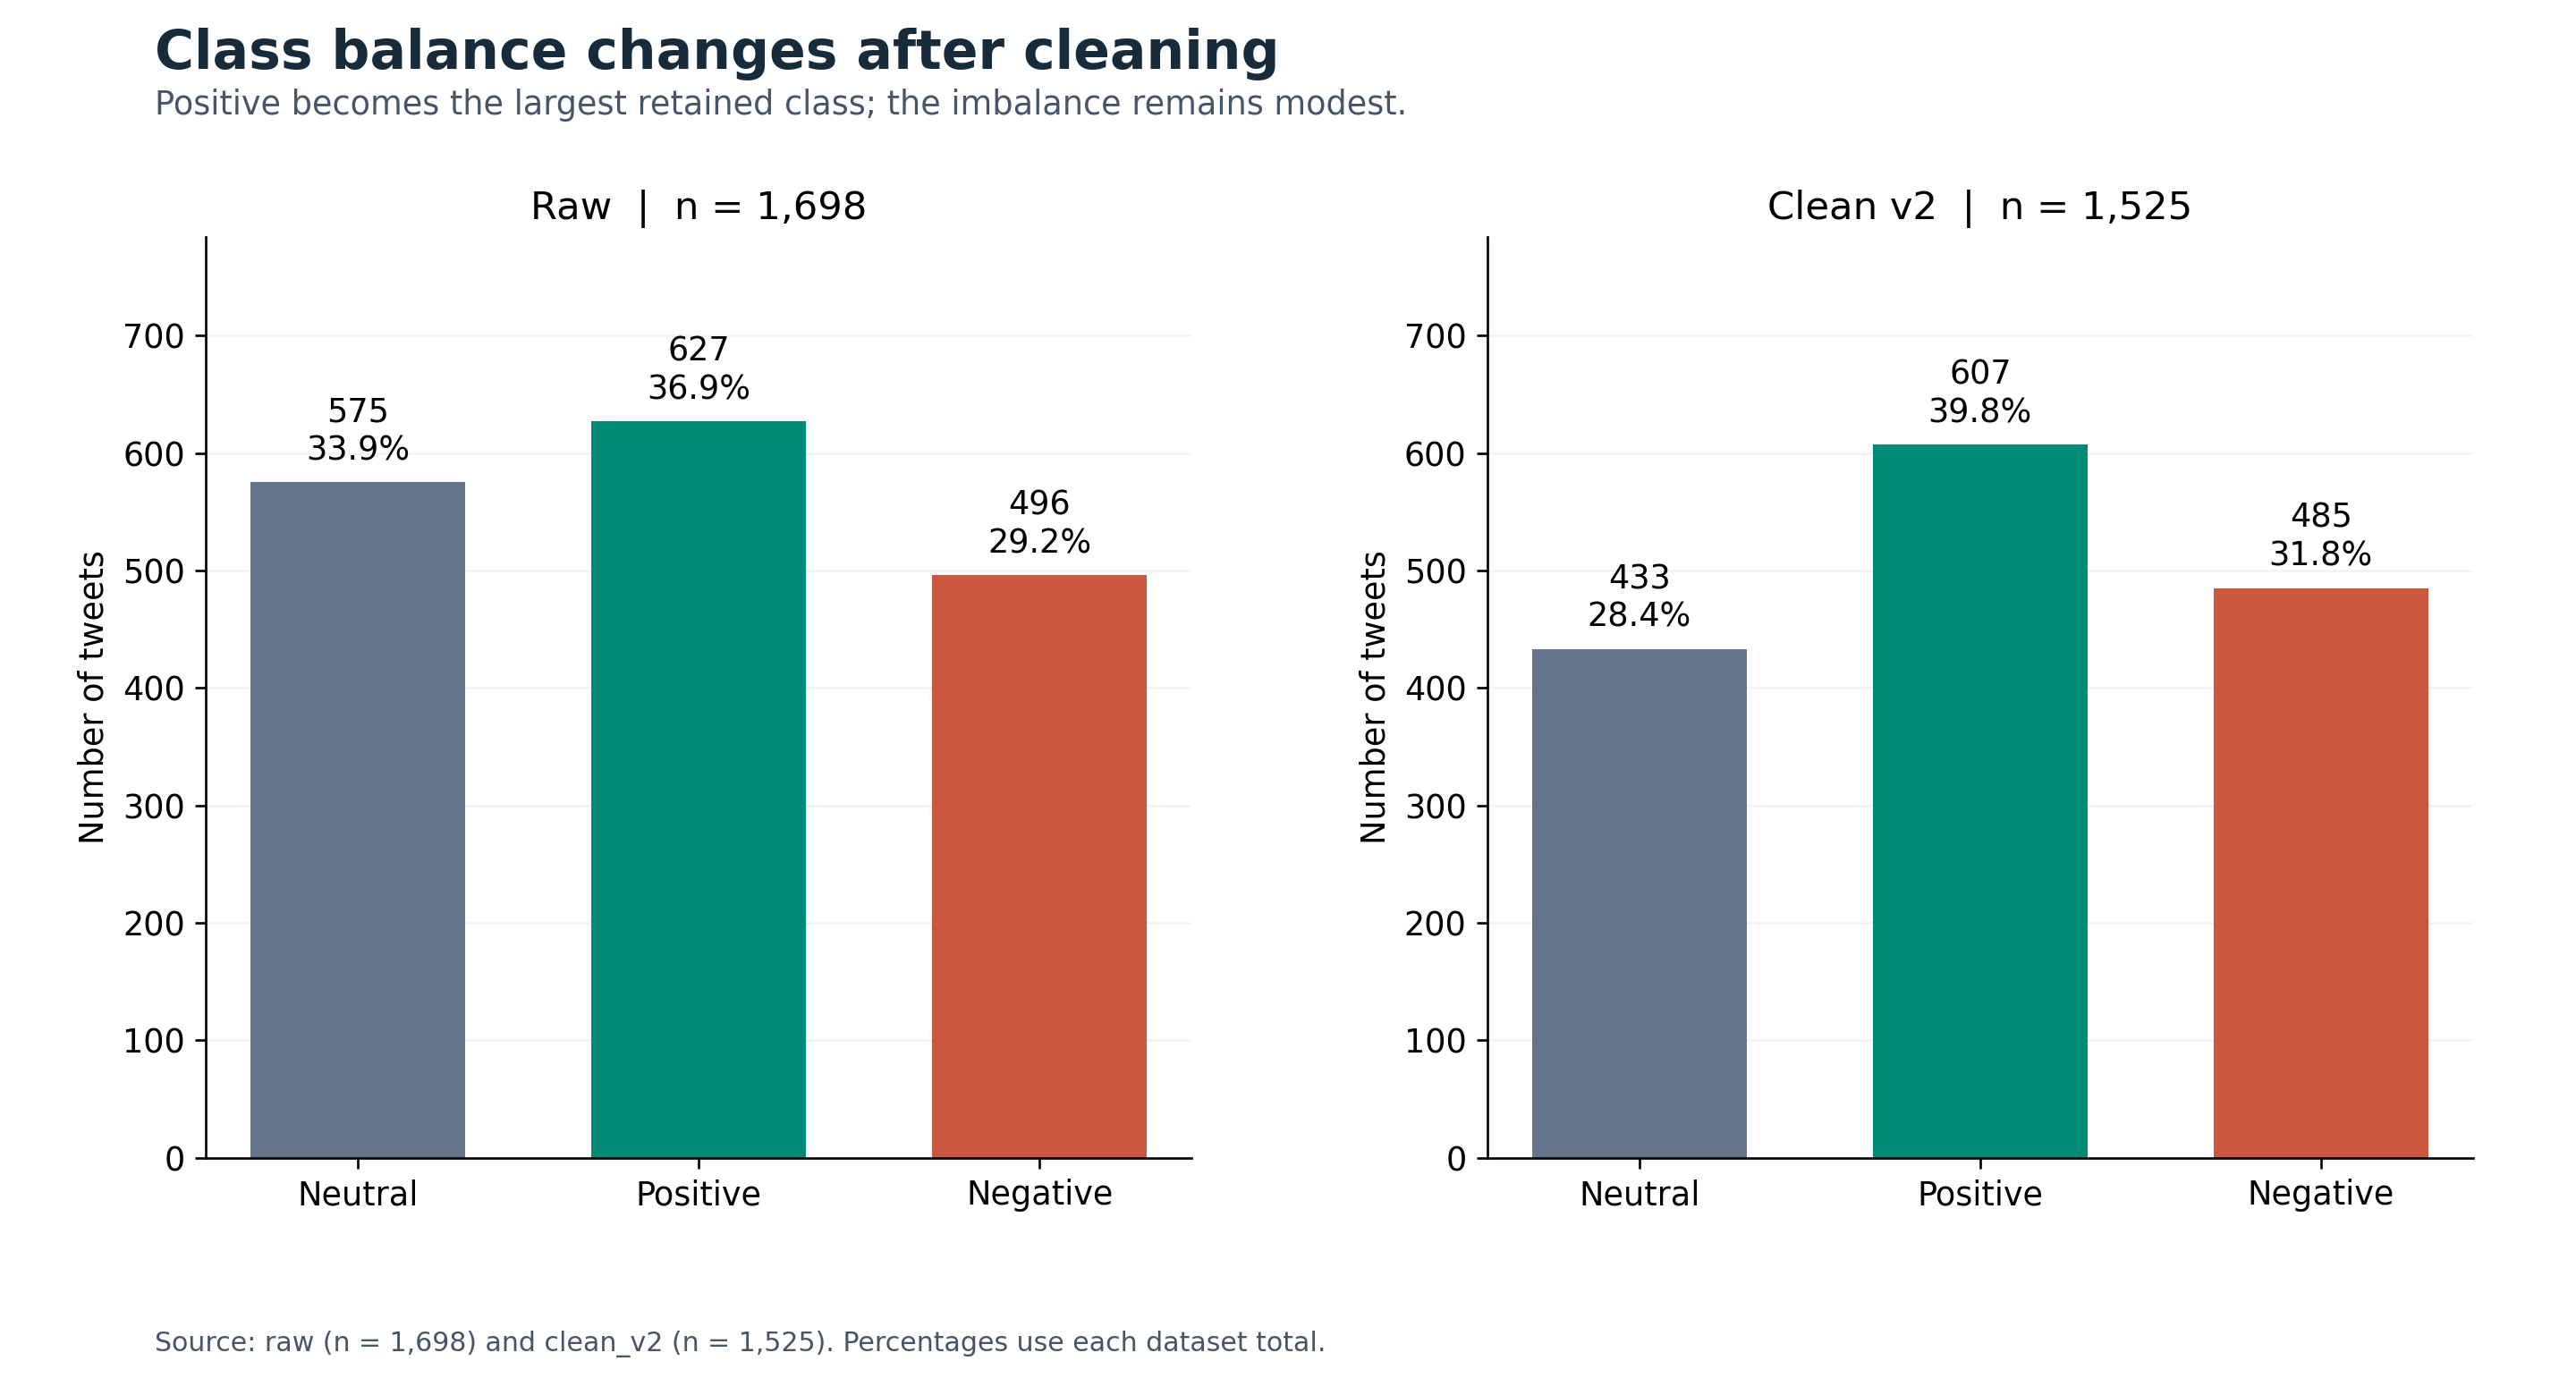

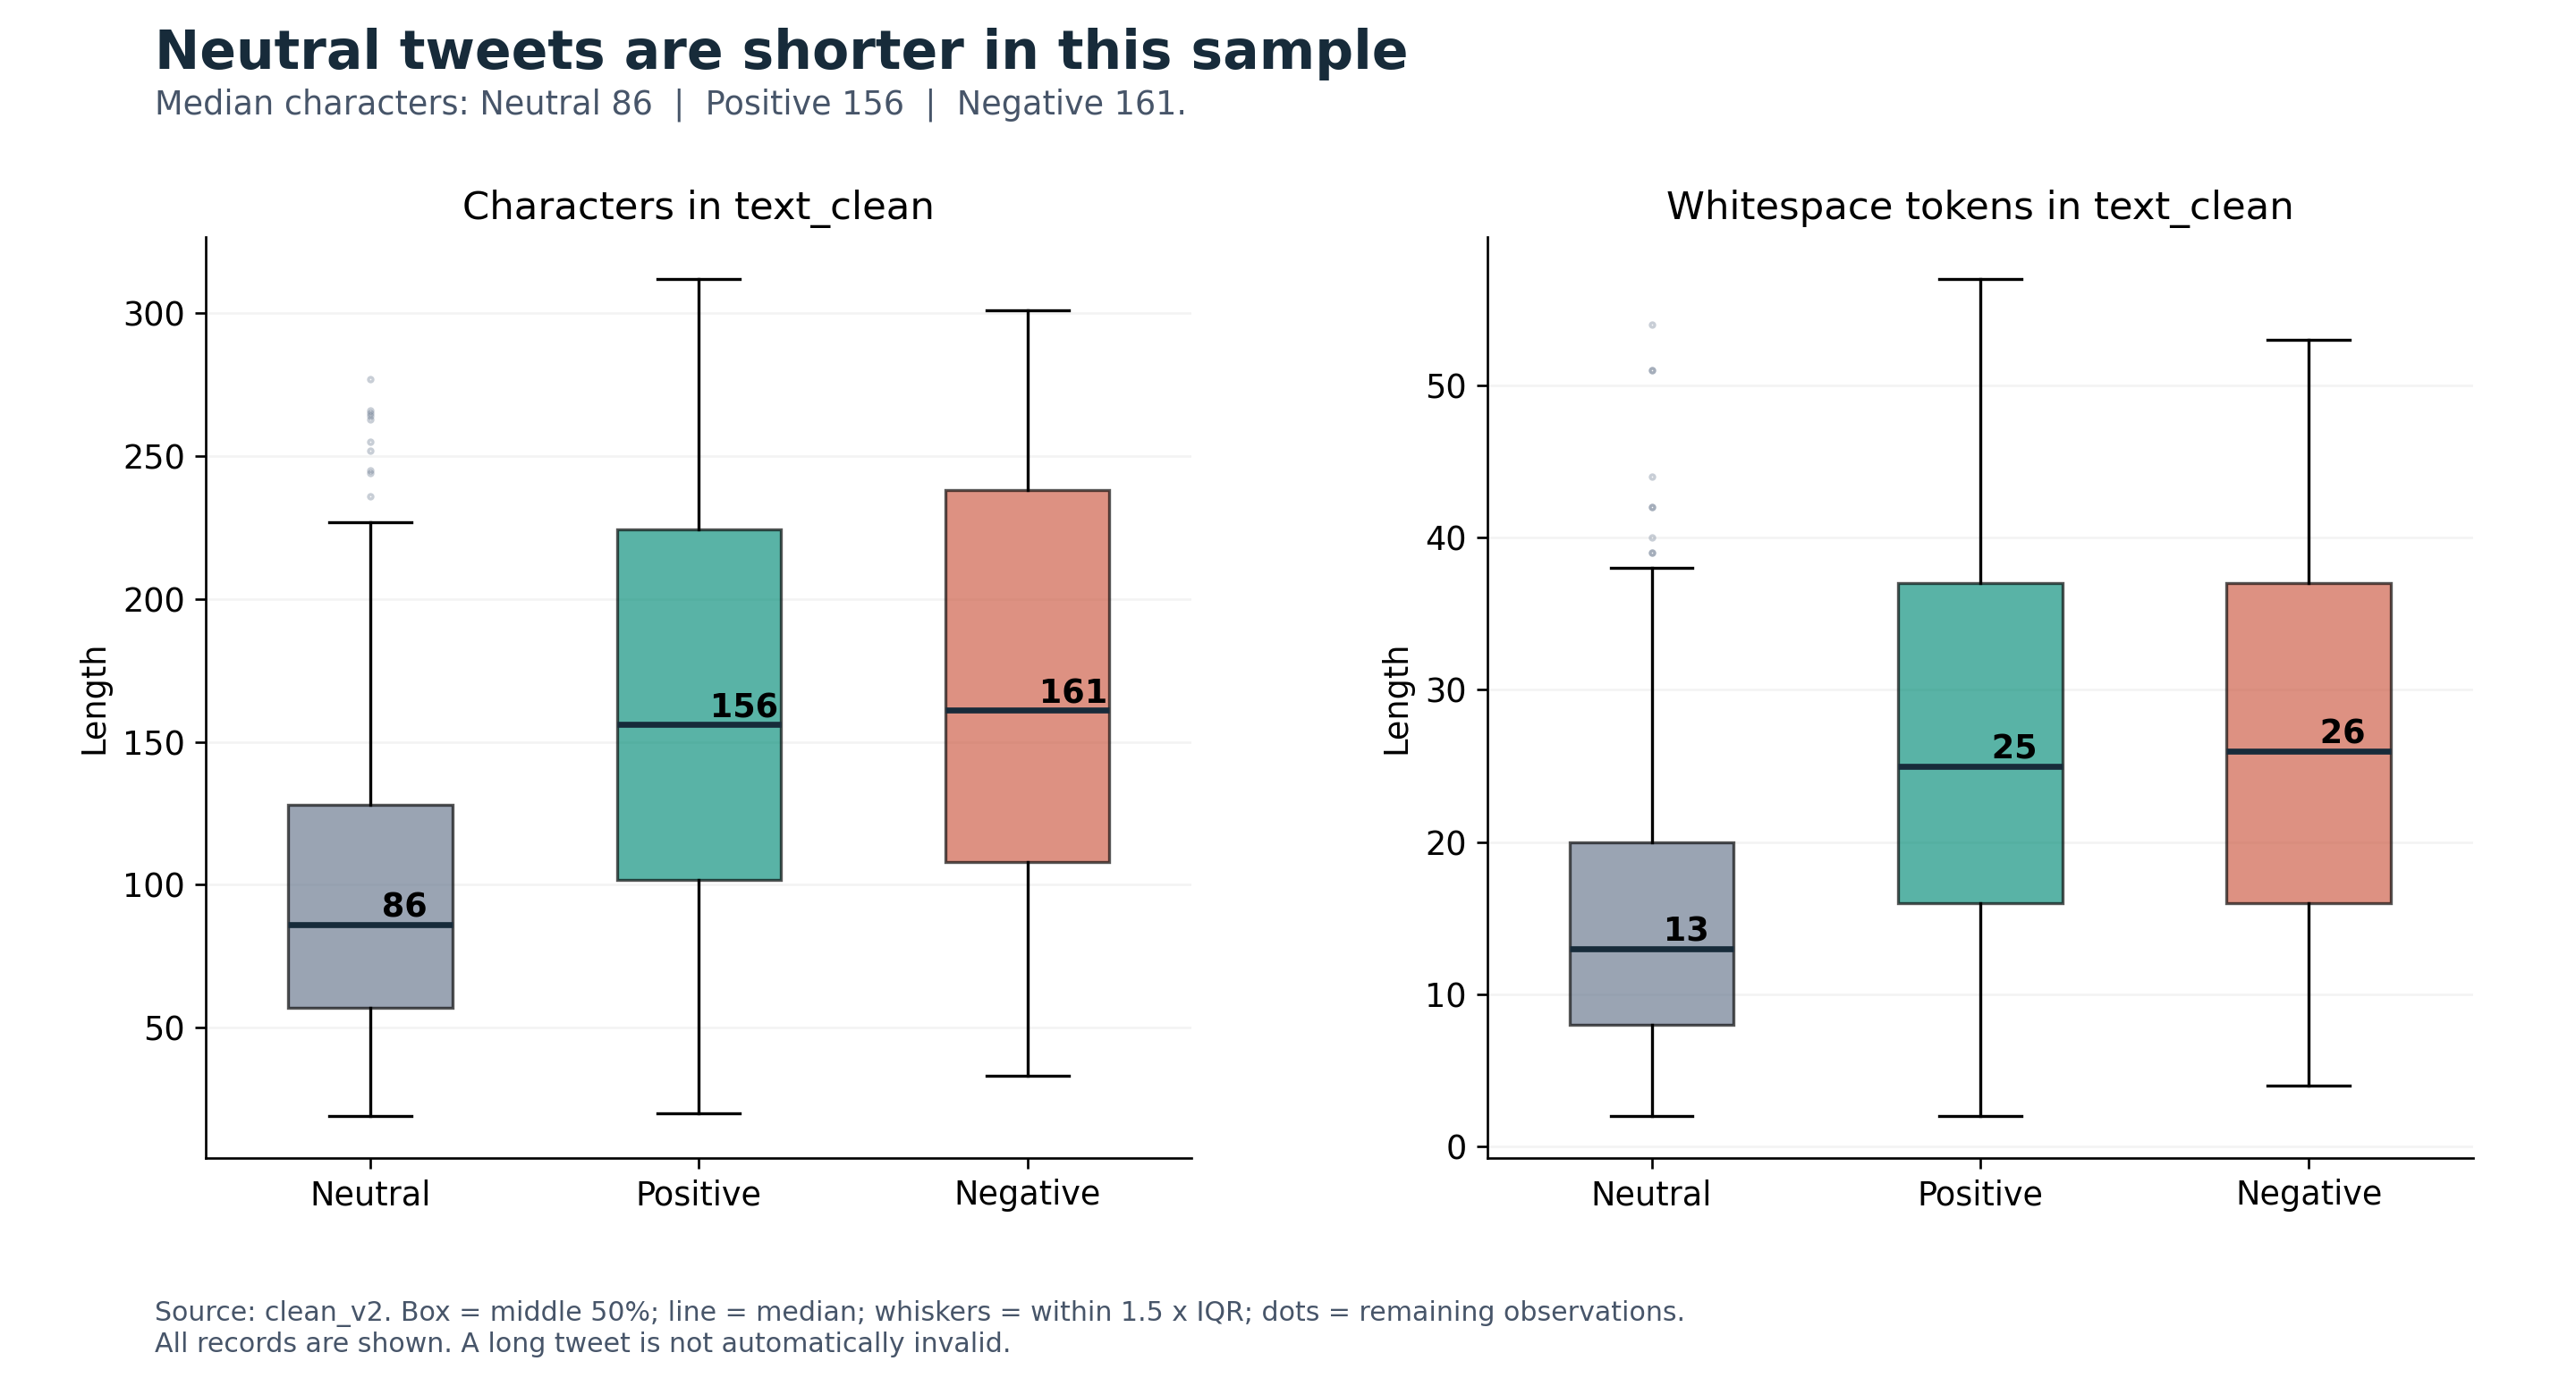

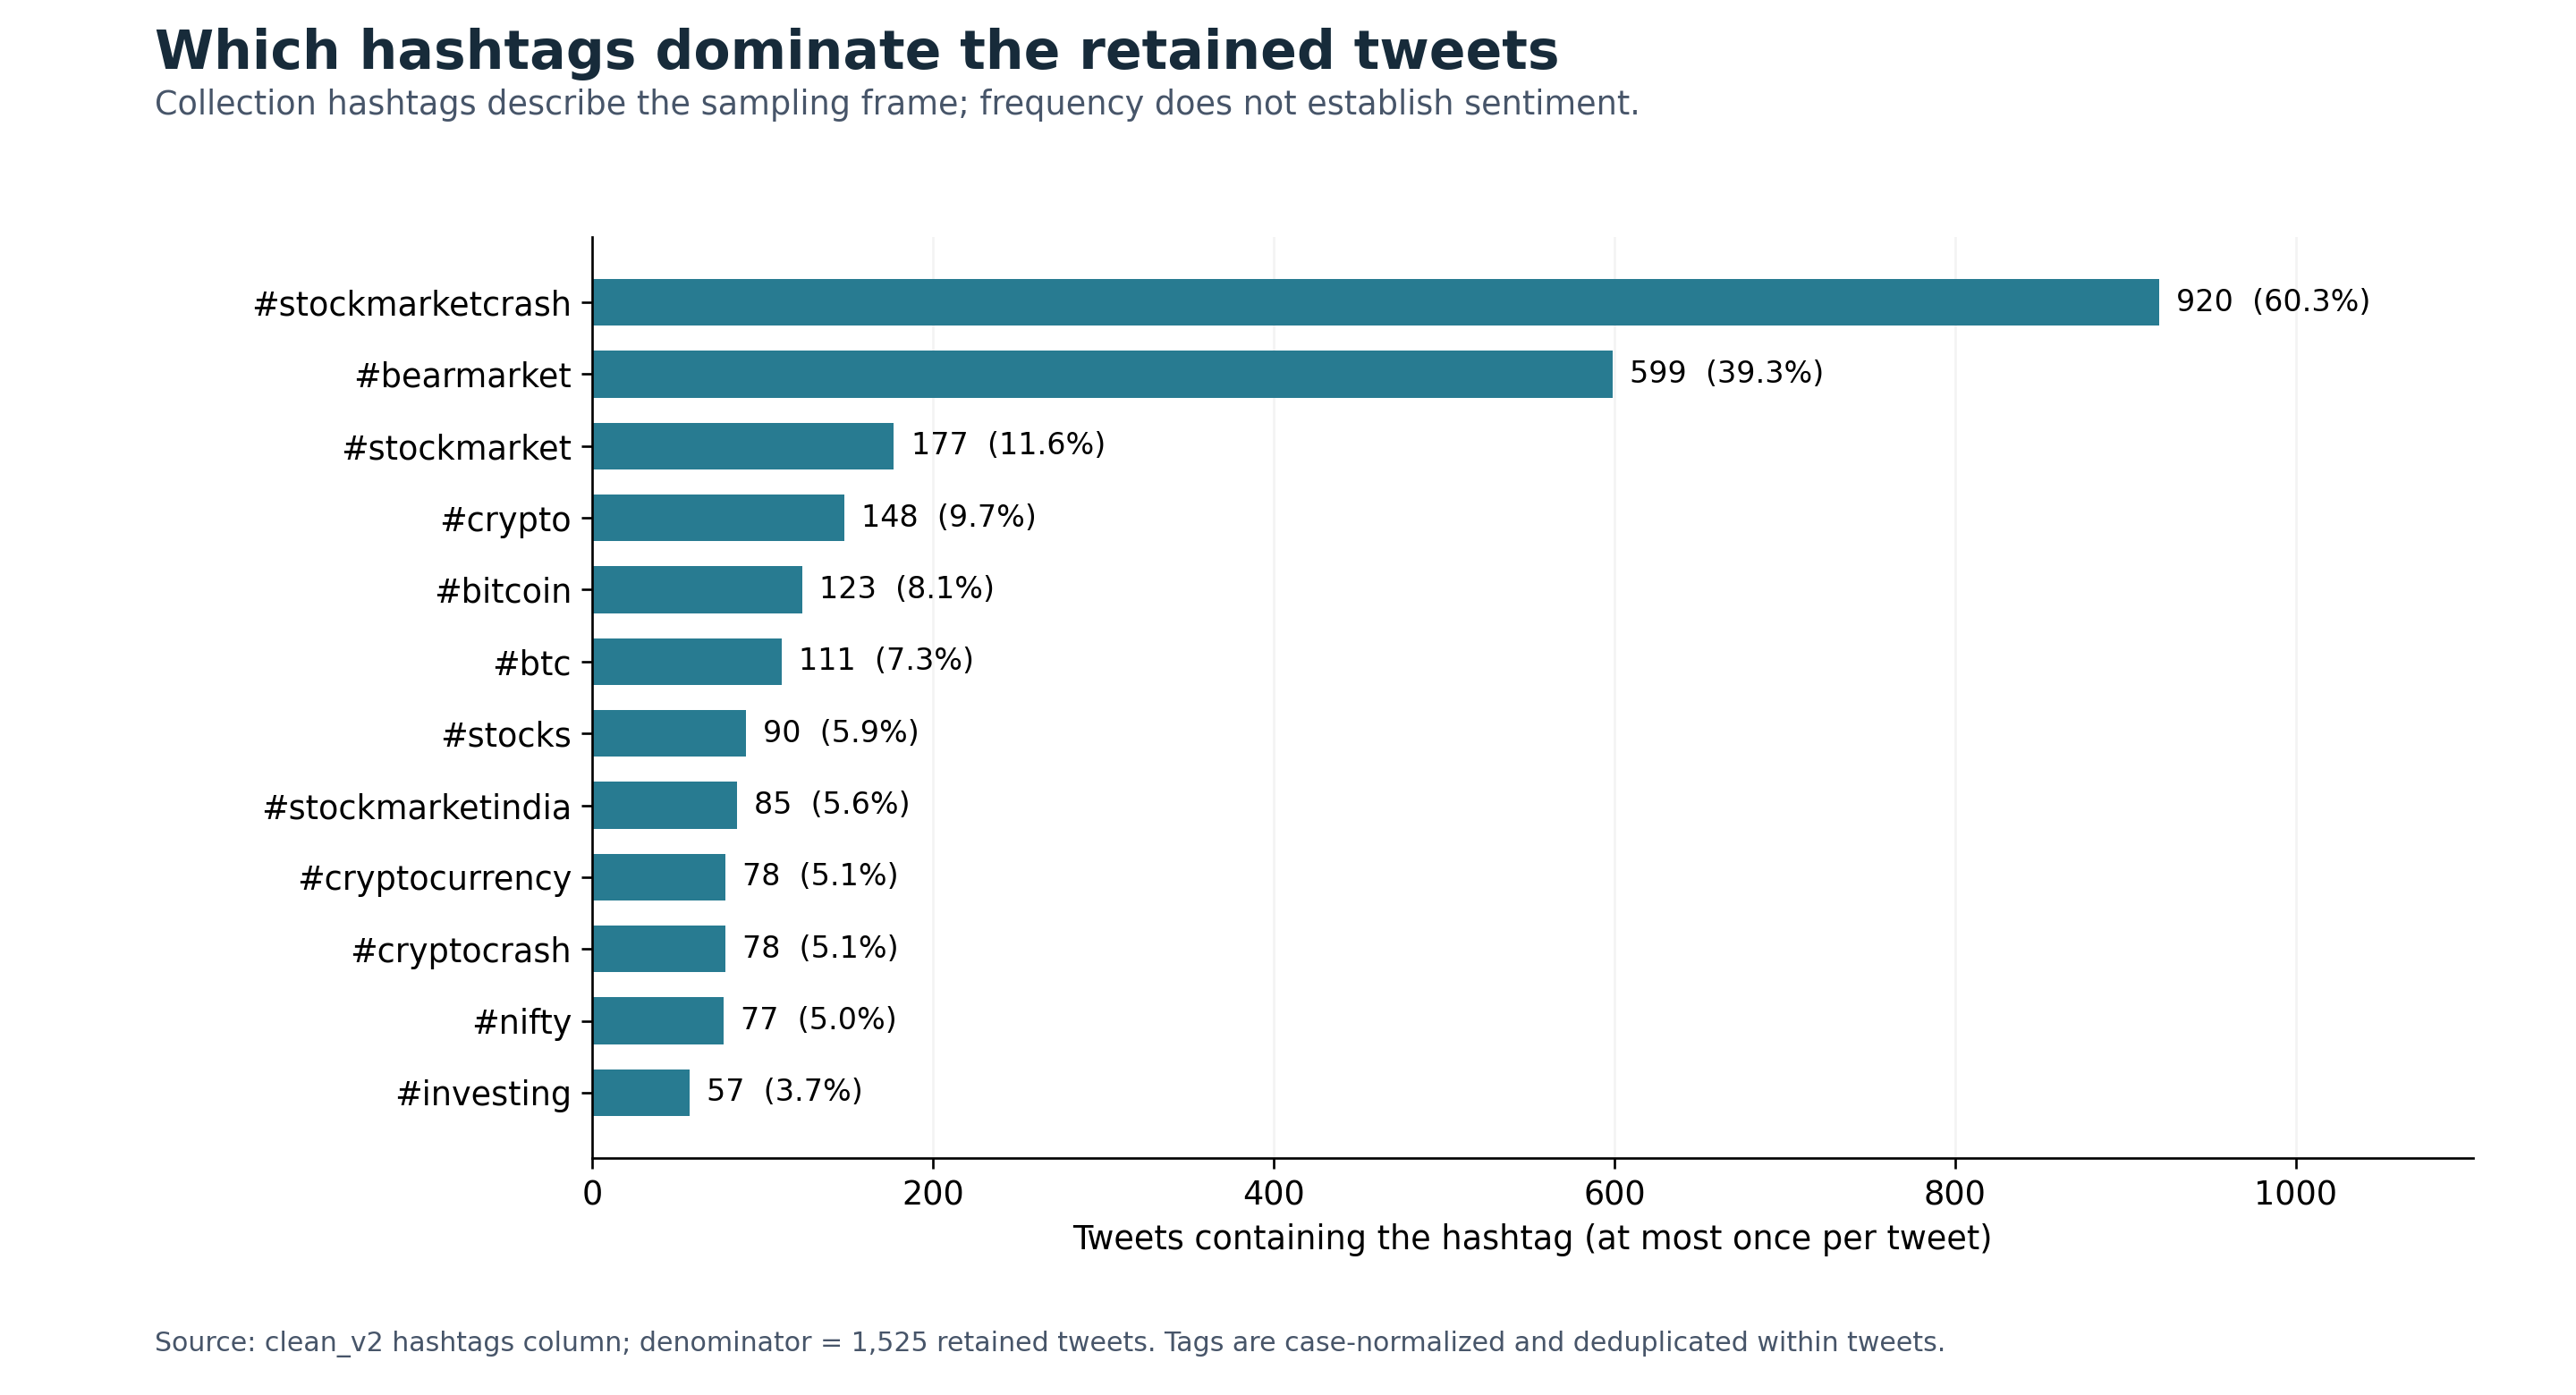

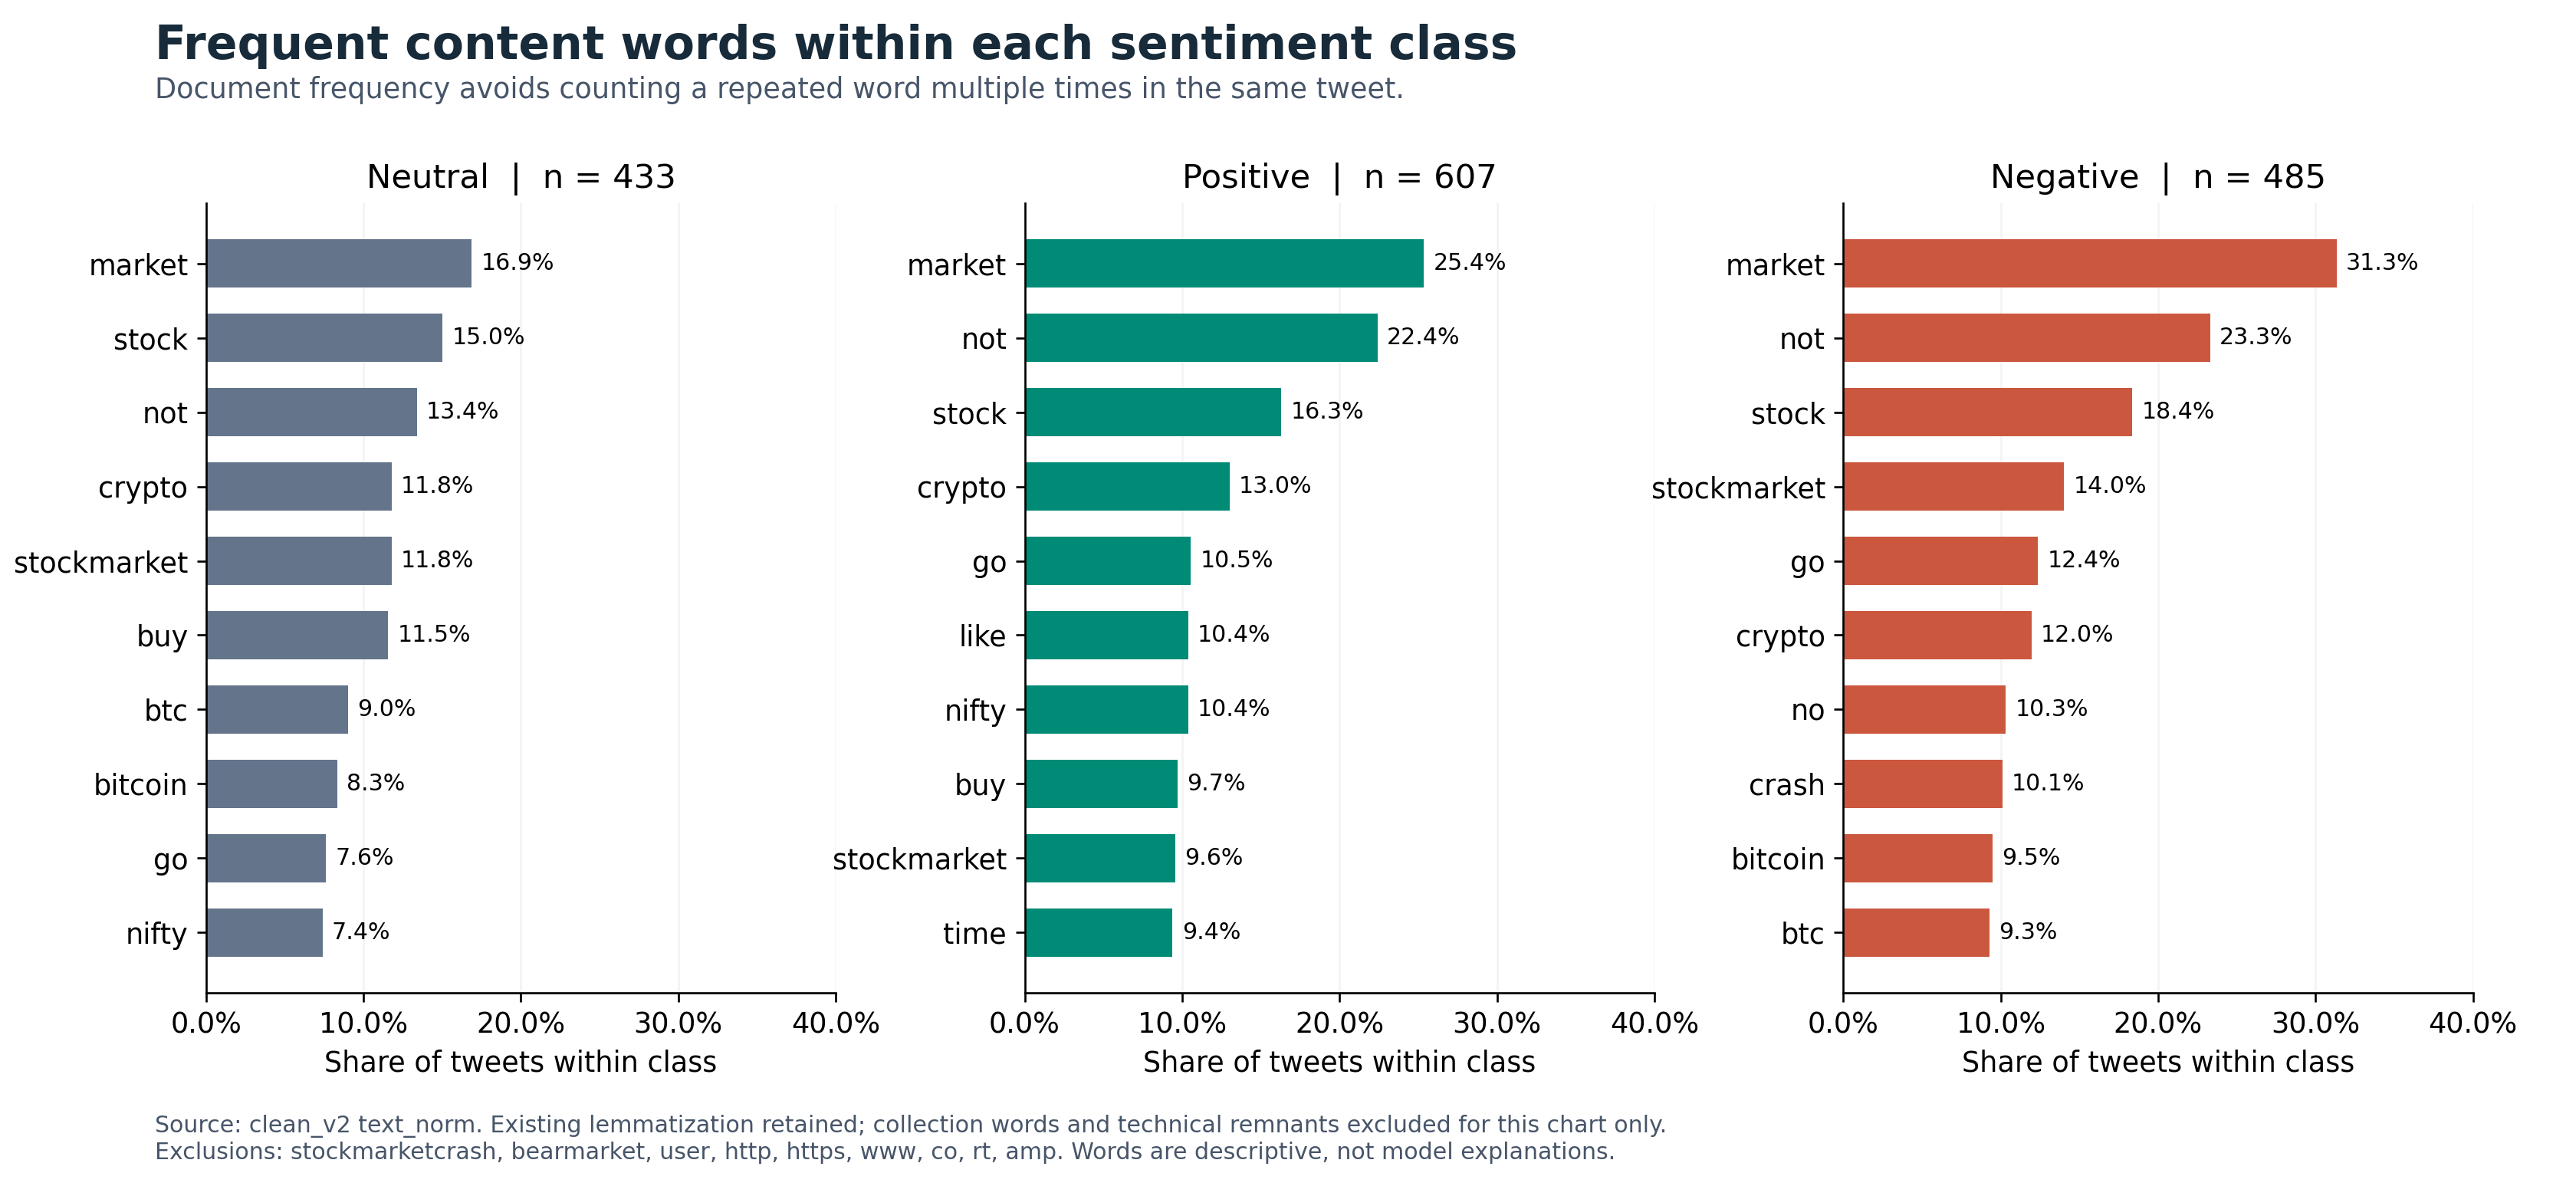

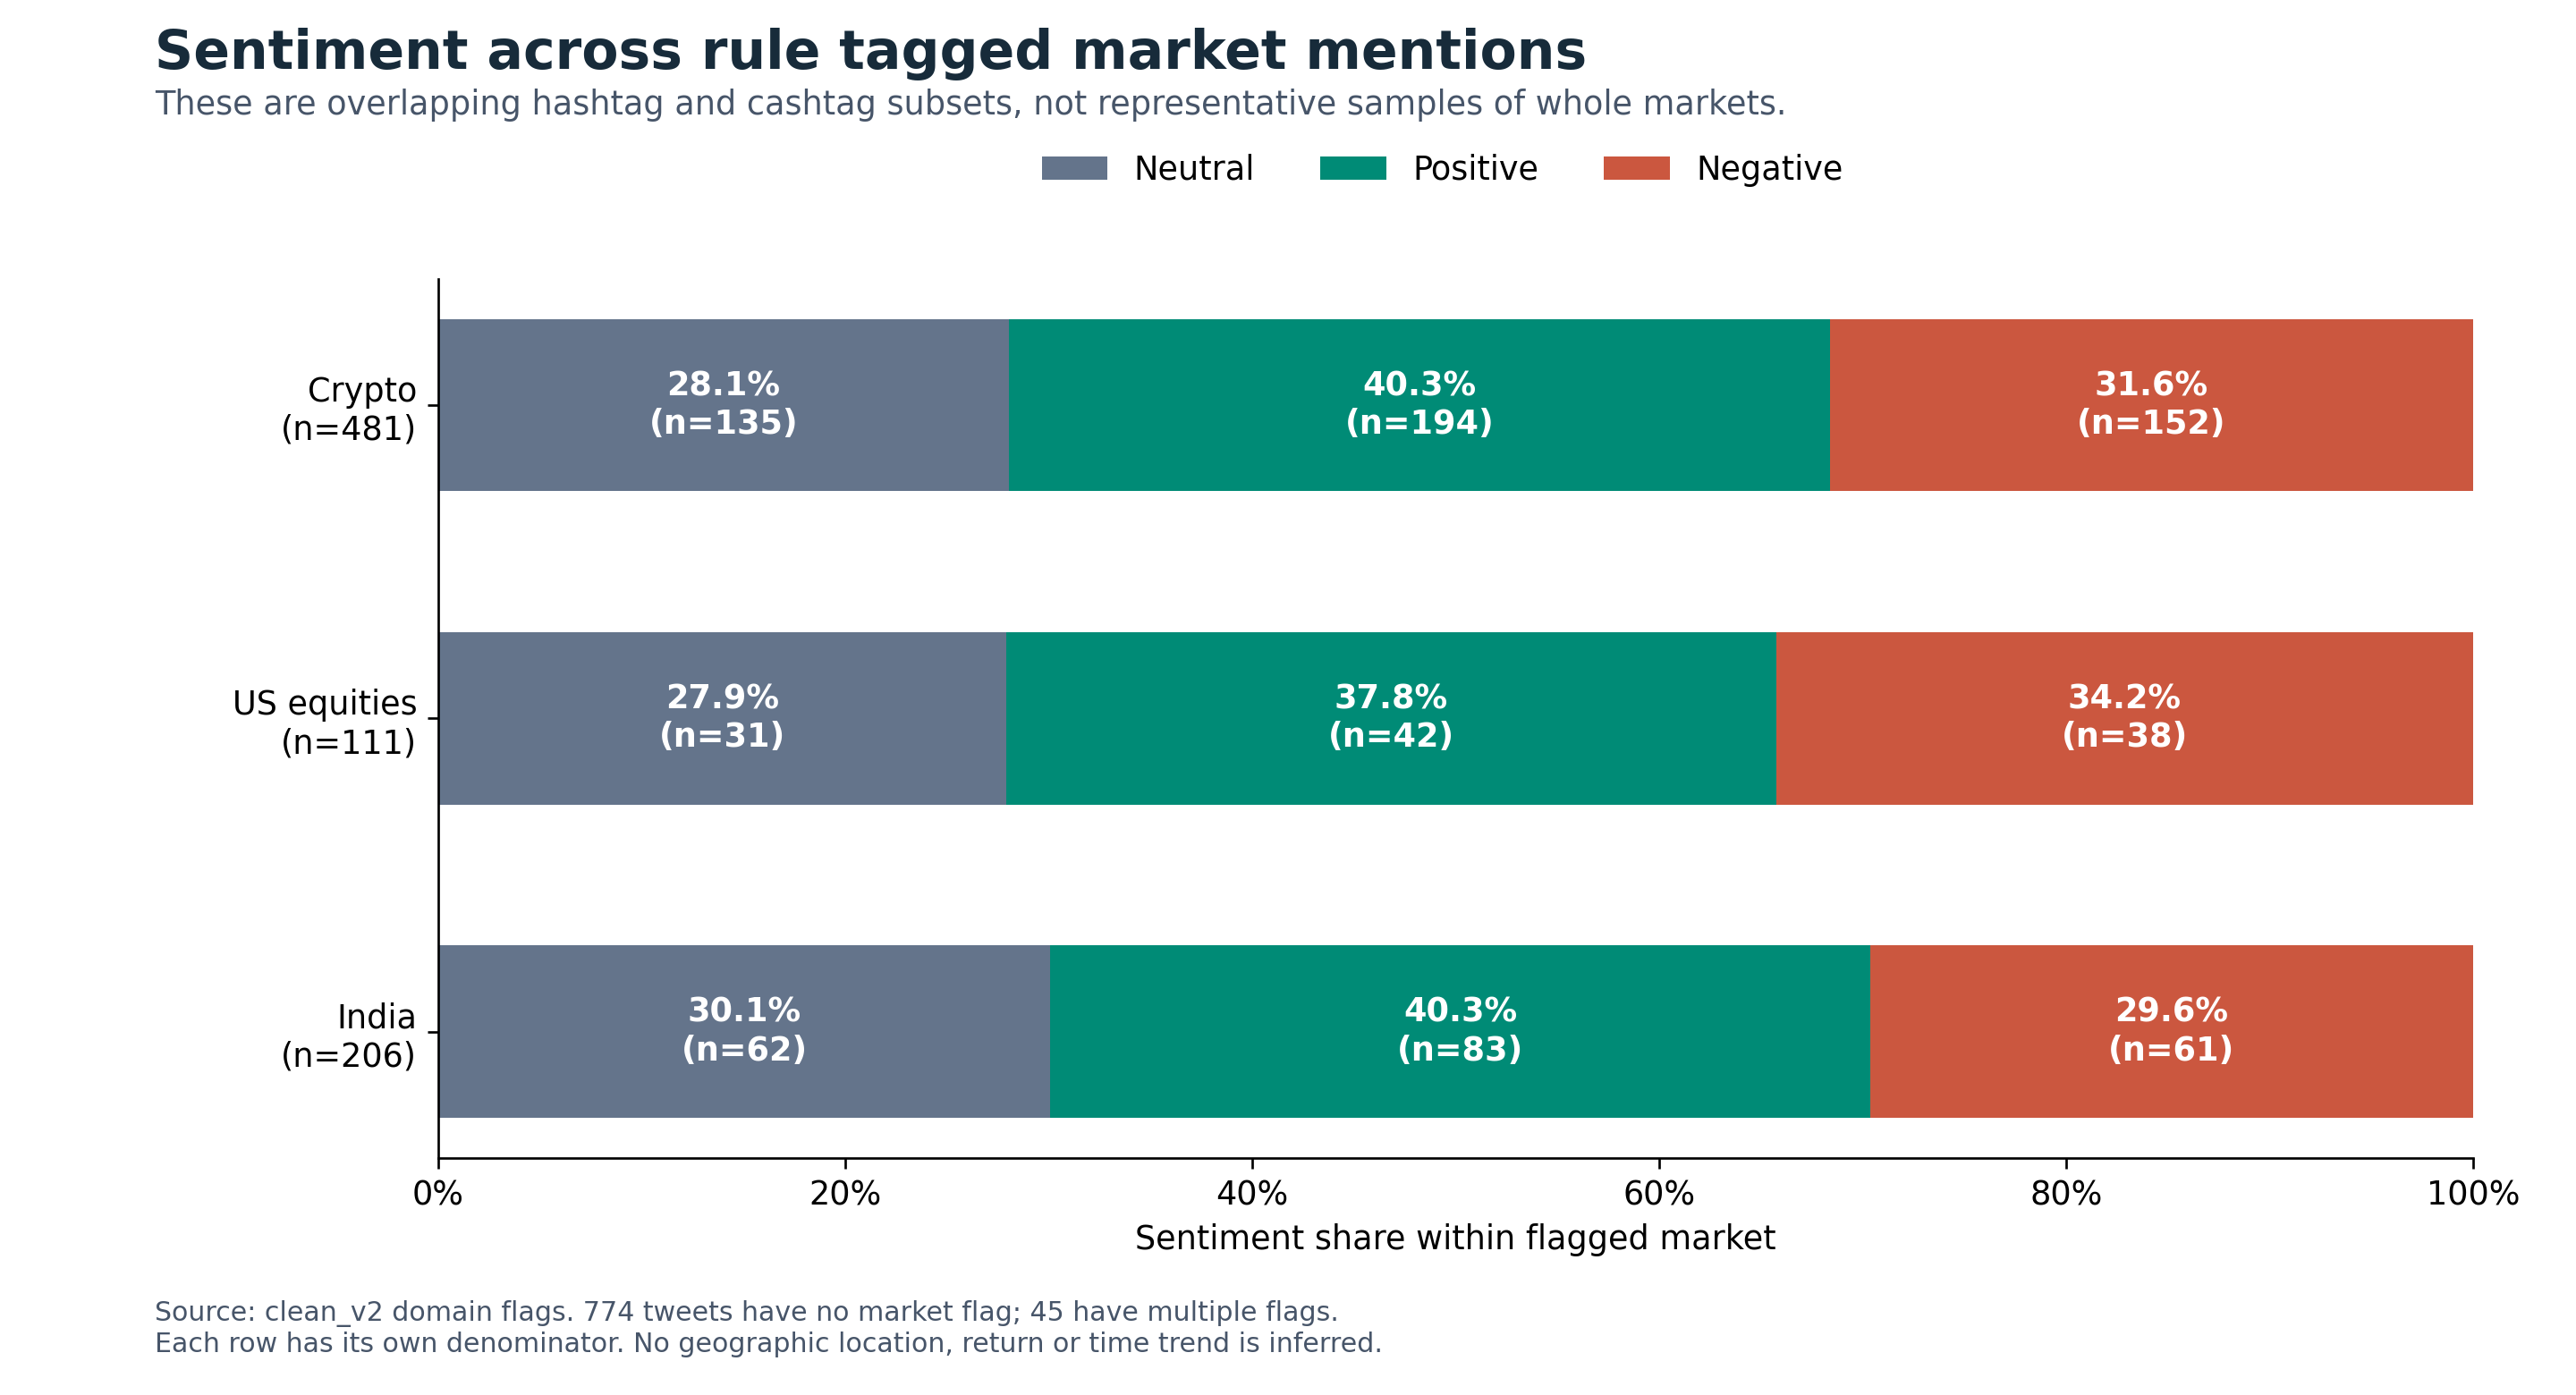

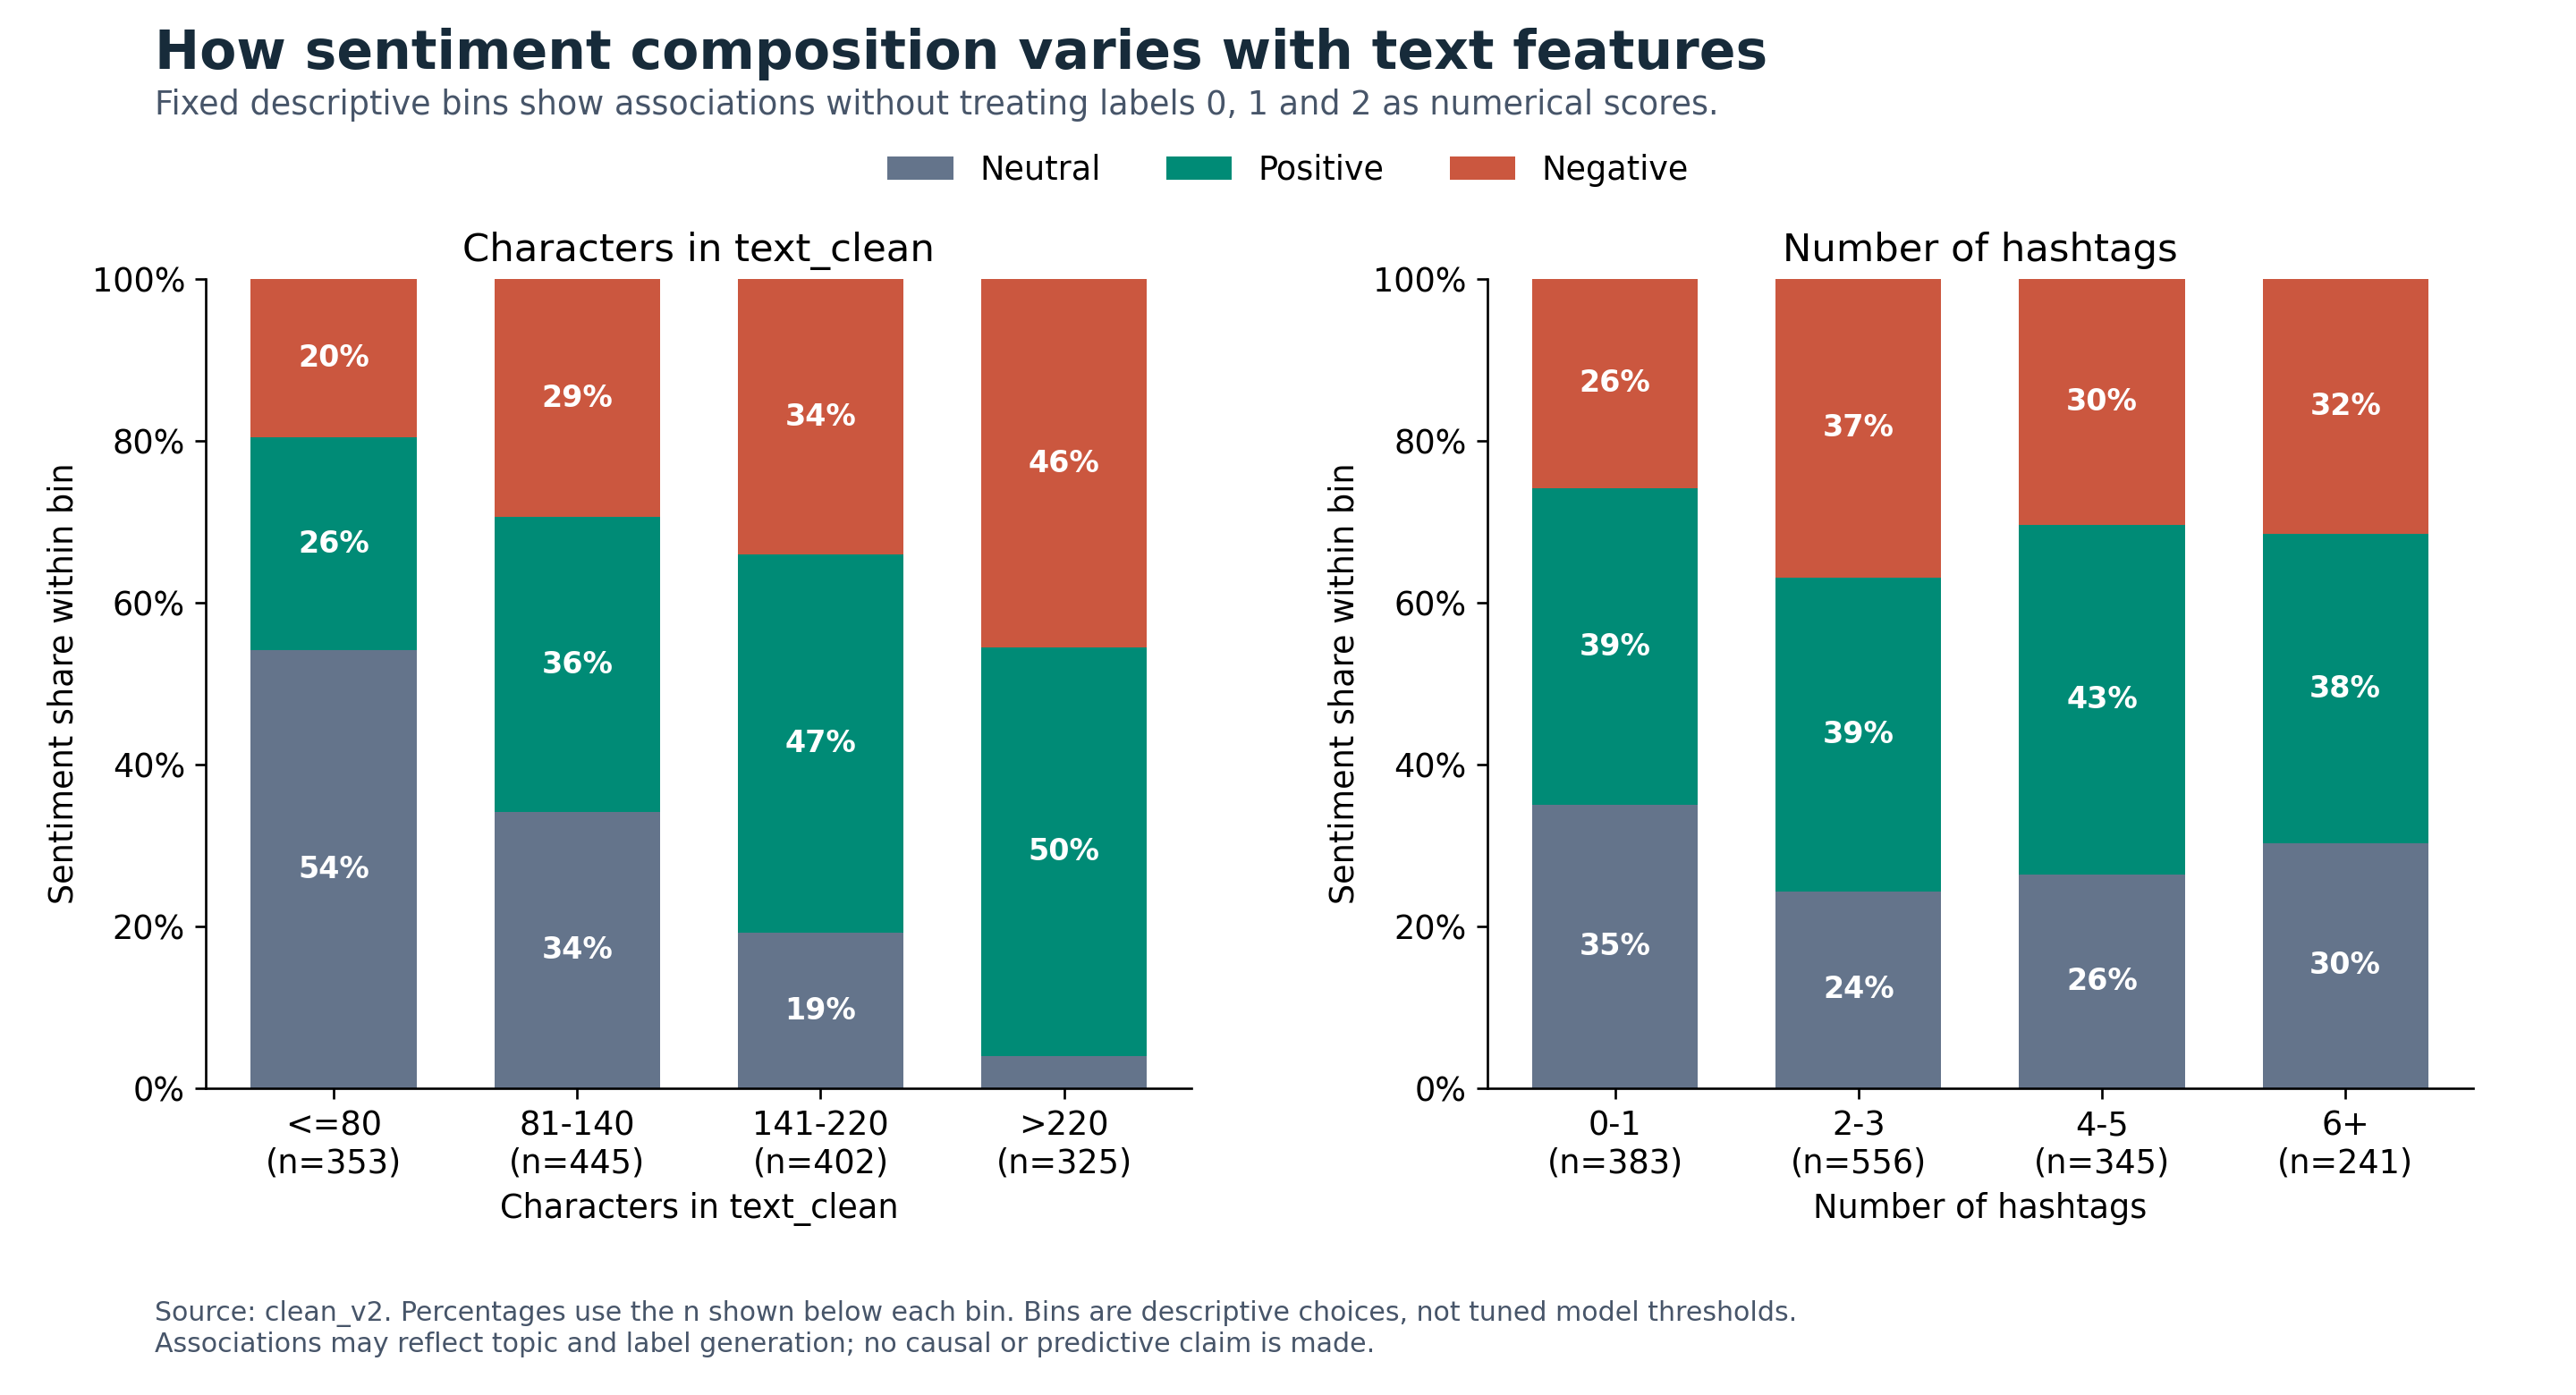

In [24]:
from IPython.display import Image, display

for picture in sorted((ROOT / "Member3_file").glob("eda_*.png")):
    display(Image(filename=str(picture)))


## Cleaning and split

We repair common encoding damage, mask user mentions and remove duplicate, unreadable, non-English and wordless posts. `text_clean` keeps more of the tweet structure for SBERT and text descriptors. `text_norm` lowercases and lemmatizes the text for TF-IDF and FastText, keeping negations and directional words such as “not” and “down”. Tweet IDs and supplied labels stay attached to the retained rows.

Exact and near-duplicate tweets share a group. All members of a group go into the same development fold or the reserve. The output below lists the cleaning steps and checks the stored assignment of 1,222 development rows and 303 reserve rows. Each outer-fold prediction comes from a model fitted on that fold’s training rows. The model notes below say where we used a separate inner split for tuning.

In [25]:
import pandas as pd
from src.data import load_clean, load_splits
from src.project_review import verify_cleaning
from src.splitting import make_splits, split_summary

import shutil
import nltk

# Reuse installed corpora when available; the cleaning code fetches missing corpora.
corpora = ROOT / "data/nltk_data"
for path in map(Path, nltk.data.path):
    if path.is_dir() and path.resolve() != corpora.resolve():
        for folder in ("corpora", "taggers"):
            if (path / folder).is_dir():
                shutil.copytree(path / folder, corpora / folder, dirs_exist_ok=True)

display(verify_cleaning())
clean = load_clean()
splits = load_splits(clean=clean)
pd.testing.assert_frame_equal(make_splits(clean), splits)
display(split_summary(clean, splits))

,step,operation,rows_affected,rows_remaining
0,0,Load raw data,1698,1698
1,1,Check missing and empty values,0,1698
2,2,Remove exact duplicates,9,1689
3,3,Repair encoding and HTML entities,155,1689
4,4,Remove unreadable tweets,21,1668
5,5,Anonymise mentions,273,1668
6,6,Restore verified contractions,166,1668
7,7,Remove lost characters,453,1668
8,8a,Remove non-English tweets (rules),84,1584
9,8b,Remove non-English tweets (manual list),18,1566


label,Neutral,Positive,Negative,records,share
split,,,,,
fold 0,66,97,79,242,0.1587
fold 1,72,97,78,247,0.1620
fold 2,70,97,77,244,0.1600
fold 3,71,96,77,244,0.1600
fold 4,69,99,77,245,0.1607
test,85,121,97,303,0.1987
development,348,486,388,1222,0.8013


## Text representations and classifiers

Each model predicts the three supplied labels. SBERT is frozen. FastText is learned again from the relevant training text in each fold.

| Model | How we used the text |
|---|---|
| TF-IDF + logistic regression | The fixed baseline uses normalized word unigrams with `C=1`. The nested search compares word unigrams, word unigrams plus bigrams, and character 3–5-grams. It also tries four regularization values and balanced class weights. |
| SBERT + SVM | We scale one sentence vector per tweet before fitting SVM. The nested search compares linear and RBF kernels, regularization values and class weights using the training folds. |
| SBERT + kNN | Cosine distance finds nearby tweets in sentence-vector space. We compare neighborhood sizes and uniform or distance-weighted voting. The main row uses same-fold selection. The separate nested check gives about 52.2% Macro-F1. |
| SBERT + XGBoost | PCA reduces the sentence vectors. We fit it on the training split, then add descriptors such as tweet length and hashtag ratio. The inner search selects tree settings and stopping rounds before the outer fold is scored. |
| FastText + MLP | We average the token vectors into one vector per tweet, scale it and feed it to an MLP. We compare regularization and class weights. Early stopping uses an inner split, while the configuration in the main table is selected on the outer folds. |
| SBERT + TextCNN | Convolutions read short windows of contextual token vectors, then masked pooling removes padded positions from the summary. The archived result comes from the seed-42 outer predictions of the nested configuration search. The separate fixed C3 run checks training and inference. |
| FastText + BiLSTM | The bidirectional LSTM reads a sequence of FastText vectors. Attention pools the sequence with a padding mask. We train a separate FastText encoder on the inner training subset to select the epoch, then refit on the full outer training portion before scoring. |

The fixed baseline gives us a common reference. The tuned baseline shows how much an inexpensive model can gain before we compare it with an embedding-based classifier.

## Development results

Each development tweet is predicted in the outer fold where it was held out. The first table shows the representation, regularization and class-weight setting picked inside each outer baseline training split. The next tables report percentages for the models and per-class results for the fusion.

TextCNN scores 61.79% Macro-F1 against 61.35% for the tuned baseline. The paired 95% interval for their difference crosses zero. For the fusion, we average their three class probabilities before taking the largest. The intervals below resample tweet groups and hold the existing predictions fixed. They describe variation across groups in this sample.

In [26]:
import pandas as pd
from src.project_review import comparison, development_data, paired_group_interval, score

dev = development_data()
comparison_table, params, probabilities = comparison(tuned=True)
display(params)
effects = []
for label in ("TextCNN", "Equal-weight vote"):
    left, right = paired_group_interval(dev, probabilities[label], probabilities["Tuned baseline"])
    delta = score(dev, probabilities[label], label)["macro_f1"] - score(dev, probabilities["Tuned baseline"], "tuned")["macro_f1"]
    effects.append({"model": label, "delta_vs_tuned": delta, "95% lower": left, "95% upper": right})
display(pd.DataFrame(effects))


reviewed_reruns = {'SBERT + SVM': {'run_id': 'svm', 'accuracy': 0.5957446808510638, 'macro_precision': 0.6004770192943888, 'macro_recall': 0.5883613070220225, 'macro_f1': 0.5922239794215574}, 'SBERT + descriptors + XGBoost': {'run_id': 'xgboost__sbert_multi__20261121-082501-4e5a', 'accuracy': 0.5834697217675942, 'macro_precision': 0.5845555881521696, 'macro_recall': 0.5775986418143861, 'macro_f1': 0.5789366243680534}, 'FastText + MLP': {'run_id': 'mlp__fasttext_mean__20261121-083916-d70d', 'accuracy': 0.5384615384615384, 'macro_precision': 0.5554493736539884, 'macro_recall': 0.5336235301805209, 'macro_f1': 0.538715945394297}}
from sklearn.metrics import classification_report, confusion_matrix
from src.config import LABELS, PROJECT_ROOT
from src.project_review import RUNS, read_run

fields = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]
archived = {name: read_run(PROJECT_ROOT / path, run_id) for name, path, run_id, *_ in RUNS}
rows = [
    ("Original TF-IDF + LR", score(dev, probabilities["Baseline"], "baseline_fixed")),
    ("Tuned TF-IDF + LR", score(dev, probabilities["Tuned baseline"], "baseline_nested")),
    ("SBERT + SVM (nested rerun)", reviewed_reruns["SBERT + SVM"]),
    ("SBERT + kNN", archived["kNN"]),
    ("SBERT + descriptors + XGBoost (rerun)", reviewed_reruns["SBERT + descriptors + XGBoost"]),
    ("FastText + MLP (rerun)", reviewed_reruns["FastText + MLP"]),
    ("SBERT + TextCNN (archived seed 42)", archived["TextCNN"]),
    ("FastText + BiLSTM (grouped inner early stopping)", archived["BiLSTM（分组内层早停）"]),
    ("Tuned baseline + TextCNN (equal weight)", score(dev, probabilities["Equal-weight vote"], "vote_equal_weight")),
]
full_scores = pd.DataFrame({name: {key: row[key] for key in fields} for name, row in rows}).T
full_scores.columns = ["Accuracy", "Macro precision", "Macro recall", "Macro-F1"]
display((100 * full_scores).round(2))

prediction = probabilities["Equal-weight vote"].argmax(1)
class_names = list(LABELS.values())
report = pd.DataFrame(classification_report(
    dev["label"], prediction, labels=list(LABELS), target_names=class_names, output_dict=True,
)).T.loc[class_names + ["macro avg", "weighted avg"]]
report[["precision", "recall", "f1-score"]] *= 100
report["support"] = report["support"].astype(int)
print(f"Correct predictions {int((prediction == dev['label']).sum())}/{len(dev)}")
display(report.round(2))
display(pd.DataFrame(confusion_matrix(dev["label"], prediction, labels=list(LABELS)),
                     index=class_names, columns=class_names)
        .rename_axis(index="Given label", columns="Prediction"))

,fold,text,ngram,analyzer,C,class_weight
0,0,text_norm,"(1, 1)",word,1,balanced
1,1,text_norm,"(1, 1)",word,4,None
2,2,text_norm,"(1, 1)",word,16,balanced
3,3,text_norm,"(1, 1)",word,16,None
4,4,text_norm,"(1, 1)",word,4,balanced


,model,delta_vs_tuned,95% lower,95% upper
0,TextCNN,0.004448,-0.029852,0.039303
1,Equal-weight vote,0.050374,0.023395,0.077124


,Accuracy,Macro precision,Macro recall,Macro-F1
Original TF-IDF + LR,59.25,60.53,57.67,58.20
Tuned TF-IDF + LR,61.46,61.50,61.22,61.35
SBERT + SVM (nested rerun),59.57,60.05,58.84,59.22
SBERT + kNN,54.66,55.50,54.55,53.95
SBERT + descriptors + XGBoost (rerun),58.35,58.46,57.76,57.89
FastText + MLP (rerun),53.85,55.54,53.36,53.87
SBERT + TextCNN (archived seed 42),61.78,61.64,62.12,61.79
FastText + BiLSTM (grouped inner early stopping),52.13,51.98,52.50,52.11
Tuned baseline + TextCNN (equal weight),66.37,66.43,66.35,66.39


Correct predictions 811/1222


,precision,recall,f1-score,support
Neutral,68.82,67.24,68.02,348
Positive,67.15,66.87,67.01,486
Negative,63.32,64.95,64.12,388
macro avg,66.43,66.35,66.39,1222
weighted avg,66.41,66.37,66.38,1222


Prediction,Neutral,Positive,Negative
Given label,,,
Neutral,234,68,46
Positive,61,325,100
Negative,45,91,252


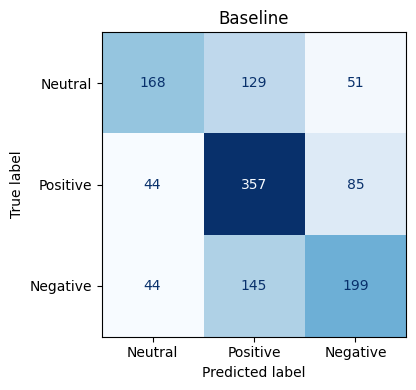

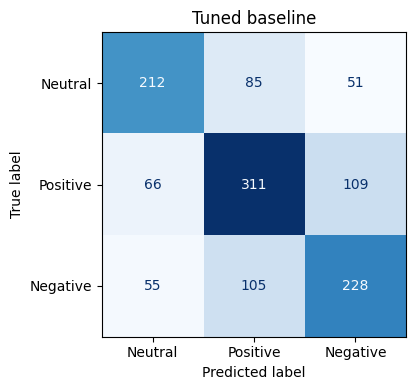

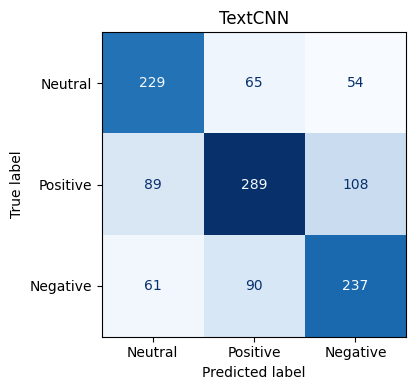

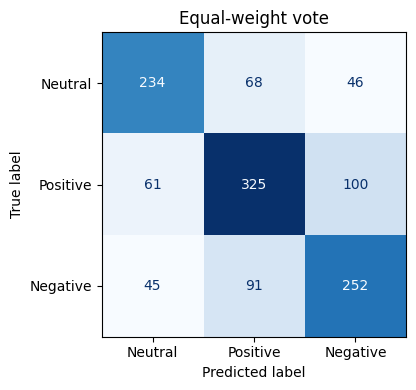

In [27]:
from src.evaluate import plot_confusion
import matplotlib.pyplot as plt

for name in ("Baseline", "Tuned baseline", "TextCNN", "Equal-weight vote"):
    plot_confusion(dev["label"], probabilities[name].argmax(1), name)
    plt.show()

## Error analysis

We use VADER to check label agreement. The error counts compare the original baseline, kNN, the published MLP run and TextCNN.

VADER agrees with 92.06% of the labels on the raw text of the 1,222 development tweets. The separate 1,666-tweet check gives 93.0%. In 13 of 14 retained cases where repairing negation changed VADER's prediction, the supplied label matched the damaged text. This supports the VADER-style labeling hypothesis. The original labeling procedure is unknown.

In [28]:
import numpy as np
from src.project_review import diagnostic_agreement

display(diagnostic_agreement(dev))
models = ("Baseline", "kNN", "MLP", "TextCNN")
all_wrong = np.logical_and.reduce([probabilities[name].argmax(1) != dev["label"].to_numpy() for name in models])
has_finance = dev["text_clean"].str.contains(r"\b(?:bear|bearish|bull|bullish|crash|dip|short|puts|red|green|nifty|fed)\b", case=False)
display(pd.DataFrame({"all_wrong": all_wrong, "finance_term": has_finance})
        .groupby("all_wrong")["finance_term"].agg(["size", "mean"]))

,text,agreement_with_given_labels
0,text_raw,0.920622
1,text_clean,0.914894
2,text_norm,0.851064


,size,mean
all_wrong,,
False,1070,0.264486
True,152,0.394737


### XGBoost errors against the fixed baseline

Yang Qitian aligned the published XGBoost OOF predictions with the fixed TF-IDF baseline by tweet ID. This comparison uses the original baseline and the published XGBoost predictions. The main results table uses the XGBoost rerun.

| Given label | Fixed baseline correct | Published XGBoost correct |
|---|---:|---:|
| Neutral | 168 | 207 |
| Positive | 357 | 317 |
| Negative | 199 | 188 |

The paired group-bootstrap 95% interval for XGBoost minus baseline Macro-F1 was −3.56 to +3.08 percentage points. The interval describes these fixed predictions.

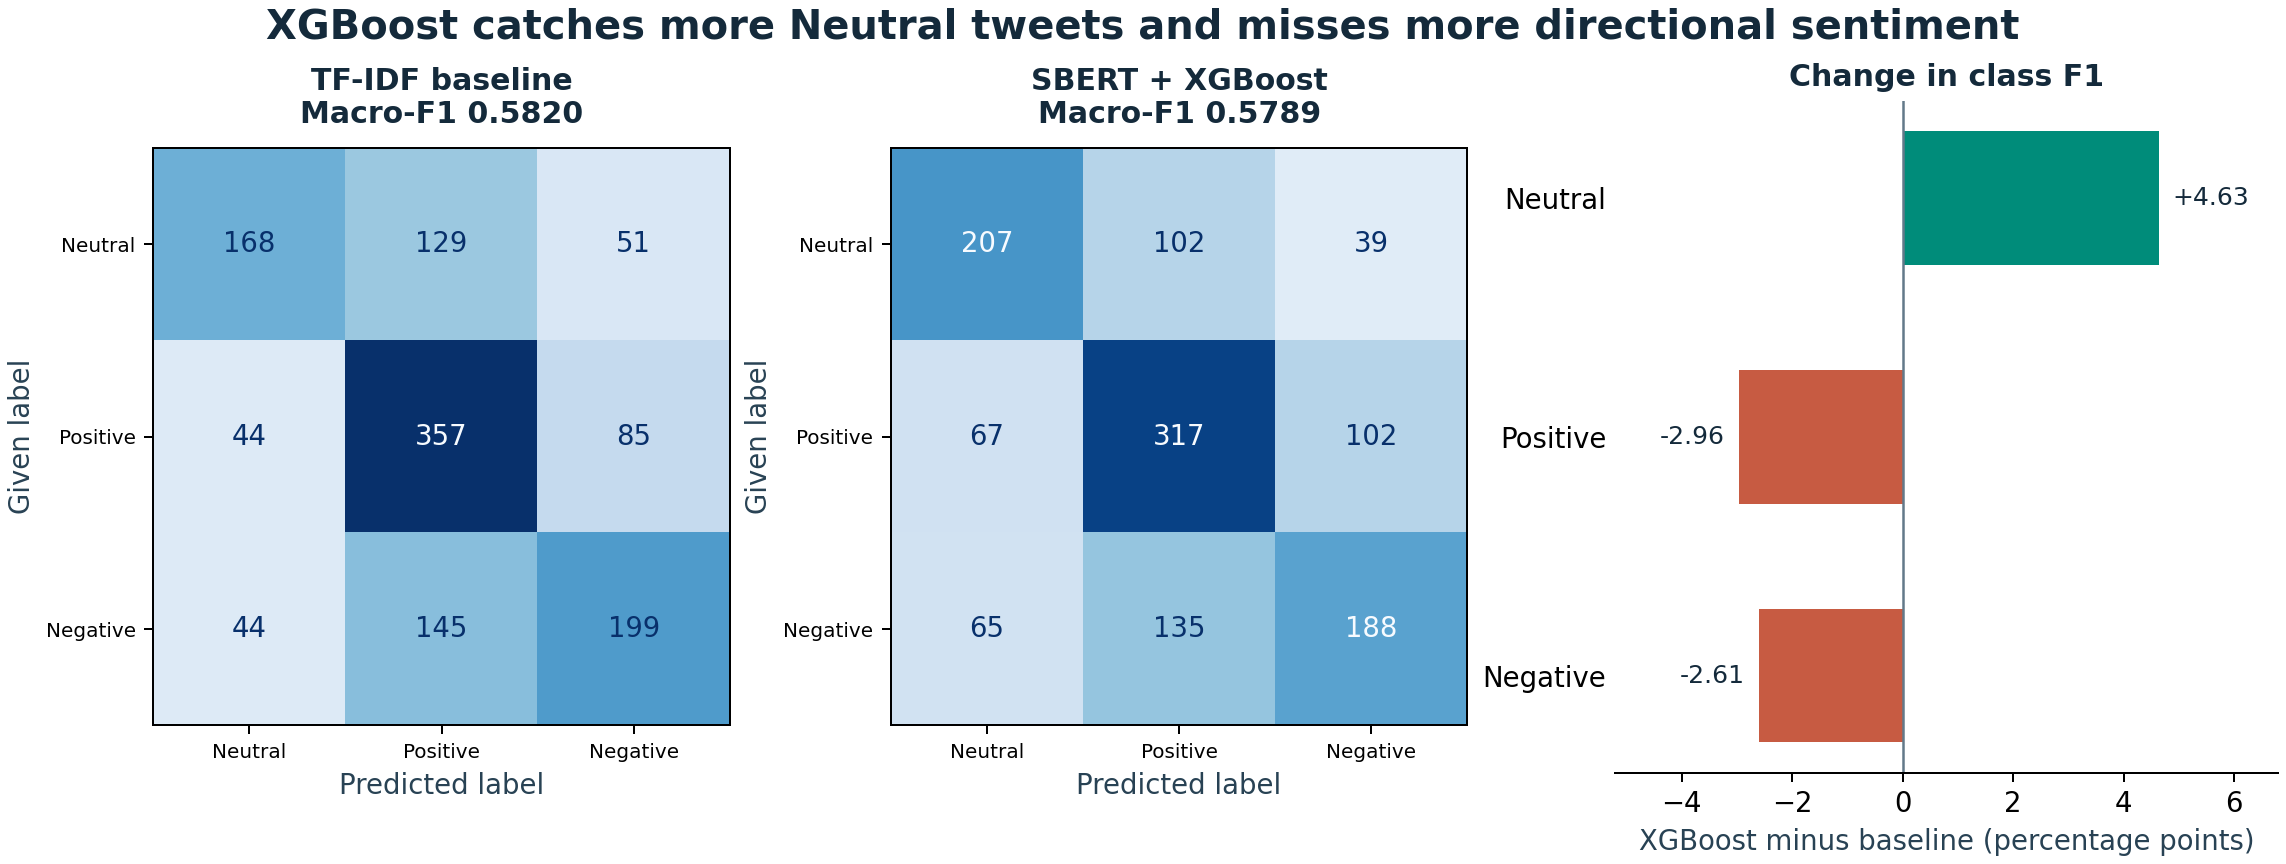


### Class imbalance

The original FastText control scored 0.5092 without adjustment, 0.5274 with class weights and 0.5268 with oversampling. Repeating the development comparison with a regenerated FastText cache gave 0.5164, 0.5230 and 0.5354. The ordering changes across runs, so we do not pick an adjustment from these results.

## Conclusion

The tuned baseline nearly matched TextCNN. Their equal-weight average got 811 of 1,222 development tweets right. We chose the combination after looking at the development results. An independent evaluation is still needed. This notebook leaves the 303 reserve labels unscored.

## Retraining

Both training switches are off by default. Enable `RUN_FASTTEXT_MODELS` to rebuild the FastText vectors and train MLP and BiLSTM. Enable `RUN_SBERT_MODELS` for the SBERT classifiers. Point `SBERT_CACHE_DIRECTORY` at a verified embedding cache, or enable `GENERATE_SBERT` to fetch the pinned encoder and generate the embeddings. The nested TextCNN search has its own switch and takes substantially longer.

The fixed TextCNN C3 run can produce probabilities for reserve tweet IDs without scoring their labels. The optional paired XGBoost analysis takes the prediction file from the published XGBoost run.

In [29]:
RUN_FASTTEXT_MODELS = False
RUN_SBERT_MODELS = False
GENERATE_SBERT = False
RUN_TEXTCNN_NESTED = False
SBERT_CACHE_DIRECTORY = None  # Set to the folder containing the team embedding arrays and manifest.

XGBOOST_PAIRED_OOF = None  # Optional path to the published XGBoost OOF NPZ.

In [30]:
import runpy
import torch

from src.fasttext_emb import build_fold_embeddings
from src.member6 import bilstm_oof, imbalance_oof
from src.config import EMB_DIR, FIGURES_DIR
from Member5_file.sbert_cache import prepare_embeddings
from Member5_file.c3_workflow import run_c3
from Member3_file.m3_xgboost import main as run_xgboost
from src.member1 import sbert_svm_oof
from src.member4 import run as run_mlp

if RUN_FASTTEXT_MODELS:
    torch.set_num_threads(2)
    build_fold_embeddings(clean, splits, 31)
    display(run_mlp())
    bilstm_probabilities, epochs = bilstm_oof(dev)
    display(epochs, score(dev, bilstm_probabilities, "bilstm_retrained"))
    display(imbalance_oof(dev))

if RUN_SBERT_MODELS:
    if SBERT_CACHE_DIRECTORY:
        shutil.copytree(SBERT_CACHE_DIRECTORY, EMB_DIR, dirs_exist_ok=True)
    if prepare_embeddings(generate_if_missing=GENERATE_SBERT) is None:
        raise FileNotFoundError("Supply the verified cache or set GENERATE_SBERT=True.")
    svm_probabilities, svm_parameters = sbert_svm_oof()
    display(svm_parameters, score(dev, svm_probabilities, "svm_nested"))
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    runpy.run_path(str(ROOT / "knn_workflow.py"))
    display(run_xgboost([]))
    print(run_c3(mode="nested" if RUN_TEXTCNN_NESTED else "fixed"))

if XGBOOST_PAIRED_OOF:
    import subprocess

    subprocess.run(
        [sys.executable, str(ROOT / "Member3_file/m3_error_analysis.py"),
         "--repo", str(ROOT), "--pred", str(Path(XGBOOST_PAIRED_OOF).resolve())],
        check=True,
    )
